# Sailboat rig as a 3D frame: 1994 Beneteau Oceanis 440

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RigFrame/rigframe/blob/main/notebooks/beneteau-oceanis-440-1994.ipynb)

**Pynite** (3D frame, tension-only stays, P-Delta, linear buckling), cross-checked with
**OpenSeesPy** (initial-strain pretension, P-Delta and corotational large-displacement runs).

The rig is a **masthead sloop** with **two sets of swept-back spreaders**, **four lowers** (a
forward and an aft lower each side), a **split (dual) backstay** and an **in-mast furling** mast. Because the spreaders are swept, the shrouds hold the
mast fore-and-aft as well as athwartships, so this is a genuinely 3D problem: a plane-frame model
of the transverse rig would miss how the caps share the forestay load with the backstays.

**What is published** (cited where used):

| Item | Value | Source |
|---|---|---|
| I, J, P, E | 53.15, 15.09, 47.05, 17.06 ft | [Good Old Boat sail data](https://goodoldboat.com/saildata/boat/beneteau-oceanis-440/), [sailboat-cruising.com](https://sailboat-cruising.com/Beneteau-Oceanis-440-Specs.html) |
| Displacement, ballast, beam | 9,299 kg, 3,200 kg, 4.27 m | [Farr Yacht Design, design #202](https://farrdesign.com/yacht/202_oc.html) |
| Rig type | masthead sloop | Farr Yacht Design #202 |
| Lowers | four: forward and aft each side | broker listings ("4 bas-haubans", "fore and aft lowers"); owner-confirmed |
| Lower chainplates, fore-and-aft | aft lowers 19 in (0.483 m) aft of the mast centreline, forward lowers 27 in (0.686 m) forward | measured by the owner, 2026-10-25 |
| Lower wire | aft lowers 12 mm, forward lowers 10 mm | measured by the owner, 2026-10-25 |
| Shrouds | discontinuous: a 12 mm V1 each side to the lower spreader tip, where the cap and the intermediate start | owner, 2026-10-25 |
| Backstay feet | 6 ft (1.83 m) apart | measured by the owner, 2026-10-25 |

**What is a placeholder** and is flagged `# PLACEHOLDER` in §0: spreader heights, lengths and
sweep; chainplate positions other than the lowers' fore-and-aft ones; keel-stepped versus deck-stepped; the mast section; wire sizes; dock
tune; and $RM_{30}$. Replace them with measured values. Until then, every number below is an
**estimate**. This is a study model, not a rig certification.

**Units: SI throughout** (m, N, Pa, N·m). Tables also show mm/in and kN/lbf.

**Companion note:** [the companion PDF](https://github.com/rigframe/rigframe/releases/download/sample-reports/beneteau-oceanis-440-1994-companion.pdf) defines the load cases
with free-body diagrams, explains the terms (P-Delta, lack of fit, sag, shear centre, ...) and lists the
textbook equations and the rig standards behind this model.

**Axes.** Inputs and results are in **boat axes**: $x$ forward, $y$ to port, $z$ up, with the origin
at the mast on deck. Pynite treats global $Y$ as vertical, so the solvers work in
$(X, Y, Z) = (x,\ z,\ -y)$, which is a proper rotation. One helper, `to_solver`, does the conversion
and nothing else touches it.

**Running this notebook.** Two ways, and neither needs the rest of rigframe:

- **Google Colab:** the badge above opens it in your browser. Run the cells in order (Runtime → Run all). The setup
  cell below fetches this repository for its data, and the install cell after it adds what Colab lacks in about a
  minute. If the install cell asks you to restart the session, do (Runtime → Restart session) and run all again.
  Colab runs a newer Python than 3.12; if OpenSees won't load there, its cross-check reports SKIP and the rest runs.
- **On your computer:** with Python 3.12, from the repository's `notebooks/` folder:
  `python -m venv .venv`, activate it, `pip install -r requirements.txt` (or just run the install cell), then open this
  notebook in Jupyter or VS Code.
  Python 3.12 matters only for the OpenSees cross-check, whose Windows build needs exactly 3.12.

Everything it writes goes to `output/beneteau-oceanis-440-1994/`: the item-by-item report (`REPORT.md`, with its figures in `assets/`)
and the standalone 3D viewer (`viewer-3d.html`). `tools/md_to_tabloid_pdf.py` turns the report into an 11 × 17 in PDF.
The finished reports from this notebook are in [the sample-reports release](https://github.com/rigframe/rigframe/releases/tag/sample-reports).

**Edit only the `RigParams` cell.** It holds every input; the values marked `# PLACEHOLDER` are estimates to replace
with measurements. This is an engineering estimate, not a rig survey.

In [1]:
# Setup: works as is in Google Colab or in a local venv.
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:                       # Colab opens the notebook on its own: fetch the repo for its data
    if not Path("/content/rigframe").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RigFrame/rigframe", "/content/rigframe"],
                       check=True)
    os.chdir("/content/rigframe/notebooks")

WIRE_CSV = Path("../data/wire_1x19_316.csv")           # 1x19 316 breaking loads from four catalogues
OUT = Path("output") / "beneteau-oceanis-440-1994"                         # the report, its figures and the 3D viewer go here
OUT.mkdir(parents=True, exist_ok=True)
print("writing to", OUT.as_posix())

writing to output/beneteau-oceanis-440-1994


In [2]:
# Optional: install what this notebook needs. In Colab, run it. In a local venv where you've already run
# `pip install -r requirements.txt`, you can skip it; running it anyway only installs what's missing.
import importlib.metadata as md
import subprocess
import sys
from pathlib import Path


def installed(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None


NEED = {"PyNiteFEA": "1.0.1", "sectionproperties": "3.10.2", "openseespy": "3.8.0.0"}   # built and checked on these
todo = [f"{p}=={v}" for p, v in NEED.items() if installed(p) != v] + (["prettytable"] if not installed("prettytable") else [])
if not todo:
    print("Nothing to install: everything this notebook needs is here.")
else:
    # Colab has already loaded numpy, scipy, pandas and matplotlib. Hold them at their installed versions so pip
    # can't replace them under the running session; pip then picks dependency versions that fit them.
    held = {p: installed(p) for p in ("numpy", "scipy", "pandas", "matplotlib") if installed(p)}
    hold = Path("hold-loaded-packages.txt")
    hold.write_text("".join(f"{p}=={v}\n" for p, v in held.items()))
    print("Installing", ", ".join(todo), "(about a minute)...")
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo, "-c", str(hold)])
    if r.returncode != 0:
        print("No versions fit the loaded packages, so installing without holding them.")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)
    hold.unlink()
    moved = [f"{p} {v} -> {installed(p)}" for p, v in held.items() if installed(p) != v]
    if moved:
        raise RuntimeError("pip had to update " + ", ".join(moved) + ", which this session has already loaded. "
                           "Restart the session (Colab: Runtime > Restart session), then run all cells again. "
                           "This cell will then find everything installed and skip itself.")
    print("Installed. Carry on.")

Nothing to install: everything this notebook needs is here.


In [3]:
import json, math, os, shutil, subprocess, tempfile, time
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.linalg as sla
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors

from Pynite import FEModel3D
from Pynite.Analysis import _partition_D
from sectionproperties.pre.library import elliptical_hollow_section, rectangular_section
from sectionproperties.analysis import Section

FT, IN, LBF = 0.3048, 0.0254, 4.4482216152605   # m, m, N
G_ACC = 9.80665                                   # m/s^2

# Chart colours: fixed categorical order, one entity = one colour everywhere
C_PYNITE, C_OPS_PD, C_OPS_CR, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})


def to_solver(v):
    """Boat axes (x fwd, y port, z up) -> solver axes (X fwd, Y up, Z stbd). Works on forces and moments too."""
    x, y, z = v
    return (x, z, -y)


def to_boat(V):
    X, Y, Z = V
    return (X, -Z, Y)

---
## §0 Inputs: the one cell to edit

Everything the model needs is in `RigParams`. Published values are marked with their source;
everything else is a `# PLACEHOLDER` to replace with measurements from the boat.

**How the dock tune is set.** Each shroud group gets a target tension as a percentage of its wire's
design MBL, measured on the **bottom segment, where a Loos gauge would go**. The model finds the
turnbuckle shortening that produces it. The forestay sits inside the furler and has no adjuster in
the model, so its target is reached the way a rigger reaches it: by the **backstay** adjuster.

**The lowers are tuned in pairs.** The forward and aft lowers have separate turnbuckles and separate
targets. The forward lowers are set a little tighter (12% against 11% MBL), as riggers set them, so the
mast's middle can't go aft of its line and invert when the backstay comes on. `forward_lowers = False`
drops the forward pair and gives the older two-lower rig.

**$RM_{30}$**, the righting moment at 30° heel, sizes the sailing case. No stability curve for this
boat has been found, so the default is $\Delta \cdot g \cdot GZ_{30}$ with an **assumed**
$GZ_{30} = 0.70$ m. That is a placeholder: the CE stability documents or a Beneteau stability curve
would replace it.

In [4]:
@dataclass
class RigParams:
    # ---- published (see table above) ------------------------------------------------------
    I: float = 53.15 * FT                 # forestay height above sheer (masthead rig: = hounds)
    J: float = 15.09 * FT                 # mast to stem
    P: float = 47.05 * FT                 # main luff
    E: float = 17.06 * FT                 # main foot
    displacement_kg: float = 9299.0
    beam: float = 4.27
    # ---- mast step ------------------------------------------------------------------------
    keel_stepped: bool = True             # PLACEHOLDER  True: heel pinned below deck + partners; False: deck-stepped, pinned at deck
    z_heel: float = -1.90                 # PLACEHOLDER  heel height (m) when keel-stepped
    z_boom: float = 1.75                  # PLACEHOLDER  gooseneck height above deck (tack of the main)
    mast_above_hounds: float = 0.25       # PLACEHOLDER  masthead extension above the forestay
    # ---- spreaders ------------------------------------------------------------------------
    spreader_z_frac: tuple = (0.37, 0.68) # PLACEHOLDER  spreader heights as fractions of I
    spreader_len: tuple = (1.35, 0.81)    # PLACEHOLDER  root-to-tip length (m), lower then upper
    sweep_deg: float = 15.0               # PLACEHOLDER  sweep aft, both sets
    release_spreader_root: bool = True    # spreader root free to rotate in the vertical plane (tip clamps the wire)
    # ---- chainplates and stays (boat axes, m) ----------------------------------------------
    chainplate: dict = field(default_factory=lambda: {   # (x, |y|) per shroud group; |y| is still a PLACEHOLDER
        "cap": (-0.40, 1.70), "inter": (-0.40, 1.70),    # PLACEHOLDER  x and |y|
        "lower": (-19 * IN, 1.70),                        # aft lower: x measured, 19 in aft of the mast centreline
        "lowerF": (27 * IN, 1.65)})                       # forward lower: x measured, 27 in forward of it
    discontinuous: bool = True            # shrouds: one V1 per side to the lower spreader tip, where the cap (V2 + V3) and the
                                          # intermediate (D2) start (owner, 2026-10-25). False: continuous cap and intermediate
    forward_lowers: bool = True           # four lowers, a forward and an aft one each side, as on the boat; False: aft pair only
    stem: tuple = (15.09 * FT, 0.0, 0.0)  # forestay tack (x = J)
    backstay_foot: tuple = (-8.55, 3 * FT, 0.30)         # (x, |y|, z) each leg: |y| measured (feet 6 ft apart); x, z PLACEHOLDER
    # ---- wire (keys into the 1x19 table) -------------------------------------------------
    wire: dict = field(default_factory=lambda: {         # lowers measured; the rest PLACEHOLDER
        "cap": "10 mm", "inter": "8 mm", "lower": "12 mm", "lowerF": "10 mm", "forestay": "10 mm",
        "backstay": "8 mm"})
    wire_segment: dict = field(default_factory=lambda: {   # segments whose size differs from their group's
        "cap_V1": "12 mm"})                               # measured: the cap's bottom segment is 12 mm, V2 and V3 10 mm
    pretension_pct: dict = field(default_factory=lambda: {   # dock tune, % of design MBL, bottom segment
        "cap": 20.0, "inter": 15.0, "lower": 11.0,           # set by each group's turnbuckles; discontinuous: the cap's on V2
                                                             #   via the V1 deck turnbuckle, and D2 is made to the length that gives "inter"
        "lowerF": 12.0,                                      # forward lowers a little tighter than the aft ones
        "forestay": 20.0})                                   # set by the backstay adjuster
    # ---- sailing case -----------------------------------------------------------------------
    GZ30: float = 0.70                    # PLACEHOLDER  m, righting arm at 30 deg
    RM_factor: float = 1.0                # multiplier on RM30 (gusts, heel beyond 30 deg)
    sail_plan: str = "full"               # "full" | "headsail_only" | "main_only" | "reefed_main_only"
    reef_fraction: float = 0.60           # PLACEHOLDER  reefed main luff as a fraction of P (deep reef)
    headsail_LP_over_J: float = 1.35      # PLACEHOLDER  furling genoa overlap
    main_load_shape: str = "triangular"   # "triangular" (max at boom) | "uniform"
    # ---- mast section (mm) for sectionproperties; OVERRIDE wins if given -----------------
    # Z-Spars Z900E, figures supplied by the owner 2026-10-23: 255 x 160 mm, 3.7 mm wall, 9.72 kg/m,
    # I = 2430 cm^4 fore-and-aft and 1000 cm^4 lateral.
    mast_chord: float = 255.0             # Z900E  fore-aft depth of the section (mm)
    mast_width: float = 160.0             # Z900E  athwart width (mm)
    mast_wall: float = 3.7                # Z900E  wall (mm)
    mast_slot: float = 26.0               # PLACEHOLDER  luff-slot width, from the drawing (mm); barely affects J with the forward cell closed
    mast_torsion: str = "traced"          # frame J: "traced" (Z900E, forward cell closed) | "traced_open" | oval "closed" | "open" (§2)
    mast_override: dict | None = field(default_factory=lambda: {   # maker's values win over the estimate
        "A": 9.72 / 2700,                 # m^2, from 9.72 kg/m at 2700 kg/m^3
        "I_fa": 2430e-8,                  # m^4, fore-and-aft bending
        "I_ath": 1000e-8,                  # m^4, lateral bending
        "J": 650e-8})                     # m^4: traced from the maker's drawing with the forward cell closed (§2); given here because the drawing isn't published
    E_al: float = 70e9                    # 6061-T6 / 6082-T6 aluminium
    sigma_y_al: float = 240e6             # PLACEHOLDER  aluminium yield (Pa) for utilisation; Z-Spars' alloy isn't stated
    G_al: float = 26.3e9
    spreader_section: dict = field(default_factory=lambda: {   # PLACEHOLDER  aluminium airfoil spreader
        "A": 5.0e-4, "I_vert": 1.2e-7, "I_horiz": 8.0e-7, "J": 3.0e-7,
        "c_vert": 0.0175, "c_horiz": 0.060})             # extreme-fibre distances (m), a 120 x 35 mm airfoil
    E_wire: float = 107.5e9               # 1x19 effective modulus on gross area (S3i)
    # ---- mesh -----------------------------------------------------------------------------
    h_max: float = 0.50                   # max mast element length (m)
    forestay_segments: int = 12           # forestay segments in the forestay-sag case (§10)

    @property
    def RM30(self):
        return self.displacement_kg * G_ACC * self.GZ30


params = RigParams()
print(f"I = {params.I:.3f} m   J = {params.J:.3f} m   P = {params.P:.3f} m   E = {params.E:.3f} m")
print(f"RM30 (placeholder, GZ30 = {params.GZ30} m) = {params.RM30/1e3:.1f} kN*m")
assert params.z_boom + params.P < params.I + params.mast_above_hounds, "main head above the masthead"

I = 16.200 m   J = 4.599 m   P = 14.341 m   E = 5.200 m
RM30 (placeholder, GZ30 = 0.7 m) = 63.8 kN*m


---
## §1 Reference: 1x19 316 stainless rigging wire

`data/wire_1x19_316.csv` in this repository holds the table. It holds every value as read
from four catalogs on 2026-10-22, each in its own column, so the spread between them stays visible:

| Column | Source | Basis |
|---|---|---|
| `MBL_kN_Lindemann` | [Lindemann, 1x19 AISI 316](https://industrie.lindemann-kg.de/en/15/Drahtseile/1%20x%2019) | DIN 3053, "wire rope for shrouds" |
| `MBL_kN_S3i` | [S3i, 1x19 316](https://s3i.co.uk/1x19.php) | BS MA 29, grade 1.4401, minimum breaking load |
| `MBL_kN_NanceUnderwood` | [Nance & Underwood Rigging](http://www.riggingandsails.com/rigging-breaking-strengths.shtml) | imperial and metric 316 tables, converted from lb |
| `MBL_kN_Lexco` | [Lexco Cable, 1x19 type 316](https://catalog.lexcocable.com/viewitems/all-categories-strand-bridge-rope/1-x-19-stainless-steel-aircraft-cable-type-316) | minimum breaking strength, converted from lb |

- **`MBL_design_kN` is the lowest catalog value for each size,** because the catalogs disagree
  by up to 18% (7 and 8 mm). Nance & Underwood's own footnote says breaking strength "may vary
  widely by manufacturer". For a real rig, use the MBL on your wire's certificate.
- **Stiffness:** $E_{eff} = 107.5$ GPa on the gross area $\pi d^2/4$, from
  [S3i's technical page](https://www.s3i.co.uk/wire-rope-technical.php). A strand stretches more than
  a solid bar of the same metal because its wires are helices. Shigley makes the same point for wire
  rope, where $E_r$ is "the modulus of elasticity of the rope, not the wire" (Shigley 10th ed.,
  §17-6 Wire Rope, printed p. 908).
- S3i also notes up to 0.1% **constructional stretch** in new 1x19, a permanent bedding-in that
  happens once. The model leaves it out, so expect to retune after the first sail.
- 316 is about 10–15% weaker than 304 for the same size and is used for its corrosion resistance.

In [5]:
WIRE = pd.read_csv(WIRE_CSV).set_index("size")
show = WIRE[["d_mm", "d_in", "MBL_design_kN", "MBL_design_lbf", "MBL_spread_pct", "n_sources",
             "mass_kg_per_m", "EA_kN", "stretch_mm_per_m_at_20pctMBL"]]
display(show.style.format({"d_mm": "{:.2f}", "d_in": "{:.3f}", "MBL_design_kN": "{:.1f}",
                           "MBL_design_lbf": "{:,.0f}", "MBL_spread_pct": "{:.0f}%",
                           "mass_kg_per_m": "{:.3f}", "EA_kN": "{:,.0f}",
                           "stretch_mm_per_m_at_20pctMBL": "{:.2f}"}))


def wire_props(size, E_wire=None):
    """A (m^2), E (Pa), MBL (N) for a size key such as '10 mm' or '5/16 in'."""
    r = WIRE.loc[size]
    E_ = params.E_wire if E_wire is None else E_wire
    return {"A": r.A_gross_mm2 * 1e-6, "E": E_, "MBL": r.MBL_design_kN * 1e3, "d_mm": r.d_mm}


def wire_size(p, w):
    """Size of one wire segment: its own entry in p.wire_segment (keyed like "cap_V1") if it has one, else its group's."""
    return p.wire_segment.get(w["name"].rsplit("_", 1)[0], p.wire[w["group"]])

,d_mm,d_in,MBL_design_kN,MBL_design_lbf,MBL_spread_pct,n_sources,mass_kg_per_m,EA_kN,stretch_mm_per_m_at_20pctMBL
size,,,,,,,,,
3 mm,3.00,0.118,7.1,"1,588",6%,3,0.045,760,1.86
1/8 in,3.17,0.125,7.9,"1,780",0%,1,0.052,851,1.86
5/32 in,3.97,0.156,12.5,"2,800",0%,1,0.082,"1,330",1.87
4 mm,4.00,0.158,12.6,"2,822",7%,3,0.079,"1,351",1.86
3/16 in,4.76,0.188,17.6,"3,960",1%,2,0.115,"1,915",1.84
5 mm,5.00,0.197,19.6,"4,410",7%,3,0.124,"2,111",1.86
7/32 in,5.56,0.219,23.8,"5,350",2%,2,0.152,"2,607",1.83
6 mm,6.00,0.236,28.3,"6,351",7%,3,0.178,"3,039",1.86
1/4 in,6.35,0.250,30.7,"6,900",3%,2,0.201,"3,404",1.80


---
## §2 Mast section: Z-Spars Z900E

**The mast is a Z-Spars Z900E**, an in-mast furling section. The owner's figures:

| Property | Value | Used for |
|---|---|---|
| Chord × width | 255 × 160 mm | the traced profile's scale |
| Wall | 3.7 mm | the traced profile |
| Mass | 9.72 kg/m | area $A$ = 9.72 ÷ 2700 = 3600 mm² |
| $I$ fore-and-aft | 2430 cm⁴ | the frame's $I_{fa}$ |
| $I$ lateral | 1000 cm⁴ | the frame's $I_{ath}$ |

*The Z900E profile drawing is Z-Spars' and isn't published with this notebook. Without it,
`z900e_section` uses its fallback, an outline traced by eye from the drawing (`Z900E_OUTLINE_PX`), so the traced
$J$, $C_w$ and shear centre below come from that outline. Bending and area still come from the maker's figures.*

**What the profile drawing shows.** The section is an egg-shaped tube with an **internal arched wall**
that splits it in two:

- **A forward cell,** closed all round. The forward face is part of the same extrusion (confirmed by
  the owner), so this cell is a **closed tube** for torsion.
- **An aft chamber** that houses the furler. It's open at the aft face through the **luff slot**, where
  the sail comes out.

The arch is where the extra metal is: a plain 3.7 mm oval of this size would weigh only about 6.4 kg/m.

**What comes from where.**
- **Bending and area: the maker's values.** They include every internal feature, so the frame uses them.
- **Torsion, warping and shear centre: the traced profile.** The maker doesn't list $J$, $C_w$ or the
  shear centre, so they come from the drawing itself. In the original, `z900e_section` reads
  the drawing, takes the ink outline as sub-pixel contours (`contourpy`),
  and builds the polygon with every hook and lip as drawn. The drawn web across the luff slot is cut away,
  because the real section is open there. The polygon is scaled to 160 mm wide and 255 mm long; the
  drawing itself is about 6% shorter than that. At 160 mm wide, the drawn side walls measure 3.75 mm,
  which matches the stated 3.7 mm. If the image is missing, the function falls back to an eye-traced
  outline (`Z900E_OUTLINE_PX`).
- **How good the trace is.** Lateral $I$ lands within 2% of the maker's; area and fore-and-aft $I$
  come out 10–14% low. The drawing shows the internal arch thinner than the walls (about 3 mm, 2.3 mm at
  its crown), and its line weight is probably a little lighter than the metal. Thickening every wall
  until the area matches 3600 mm² brings fore-and-aft $I$ to −5% but pushes lateral $I$ to +9%, so the
  trace is used as drawn. Check 11 holds it within 20%. Across those variants $J$ stays between 650 and
  740 cm⁴, so the closed-cell conclusion doesn't depend on the details.

**Why the closed forward cell matters.** A closed tube carries torque as a shear flow around its wall
and is hundreds of times stiffer in torsion than the same metal slit open. With the forward cell
closed, the traced $J$ is about 650 cm⁴; if the forward face were open it would be a few cm⁴. The
frame uses the closed value. **Torsional-flexural buckling** is checked by hand in §8, because a frame
element has no warping DOF. For the Z900E it doesn't govern either way. With the forward cell closed,
the large $J$ makes twisting far stiffer than bending. If it were open, the internal arch would still
keep the shear centre within about 30 mm of the centroid, so twist and bending would hardly couple. The
plain slotted oval used before this data arrived failed that check, which is the clearest sign of how
much the real section mattered.

`mast_torsion` picks the frame's $J$: `"traced"` (the default, Z900E with the forward cell closed),
`"traced_open"`, or the older plain-oval estimates `"closed"` and `"open"`, which are kept for comparison
and for check 1. `mast_override` can also carry a `J` if one is ever published; it then wins.

,A (mm²),I_fa (cm⁴),I_ath (cm⁴),J (cm⁴),Cw (cm⁶),shear centre fwd of centroid (mm)
maker (used for A and I),3600,2430,1000,—,—,—
"Z900E traced, forward cell closed",3354,2036,1142,815.3,6.357e+04,119.1
"Z900E traced, if forward face were open",3331,2009,1135,1.516,1.965e+05,-17.54
"plain oval, closed",2368,1651,807.4,2140,1417,1.95e-13
"plain oval, slotted",2271,1493,806.9,1.004,1.706e+05,234.9


,A (mm²),ΔA,I_fa (cm⁴),ΔI_fa,I_ath (cm⁴),ΔI_ath,J (cm⁴)
maker,3600,+0.0%,2430,+0.0%,1000,+0.0%,—
pixel trace (used for J),3354,-6.8%,2036,-16.2%,1142,+14.2%,815
"pixel trace, walls +0.27 mm",3600,+0.0%,2186,-10.0%,1225,+22.5%,876
eye trace,3354,-6.8%,2036,-16.2%,1142,+14.2%,815
"plain oval, closed",2368,-34.2%,1651,-32.0%,807,-19.3%,2140


Frame uses: A = 3600 mm², I_fa = 2430 cm⁴, I_ath = 1000 cm⁴ (maker); J = 650 cm⁴ (maker)


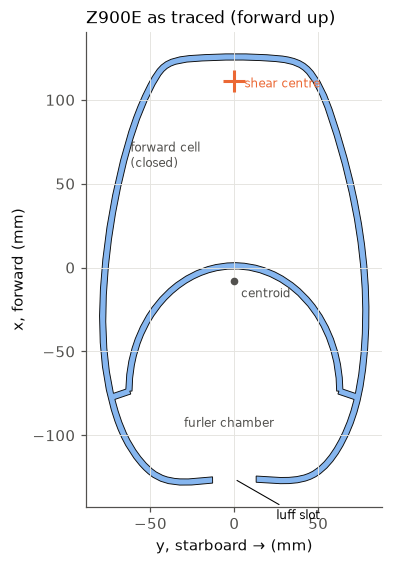

In [6]:
from scipy.interpolate import splprep, splev
from shapely.geometry import Polygon as ShPolygon, LineString, box as sh_box
from shapely.ops import unary_union
from sectionproperties.pre.geometry import Geometry

# Right half of the Z900E outline, traced from the owner's drawing in drawing pixels (x right, y down;
# forward is up). Scaled separately in x and y to the stated 160 mm width and 255 mm chord.
Z900E_OUTLINE_PX = [(172, 42), (205, 43), (238, 50), (252, 64), (266, 95), (280, 135), (291, 180), (297, 225),
                    (298, 265), (296, 300), (289, 335), (277, 362), (262, 382), (248, 394), (172, 397)]
Z900E_ARCH_PX = {"foot_y": 322.0, "apex_y": 218.0, "half_width": 99.0}   # internal wall, a semi-ellipse


def mast_section(p, n=128, mesh=15.0):
    """Closed and slotted elliptical tube. Inputs in mm; returns SI (m^2, m^4) plus the shear-centre offset (m)."""
    a, b, t, s = p.mast_chord, p.mast_width, p.mast_wall, p.mast_slot
    closed = elliptical_hollow_section(d_x=a, d_y=b, t=t, n=n)
    slot = rectangular_section(d=s, b=3 * t).shift_section(x_offset=-a / 2 - 1.5 * t, y_offset=-s / 2)
    out = {}
    for name, g in [("closed", closed), ("slotted", closed - slot)]:
        sec = Section(g.create_mesh(mesh_sizes=[mesh]))
        sec.calculate_geometric_properties()
        sec.calculate_warping_properties()
        cx, cy = sec.get_c()
        ixx, iyy, _ = sec.get_ic()          # ixx = int y^2 dA (athwart bending), iyy = int x^2 dA (fore-aft)
        out[name] = {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12,
                     "J": sec.get_j() * 1e-12, "Cw": sec.get_gamma() * 1e-18,
                     "x_sc": (sec.get_sc()[0] - cx) * 1e-3, "section": sec}
    return out


Z900E_IMG = Path("assets/rig-oceanis440-z900e-drawing.jpg")
Z900E_SLOT_WEB_PX = (505, 1335, 625, 1375)     # the drawn web across the luff slot, between the two lip hooks
Z900E_FWD_CUT_PX = (690, 90, 700, 135)         # a cut through the forward face, for the "if it were open" case


def z900e_section(p, forward_closed=True, mesh=4.0):
    """Z900E section from the drawing's pixels; falls back to the eye trace if the image is missing."""
    if not Z900E_IMG.exists():
        return z900e_section_eye(p, forward_closed)
    import contourpy
    from PIL import Image
    from scipy import ndimage as ndi
    from shapely.affinity import affine_transform
    z = (255.0 - np.asarray(Image.open(Z900E_IMG).convert("L")).astype(float)) / 255.0   # 1 = ink
    lab, n = ndi.label(z > 0.5)
    sizes = ndi.sum(z > 0.5, lab, range(1, n + 1))
    z = np.where(ndi.binary_dilation(lab == np.argmax(sizes) + 1, iterations=3), z, 0.0)  # drop scan specks
    cuts = [Z900E_SLOT_WEB_PX] + ([] if forward_closed else [Z900E_FWD_CUT_PX])
    for x0, y0, x1, y1 in cuts:
        z[y0:y1, x0:x1] = 0.0
    z = ndi.gaussian_filter(z, 0.8)
    rings = [ShPolygon(l) for l in contourpy.contour_generator(z=z).lines(0.5) if len(l) > 20]
    rings = [r for r in rings if r.is_valid and r.area > 50]
    ext = max(rings, key=lambda r: r.area)
    holes = [r.exterior.coords for r in rings if r is not ext and ext.contains(r.representative_point())]
    g = ShPolygon(ext.exterior.coords, holes).buffer(0)
    minx, miny, maxx, maxy = g.bounds
    sx, sy = p.mast_width / (maxx - minx), p.mast_chord / (maxy - miny)
    cx_, cy_ = (minx + maxx) / 2, (miny + maxy) / 2
    g = affine_transform(g, [0, -sy, -sx, 0, cy_ * sy, cx_ * sx])      # drawing (right, down) -> (x fwd, y port)
    g = g.simplify(0.05, preserve_topology=True)
    sec = Section(Geometry(g).create_mesh(mesh_sizes=[mesh]))
    sec.calculate_geometric_properties(); sec.calculate_warping_properties()
    cxs, _ = sec.get_c(); ixx, iyy, _ = sec.get_ic()
    return {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12, "J": sec.get_j() * 1e-12,
            "Cw": sec.get_gamma() * 1e-18, "x_sc": (sec.get_sc()[0] - cxs) * 1e-3, "x_c": cxs * 1e-3, "poly": g,
            "method": "pixel trace"}


def z900e_section_eye(p, forward_closed=True, mesh=6.0):
    """Eye-traced Z900E profile (the fallback). Returns SI properties like mast_section(), plus the outline."""
    cx_, y0, y1, xw = 172.0, 42.0, 397.0, 298.0
    sy, sx = p.mast_chord / (y1 - y0), (p.mast_width / 2) / (xw - cx_)
    mm_ = lambda px, py: (((y1 + y0) / 2 - py) * sy, (cx_ - px) * sx)       # x forward, y port
    R = Z900E_OUTLINE_PX
    pts = np.array([mm_(x, y) for x, y in R] + [mm_(2 * cx_ - x, y) for x, y in R[-2:0:-1]])
    tck, _ = splprep([np.r_[pts[:, 0], pts[0, 0]], np.r_[pts[:, 1], pts[0, 1]]], s=2.0, per=True)
    outer = ShPolygon(np.c_[splev(np.linspace(0, 1, 400), tck)].T).buffer(0)
    shell = outer.difference(outer.buffer(-p.mast_wall, join_style=2))
    fx, _ = mm_(cx_, Z900E_ARCH_PX["foot_y"])
    ax_ = (Z900E_ARCH_PX["foot_y"] - Z900E_ARCH_PX["apex_y"]) * sy
    ay_ = Z900E_ARCH_PX["half_width"] * sx
    th = np.linspace(0, np.pi, 120)
    arch = LineString(np.c_[fx + ax_ * np.sin(th), -ay_ * np.cos(th)]).buffer(p.mast_wall / 2, cap_style=2)
    legs = [LineString([(fx, s * (ay_ - 0.5)), (fx - 6.0, s * 80)]).buffer(p.mast_wall / 2, cap_style=2) for s in (1, -1)]
    g = unary_union([shell, arch.intersection(outer.buffer(-0.01))] + [l.intersection(outer) for l in legs])
    x_aft = mm_(cx_, y1)[0]
    g = g.difference(sh_box(x_aft - 1, -p.mast_slot / 2, x_aft + p.mast_wall + 6, p.mast_slot / 2))   # luff slot
    if not forward_closed:
        x_fwd, yj = mm_(cx_, y0)[0], mm_(238.0, 50.0)[1]
        g = g.difference(sh_box(x_fwd - 12, yj - 1.5, x_fwd + 1, yj + 1.5))
    if g.geom_type == "MultiPolygon":
        g = max(g.geoms, key=lambda q: q.area)
    g = g.simplify(0.15, preserve_topology=True)       # the mesher segfaults on buffer micro-segments
    sec = Section(Geometry(g).create_mesh(mesh_sizes=[mesh]))
    sec.calculate_geometric_properties(); sec.calculate_warping_properties()
    cxs, _ = sec.get_c(); ixx, iyy, _ = sec.get_ic()
    return {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12, "J": sec.get_j() * 1e-12,
            "Cw": sec.get_gamma() * 1e-18, "x_sc": (sec.get_sc()[0] - cxs) * 1e-3, "x_c": cxs * 1e-3, "poly": g,
            "method": "eye trace"}


SEC = mast_section(params)                                              # plain-oval estimate (check 1, comparison)
ZTR = {"closed": z900e_section(params, True), "open": z900e_section(params, False)}
J_CHOICE = {"traced": ZTR["closed"]["J"], "traced_open": ZTR["open"]["J"],
            "closed": SEC["closed"]["J"], "open": SEC["slotted"]["J"]}[params.mast_torsion]
if params.mast_override:
    MAST = {k: params.mast_override[k] for k in ("A", "I_fa", "I_ath")}
    MAST["J"] = params.mast_override.get("J", J_CHOICE)
else:
    MAST = {k: ZTR["closed"][k] for k in ("A", "I_fa", "I_ath")}
    MAST["J"] = J_CHOICE

sec_rows = {"maker (used for A and I)": {"A (mm²)": MAST["A"] * 1e6, "I_fa (cm⁴)": MAST["I_fa"] * 1e8,
                                     "I_ath (cm⁴)": MAST["I_ath"] * 1e8, "J (cm⁴)": np.nan, "Cw (cm⁶)": np.nan,
                                     "shear centre fwd of centroid (mm)": np.nan}}
for lab, v in [("Z900E traced, forward cell closed", ZTR["closed"]), ("Z900E traced, if forward face were open", ZTR["open"]),
               ("plain oval, closed", SEC["closed"]), ("plain oval, slotted", SEC["slotted"])]:
    sec_rows[lab] = {"A (mm²)": v["A"] * 1e6, "I_fa (cm⁴)": v["I_fa"] * 1e8, "I_ath (cm⁴)": v["I_ath"] * 1e8,
                 "J (cm⁴)": v["J"] * 1e8, "Cw (cm⁶)": v["Cw"] * 1e12, "shear centre fwd of centroid (mm)": v["x_sc"] * 1e3}
display(pd.DataFrame(sec_rows).T.style.format("{:.4g}", na_rep="—"))


def poly_props(g, mesh=4.0):
    """A, I and J of a shapely section polygon in mm (x forward), returned in SI."""
    sec = Section(Geometry(g.simplify(0.05, preserve_topology=True)).create_mesh(mesh_sizes=[mesh]))
    sec.calculate_geometric_properties(); sec.calculate_warping_properties()
    ixx, iyy, _ = sec.get_ic()
    return {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12, "J": sec.get_j() * 1e-12}


# How well each route to the section matches the maker's A and I. "Thickened" grows every wall of the pixel
# trace by the same amount until its area equals the maker's, to test whether the drawing's line weight
# explains the shortfall on its own.
if params.mast_override:
    from scipy.optimize import brentq
    g0 = ZTR["closed"]["poly"]
    d_thk = brentq(lambda d: g0.buffer(d, join_style=2).area * 1e-6 - MAST["A"], 0.0, 1.0)
    VARIANTS = {"pixel trace (used for J)": ZTR["closed"],
                f"pixel trace, walls +{2*d_thk:.2f} mm": poly_props(g0.buffer(d_thk, join_style=2)),
                "eye trace": z900e_section_eye(params, True),
                "plain oval, closed": SEC["closed"]}
    cmp_rows = {"maker": {"A (mm²)": MAST["A"] * 1e6, "ΔA": 0.0, "I_fa (cm⁴)": MAST["I_fa"] * 1e8, "ΔI_fa": 0.0,
                          "I_ath (cm⁴)": MAST["I_ath"] * 1e8, "ΔI_ath": 0.0, "J (cm⁴)": np.nan}}
    for lab, v in VARIANTS.items():
        cmp_rows[lab] = {"A (mm²)": v["A"] * 1e6, "ΔA": v["A"] / MAST["A"] - 1,
                         "I_fa (cm⁴)": v["I_fa"] * 1e8, "ΔI_fa": v["I_fa"] / MAST["I_fa"] - 1,
                         "I_ath (cm⁴)": v["I_ath"] * 1e8, "ΔI_ath": v["I_ath"] / MAST["I_ath"] - 1,
                         "J (cm⁴)": v["J"] * 1e8}
    CMP_SEC = pd.DataFrame(cmp_rows).T

    def shade(x):                                   # green within 5%, amber within 15%, red beyond
        if not np.isfinite(x):
            return ""
        c = "#c9ecd9" if abs(x) <= 0.05 else "#fbe3a6" if abs(x) <= 0.15 else "#f7c6c5"
        return f"background-color: {c}; color: #0b0b0b"

    display(CMP_SEC.style.format({"A (mm²)": "{:.0f}", "I_fa (cm⁴)": "{:.0f}", "I_ath (cm⁴)": "{:.0f}", "J (cm⁴)": "{:.0f}",
                                  "ΔA": "{:+.1%}", "ΔI_fa": "{:+.1%}", "ΔI_ath": "{:+.1%}"}, na_rep="—")
            .map(shade, subset=["ΔA", "ΔI_fa", "ΔI_ath"])
            .set_caption("Section routes against the maker's figures (Δ = route / maker − 1; "
                         "green within 5%, amber within 15%, red beyond)"))
print(f"Frame uses: A = {MAST['A']*1e6:.0f} mm², I_fa = {MAST['I_fa']*1e8:.0f} cm⁴, I_ath = {MAST['I_ath']*1e8:.0f} cm⁴ "
      f"({'maker' if params.mast_override else 'traced'}); J = {MAST['J']*1e8:.0f} cm⁴ "
      f"({'maker' if params.mast_override and 'J' in params.mast_override else 'mast_torsion = ' + repr(params.mast_torsion)})")

fig, ax = plt.subplots(figsize=(4.4, 5.6))
g = ZTR["closed"]["poly"]
X, Y = g.exterior.xy; ax.fill(-np.array(Y), X, color="#86b6ef", ec="#0b0b0b", lw=0.6)
for ring in g.interiors:
    X, Y = ring.xy; ax.fill(-np.array(Y), X, color="white", ec="#0b0b0b", lw=0.6)
xc, xsc = ZTR["closed"]["x_c"] * 1e3, (ZTR["closed"]["x_c"] + ZTR["closed"]["x_sc"]) * 1e3
ax.plot([0], [xc], "o", color="#52514e", ms=4); ax.text(4, xc - 10, "centroid", fontsize=8, color="#52514e")
ax.plot([0], [xsc], "+", color=C_OPS_PD, ms=14, mew=2); ax.text(6, xsc - 4, "shear centre", fontsize=8, color=C_OPS_PD)
ax.text(-62, 60, "forward cell\n(closed)", fontsize=8, color="#52514e")
ax.text(-30, -95, "furler chamber", fontsize=8, color="#52514e")
ax.annotate("luff slot", (0, -126), xytext=(25, -150), fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.7))
ax.set_aspect("equal"); ax.set_xlabel("y, starboard → (mm)"); ax.set_ylabel("x, forward (mm)")
ax.set_title("Z900E as traced (forward up)", loc="left", fontsize=11)
plt.show()

---
## §3 Geometry, shared by both solvers

`rig_geometry` lays out nodes and members once, in boat axes. Pynite and OpenSees are both built
from it, so they can't drift apart.

- **Mast:** keel-stepped means pinned at the heel and held laterally at the partners. Twist is held
  at the heel. The mesh is no coarser than `h_max`, with a node at every level that matters.
- **Spreaders** are beams cantilevered from the mast. By default the root is free to rotate in the
  vertical plane, as a real spreader bracket is, so the spreader carries end thrust and fore-and-aft
  bending. It takes no vertical load; the wire geometry has to balance that.
- **The shrouds are discontinuous** (`discontinuous = True`, as on the boat). Each side has one V1, a 12 mm
  wire from the chainplate to the lower spreader tip. The cap (V2 to the upper tip, V3 to the masthead,
  10 mm, clamped at the upper tip) and the intermediate (D2, 8 mm, to the upper spreader root) both start
  at that tip, so V1 carries both of their loads. `discontinuous = False` gives continuous caps and
  intermediates, each with its own V1 from the chainplate.
- **Four lowers.** Each side has an **aft lower** (D1, `lower_D1`) from a chainplate aft of the mast
  and a **forward lower** (D1F, `lowerF_D1F`) from one forward of it, both straight to the lower
  spreader root. Between them they hold that point fore-and-aft as well as sideways, which is what stops
  the mast's middle pumping in a seaway. The companion note's §1 explains it.
- **Every wire has its own chainplate node, fully fixed.** Its reaction is that wire's tension, and
  its turnbuckle can be set without dragging the others along.

In [7]:
GROUP_OF = {}   # wire segment name -> group


def rig_geometry(p, segmented_forestay=False):
    nodes, beams, wires, supports = {}, [], [], {}
    zs1, zs2 = (f * p.I for f in p.spreader_z_frac)
    z_head, z_top = p.I, p.I + p.mast_above_hounds
    z_bottom = p.z_heel if p.keel_stepped else 0.0
    z_mainhead = p.z_boom + p.P
    levels = sorted({z_bottom, 0.0, p.z_boom, zs1, zs2, z_mainhead, p.z_boom + p.reef_fraction * p.P, z_head, z_top})
    zlist = [levels[0]]
    for z0, z1 in zip(levels[:-1], levels[1:]):
        n = max(1, math.ceil((z1 - z0) / p.h_max - 1e-9))
        zlist += list(np.linspace(z0, z1, n + 1)[1:])
    mast_nodes = []
    for k, z in enumerate(zlist):
        nm = f"M{k:02d}"
        nodes[nm] = (0.0, 0.0, float(z))
        mast_nodes.append(nm)

    def at(z):
        return min(mast_nodes, key=lambda n: abs(nodes[n][2] - z))

    key = {"bottom": mast_nodes[0], "partners": at(0.0), "boom": at(p.z_boom), "s1": at(zs1), "s2": at(zs2),
           "mainhead": at(z_mainhead), "head": at(z_head), "top": mast_nodes[-1]}
    for a, b in zip(mast_nodes[:-1], mast_nodes[1:]):
        beams.append({"name": f"mast_{a}", "i": a, "j": b, "kind": "mast"})

    # supports: True = fixed, in BOAT axes (ux, uy, uz, rx, ry, rz)
    if p.keel_stepped:
        supports[key["bottom"]] = (True, True, True, False, False, True)
        supports[key["partners"]] = (True, True, False, False, False, False)
    else:
        supports[key["bottom"]] = (True, True, True, False, False, True)

    sw = math.radians(p.sweep_deg)
    for side, s in (("P", 1.0), ("S", -1.0)):
        for k, (zsk, L) in enumerate(zip((zs1, zs2), p.spreader_len), start=1):
            tip = f"T{k}{side}"
            nodes[tip] = (-L * math.sin(sw), s * L * math.cos(sw), zsk)
            beams.append({"name": f"spreader{k}_{side}", "i": key[f"s{k}"], "j": tip, "kind": "spreader"})

        def chain(group, pts, cp_xy):
            cp = f"CP_{group}_{side}"
            nodes[cp] = (cp_xy[0], s * cp_xy[1], 0.0)
            supports[cp] = (True,) * 6
            seq = [cp] + pts
            labels = {"cap": ["V1", "V2", "V3"], "inter": ["V1", "D2"], "lower": ["D1"], "lowerF": ["D1F"]}[group]
            for seg, (a, b) in zip(labels, zip(seq[:-1], seq[1:])):
                nm = f"{group}_{seg}_{side}"
                wires.append({"name": nm, "i": a, "j": b, "group": group,
                              "bottom": a == cp, "side": side})

        chain("cap", [f"T1{side}", f"T2{side}", key["head"]], p.chainplate["cap"])
        if p.discontinuous:                              # D2 starts at the lower spreader tip and is made to length
            wires.append({"name": f"inter_D2_{side}", "i": f"T1{side}", "j": key["s2"], "group": "inter",
                          "bottom": False, "fit": True, "side": side})
        else:
            chain("inter", [f"T1{side}", key["s2"]], p.chainplate["inter"])
        chain("lower", [key["s1"]], p.chainplate["lower"])
        if p.forward_lowers:
            chain("lowerF", [key["s1"]], p.chainplate["lowerF"])
        bs = f"BS_{side}"
        nodes[bs] = (p.backstay_foot[0], s * p.backstay_foot[1], p.backstay_foot[2])
        supports[bs] = (True,) * 6
        wires.append({"name": f"backstay_{side}", "i": bs, "j": key["head"], "group": "backstay",
                      "bottom": True, "side": side})
    nodes["STEM"] = tuple(p.stem)
    supports["STEM"] = (True,) * 6
    # The forestay is one straight member, or a chain of segments when the headsail load is to act along it
    # (the forestay-sag case, §10). Interior nodes have only translational stiffness, so their rotations are held.
    nseg = p.forestay_segments if segmented_forestay else 1
    fs_nodes = ["STEM"]
    for k in range(1, nseg):
        nm = f"FS{k:02d}"
        nodes[nm] = tuple(np.add(p.stem, k / nseg * np.subtract(nodes[key["head"]], p.stem)))
        supports[nm] = (False, False, False, True, True, True)
        fs_nodes.append(nm)
    fs_nodes.append(key["head"])
    for k, (a, b) in enumerate(zip(fs_nodes[:-1], fs_nodes[1:])):
        wires.append({"name": "forestay" if k == 0 else f"forestay_s{k+1:02d}", "i": a, "j": b,
                      "group": "forestay", "bottom": k == 0, "side": "C"})
    for w in wires:
        GROUP_OF[w["name"]] = w["group"]
    return {"nodes": nodes, "beams": beams, "wires": wires, "supports": supports, "key": key, "forestay_nodes": fs_nodes,
            "mast_nodes": mast_nodes, "z": {"s1": zs1, "s2": zs2, "head": z_head, "mainhead": z_mainhead}}


def unit(a, b):
    v = np.subtract(b, a)
    return v / np.linalg.norm(v)


def seg_len(geo, w):
    return float(np.linalg.norm(np.subtract(geo["nodes"][w["j"]], geo["nodes"][w["i"]])))


GEO = rig_geometry(params)
print(f"{len(GEO['nodes'])} nodes, {len(GEO['beams'])} beams ({sum(b['kind']=='mast' for b in GEO['beams'])} mast), "
      f"{len(GEO['wires'])} wire segments")
for side in "P":
    for w in GEO["wires"]:
        if w["side"] in (side, "C"):
            print(f"  {w['name']:<14} {w['i']:>12} -> {w['j']:<6} L = {seg_len(GEO, w):6.3f} m")

55 nodes, 45 beams (41 mast), 15 wire segments
  cap_V1_P           CP_cap_P -> T1P    L =  6.007 m
  cap_V2_P                T1P -> T2P    L =  5.051 m
  cap_V3_P                T2P -> M40    L =  5.247 m
  inter_D2_P              T1P -> M28    L =  5.200 m
  lower_D1_P       CP_lower_P -> M17    L =  6.249 m
  lowerF_D1F_P    CP_lowerF_P -> M17    L =  6.255 m
  backstay_P             BS_P -> M40    L = 18.076 m
  forestay               STEM -> M40    L = 16.840 m


### Spreader tips must push the wire outboard

A spreader does its job only if the wire **bends outward** at the tip, so the tip carries
compression into the spreader. If the tip sits inside the straight line from chainplate to masthead,
the wire pulls the spreader outward and the geometry is wrong. This cell checks that for each tip.

In [8]:
def wire_bend_check(geo):
    n = geo["nodes"]; rows = []
    for k, (a, tip, b) in enumerate([("CP_cap_P", "T1P", "T2P"), ("T1P", "T2P", geo["key"]["head"])], start=1):
        pa, pt, pb = map(np.array, (n[a], n[tip], n[b]))
        f = (pt[2] - pa[2]) / (pb[2] - pa[2])
        y_line = pa[1] + f * (pb[1] - pa[1])
        rows.append({"spreader": k, "tip |y| (m)": abs(pt[1]), "straight-line |y| (m)": abs(y_line),
                     "deflection outboard (mm)": (abs(pt[1]) - abs(y_line)) * 1e3,
                     "wire angle at tip (deg)": math.degrees(math.acos(np.dot(unit(pa, pt), unit(pt, pb))))})
    return pd.DataFrame(rows).set_index("spreader")


BEND = wire_bend_check(GEO)
display(BEND.style.format("{:.3f}"))
assert (BEND["deflection outboard (mm)"] > 0).all(), "a spreader tip is inside the wire line: check spreader lengths"

,tip |y| (m),straight-line |y| (m),deflection outboard (mm),wire angle at tip (deg)
spreader,,,,
1,1.304,1.201,103.282,2.416
2,0.782,0.662,120.051,2.743


---
## §4 Loads: dock tune and the righting-moment case

**Dock tune** has no external load, only turnbuckle shortenings. In Pynite each one is an enforced
displacement of that wire's chainplate node, $\delta$ along the wire axis away from the mast. This is
the lack-of-fit method: closing a turnbuckle by $\delta$ is the same as fitting a wire $\delta$ too
short. OpenSees applies the same $\delta$ as an initial strain $\varepsilon_0 = \delta / L$ in the
bottom segment, a separate route to the same physics.

**Sailing case.** The rig has to carry the heeling moment that the hull's righting moment balances.
Heel is to starboard, so the wind is from port, the port shrouds are to windward, and the sail force
acts toward $-y$.

- Sail force is split between main and headsail **by area**:
  $A_m = \tfrac12 PE$, $A_h = \tfrac12 IJ \cdot (LP/J)$.
- **Main:** spread along the mast from the boom to the head of P. It is triangular by default,
  largest at the boom, because the chord shrinks toward the head. Its centroid is at
  $z_{boom} + P/3$.
- **Headsail:** it is a triangle on the forestay, so its centroid is at $I/3$. Statics puts **1/3 of
  its force at the masthead and 2/3 at the stem**. The stem share goes straight into the hull and
  never loads the rig.
- The pressure is scaled so that the moment about the deck equals $k \cdot RM_{30}$:
  $$F_m\,\bar z_m + F_h\,\tfrac{I}{3} = k\,RM_{30}$$
  Because the stem share acts at deck level, this is also exactly the moment the rig's supports must
  resist. Check 6 confirms it from the reactions.

The distributed main load becomes **consistent nodal loads** element by element: forces and end
couples, statically equivalent to the trapezoid. Both solvers get the same nodal vector.

**What this case leaves out.** It has no fore-and-aft drive force, no sheet or halyard
compression, no forestay sag tension from the genoa in this case (a real forestay carries far more
than the 1/3 share here; §10 runs it), no rig self-weight, no inertia from pitching, and no torsion from the sail entering aft
of the shear centre. Larsson & Eliasson (*Principles of Yacht Design*) and the Nordic Boat Standard
treat foresail-only and reefed-main-only as separate limiting cases. `sail_plan` runs each one
(`"headsail_only"`, `"reefed_main_only"`), and §10 runs them side by side with a gust factor and a
forestay-sag case.

In [9]:
def rm_loads(p, geo, forestay_sag=False):
    """Nodal loads in boat axes {node: [Fx, Fy, Fz, Mx, My, Mz]} for heel to starboard.
    forestay_sag=True spreads the headsail load along a segmented forestay instead of lumping it at its ends."""
    Pm = p.P * (p.reef_fraction if p.sail_plan == "reefed_main_only" else 1.0)     # luff actually set
    A_m = 0.5 * Pm * p.E if p.sail_plan in ("full", "main_only", "reefed_main_only") else 0.0
    A_h = 0.5 * p.I * p.J * p.headsail_LP_over_J if p.sail_plan in ("full", "headsail_only") else 0.0
    c = {"triangular": 1 / 3, "uniform": 1 / 2}[p.main_load_shape]
    zbar_m = p.z_boom + c * Pm
    M_target = p.RM_factor * p.RM30
    pr = M_target / (A_m * zbar_m + A_h * p.I / 3)     # N per m^2 of sail
    F_m, F_h = pr * A_m, pr * A_h
    loads = {n: np.zeros(6) for n in geo["nodes"]}
    e_q = np.array([0.0, -1.0, 0.0])                    # toward starboard
    # main: w(z) along the mast between boom and head of P
    z0, z1 = p.z_boom, p.z_boom + Pm
    if p.main_load_shape == "triangular":
        w = lambda z: 2 * F_m / Pm * (1 - (z - z0) / Pm)
    else:
        w = lambda z: F_m / Pm
    for b in geo["beams"]:
        if b["kind"] != "mast":
            continue
        za, zb = geo["nodes"][b["i"]][2], geo["nodes"][b["j"]][2]
        if za < z0 - 1e-9 or zb > z1 + 1e-9:
            continue
        L, w1, w2 = zb - za, w(za), w(zb)
        e_a = np.array([0.0, 0.0, 1.0])
        mvec = np.cross(e_a, e_q)
        loads[b["i"]][:3] += L * (7 * w1 + 3 * w2) / 20 * e_q
        loads[b["j"]][:3] += L * (3 * w1 + 7 * w2) / 20 * e_q
        loads[b["i"]][3:] += L**2 * (3 * w1 + 2 * w2) / 60 * mvec
        loads[b["j"]][3:] -= L**2 * (2 * w1 + 3 * w2) / 60 * mvec
    if forestay_sag:
        # Triangular luff load, largest at the tack: w(s) = w0 (1 - s/L), the same resultant and the same
        # moment about the deck as the lumped 1/3 + 2/3 split. Truss-consistent nodal forces per segment;
        # the share at the stem node goes straight into the hull support.
        fsn = geo["forestay_nodes"]
        assert len(fsn) > 2, "forestay_sag needs rig_geometry(p, segmented_forestay=True)"
        pts = [np.array(geo["nodes"][n]) for n in fsn]
        s_ = np.concatenate([[0.0], np.cumsum([np.linalg.norm(b - a) for a, b in zip(pts[:-1], pts[1:])])])
        Lf = s_[-1]
        wf = lambda s: 2 * F_h / Lf * (1 - s / Lf)
        for k in range(len(fsn) - 1):
            Ls, w1, w2 = s_[k + 1] - s_[k], wf(s_[k]), wf(s_[k + 1])
            loads[fsn[k]][:3] += Ls * (2 * w1 + w2) / 6 * e_q
            loads[fsn[k + 1]][:3] += Ls * (w1 + 2 * w2) / 6 * e_q
        loads["STEM"][:] = 0.0
    else:
        loads[geo["key"]["head"]][:3] += F_h / 3 * e_q
    info = {"F_main": F_m, "F_head": F_h, "head_share_on_rig": F_h / 3, "pressure_Pa": pr,
            "M_target": M_target, "zbar_main": zbar_m}
    return {n: v for n, v in loads.items() if np.any(v)}, info


LOADS, LINFO = rm_loads(params, GEO)
print(f"main force {LINFO['F_main']/1e3:.2f} kN at z = {LINFO['zbar_main']:.2f} m;  "
      f"headsail {LINFO['F_head']/1e3:.2f} kN (1/3 = {LINFO['head_share_on_rig']/1e3:.2f} kN at masthead);  "
      f"pressure {LINFO['pressure_Pa']:.0f} Pa")
M_check = sum(geo_z * -v[1] for n, v in LOADS.items() for geo_z in [GEO["nodes"][n][2]]) + sum(v[3] for v in LOADS.values())
print(f"moment of nodal loads about the deck = {M_check/1e3:.3f} kN*m   target = {LINFO['M_target']/1e3:.3f} kN*m")

main force 4.62 kN at z = 6.53 m;  headsail 6.23 kN (1/3 = 2.08 kN at masthead);  pressure 124 Pa
moment of nodal loads about the deck = 63.834 kN*m   target = 63.834 kN*m


---
## §5 Pynite model and solver

- **Mast and spreader members** use `add_section(A, Iy, Iz, J)`. For a vertical member Pynite puts
  local $z$ along global $Z$ (athwart), so **$I_z$ is fore-and-aft bending ($I_{fa}$)** and $I_y$ is
  athwart bending. A cantilever test confirmed this: a load along $X$ deflects by $PL^3/3EI_z$.
- **Wires** are `tension_only` members with negligible $I$ and every end moment released. Pynite's
  axial force is **positive in compression**, so tension = −`axial`.
- **Solver:** `analyze_PDelta` throughout, the dock tune included, because the mast carries tens of
  kN of compression from pretension alone. **It is a two-cycle method:** Pynite 1.0.1 stops after
  the second geometric-stiffness update (`while … or iter_count_PD <= 2` in `Analysis._PDelta_step`)
  rather than iterating to convergence. Its global force residual is the measure of what that costs:
  about 3e-4 of the load here (check 5). The OpenSees corotational run in §9 is the reference, and
  it agrees to better than 1%.

**Dock tune by Newton iteration.** The unknowns are the turnbuckle shortenings
$\boldsymbol\delta = (\delta_{cap}, \delta_{inter}, \delta_{lower}, \delta_{lowerF}, \delta_{backstay})$,
and the targets are five gauged tensions. The aft and forward lowers have a turnbuckle each, so the tune
can set the forward pair tighter than the aft.

**The discontinuous shrouds are tuned like the real ones.** The V1 deck turnbuckle is the cap's adjuster;
it's gauged on V2, the cap's own 10 mm wire, at 20% of its MBL (14.2 kN). D2 has no turnbuckle: it's made
to length, and the tune finds the length that puts 15% of its MBL in it (6.8 kN). That length is a lack of
fit between two free nodes, which Pynite can't impose by moving a support. So it goes in as end forces
$F = EA\delta/L$ pulling D2's ends together, with $F$ added back to the force Pynite reports. A linear run
of each solver agrees on every tension, so the method is exact. One cost remains: Pynite's P-Delta builds
D2's geometric stiffness from its own force, which leaves $F$ out, so it understates the second-order sway
a little (§9). D2 isn't tension-only in Pynite for the same reason, and check 13 confirms it never goes
slack. The Jacobian comes from unit perturbations. When every
wire stays taut the response is very nearly linear, and it converges in one or two steps.

In [10]:
TARGET_OF = {"cap": "cap", "inter": "inter", "lower": "lower", "lowerF": "lowerF",   # tension each turnbuckle sets
             "backstay": "forestay"}


def tuned_groups(p):
    """The turnbuckles the tune solves for: one per shroud group, and the backstay adjuster. In a discontinuous rig the
    V1 deck turnbuckle tunes the cap, and the intermediate's unknown is the length D2 is made to."""
    return ("cap", "inter", "lower") + (("lowerF",) if p.forward_lowers else ()) + ("backstay",)


def gauge_wire(p, geo, g):
    """The segment whose tension turnbuckle g is tuned to: the group's bottom segment, where a Loos gauge would go, except
    that a discontinuous cap is gauged on V2, its own 10 mm wire above the lower spreader tip."""
    if g == "cap" and p.discontinuous:
        return next(w for w in geo["wires"] if w["name"] == "cap_V2_P")
    if g == "inter" and p.discontinuous:
        return next(w for w in geo["wires"] if w["name"] == "inter_D2_P")
    return next(w for w in geo["wires"] if w["group"] == TARGET_OF[g] and w["bottom"] and w["side"] in ("P", "C"))


TUNED = tuned_groups(params)


def build_pynite(p, geo, sec, deltas, loads=None):
    m = FEModel3D()
    m.fit_force = {}                                      # made-to-length wires: tension to add back (N)
    m.add_material("Al", p.E_al, p.G_al, 0.33, 2700)
    m.add_material("Wire", p.E_wire, p.E_wire / 2.6, 0.3, 7950)
    m.add_section("mast", sec["A"], sec["I_ath"], sec["I_fa"], sec["J"])
    ss = p.spreader_section
    m.add_section("spreader", ss["A"], ss["I_horiz"], ss["I_vert"], ss["J"])
    for nm, xyz in geo["nodes"].items():
        m.add_node(nm, *to_solver(xyz))
    for nm, fix in geo["supports"].items():
        t = to_solver(fix[:3]); r = to_solver(fix[3:])
        m.def_support(nm, *(bool(abs(v)) for v in t), *(bool(abs(v)) for v in r))
    for nm in geo["forestay_nodes"][1:-1]:
        # Pynite's first P-Delta cycle takes zero axial force, so a chain of pin-ended wire segments has no
        # sideways stiffness at its interior nodes. A 1 N/m spring removes the singularity; the wire's own
        # string stiffness there (T/L, about 1e4 N/m) is four orders larger.
        for dof in ("DX", "DY", "DZ"):
            m.def_support_spring(nm, dof, 1.0)
    for b in geo["beams"]:
        m.add_member(b["name"], b["i"], b["j"], "Al", b["kind"])
        if b["kind"] == "spreader" and p.release_spreader_root:
            m.def_releases(b["name"], Rzi=True)          # local z is horizontal for a horizontal member
    for w in geo["wires"]:
        size = wire_size(p, w)
        sname = f"wire_{size}"
        if sname not in m.sections:
            m.add_section(sname, wire_props(size)["A"], 1e-12, 1e-12, 1e-12)
        m.add_member(w["name"], w["i"], w["j"], "Wire", sname, tension_only=not w.get("fit"))
        m.def_releases(w["name"], Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True)
        if w.get("fit"):
            # Made to length between two free nodes: a lack of fit delta is the same as end forces F = EA delta / L pulling
            # the ends together, plus F added back to the member's own force. Not tension-only, because Pynite would judge
            # slackness on its own force, which leaves out F; check 13 confirms these wires stay taut.
            dfit = deltas.get(w["group"], 0.0)
            F = wire_props(size)["A"] * p.E_wire * dfit / seg_len(geo, w)
            m.fit_force[w["name"]] = F
            u = unit(geo["nodes"][w["i"]], geo["nodes"][w["j"]])
            for node, sgn in ((w["i"], 1.0), (w["j"], -1.0)):
                for comp, val in zip(("FX", "FY", "FZ"), to_solver(sgn * F * u)):
                    if abs(val) > 0:
                        m.add_node_load(node, comp, float(val), case="Fit")
            continue
        d = deltas.get(w["group"], 0.0) if w["bottom"] else 0.0
        if d:
            cp = w["i"]                                   # chainplate end
            other = w["j"]
            u = unit(geo["nodes"][cp], geo["nodes"][other])
            disp = to_solver(-d * u)                      # pull the chainplate away from the mast
            for comp, val in zip(("DX", "DY", "DZ"), disp):
                m.def_node_disp(cp, comp, float(val))
    m.add_load_combo("Dock", {"Fit": 1.0})
    if loads:
        for nm, v in loads.items():
            F, M = to_solver(v[:3]), to_solver(v[3:])
            for comp, val in zip(("FX", "FY", "FZ", "MX", "MY", "MZ"), (*F, *M)):
                if abs(val) > 0:
                    m.add_node_load(nm, comp, float(val), case="Sail")
        m.add_load_combo("RM", {"Sail": 1.0, "Fit": 1.0})
    return m


def pynite_tensions(m, geo, combo):
    out = {}
    for w in geo["wires"]:
        mem = m.members[w["name"]]
        out[w["name"]] = 0.0 if not mem.active.get(combo, True) else -mem.axial(mem.L() / 2, combo) + \
            getattr(m, "fit_force", {}).get(w["name"], 0.0)
    return out


def solve_pynite(p, geo, sec, deltas, loads=None, pdelta=True):
    m = build_pynite(p, geo, sec, deltas, loads)
    # Coincident chainplate nodes make Pynite's "is this node on the member?" angle test divide 0/0.
    # It returns NaN, which correctly means "no", so the warning is noise.
    with np.errstate(invalid="ignore"):
        (m.analyze_PDelta if pdelta else m.analyze)(check_stability=False)
    return m


def tune(p, geo, sec, pdelta=True, tol=1.0, max_iter=8, verbose=False):
    """Turnbuckle shortenings (m) that put the target tension in each tuned group's bottom segment."""
    groups = tuned_groups(p)
    probe_w = {g: gauge_wire(p, geo, g) for g in groups}
    probe = {g: w["name"] for g, w in probe_w.items()}
    # the target is a share of the gauged segment's own MBL
    target = np.array([p.pretension_pct[TARGET_OF[g]] / 100 * wire_props(wire_size(p, probe_w[g]))["MBL"] for g in groups])

    def T_of(dvec):
        m = solve_pynite(p, geo, sec, dict(zip(groups, dvec)), None, pdelta)
        t = pynite_tensions(m, geo, "Dock")
        return np.array([t[probe[g]] for g in groups])

    # Start from each wire's own stretch, T L / EA, so every wire is taut. At delta = 0 every wire is
    # slack, and a tension-only Jacobian taken there is meaningless.
    # (the forestay counts its whole length, segmented or not)
    def L0(g):
        if TARGET_OF[g] == "forestay":
            return sum(seg_len(geo, w) for w in geo["wires"] if w["group"] == "forestay")
        return seg_len(geo, next(w for w in geo["wires"] if w["name"] == probe[g]))
    d = np.array([target[k] * L0(g) / (wire_props(wire_size(p, probe_w[g]))["A"] * p.E_wire)
                  for k, g in enumerate(groups)])
    T, h = T_of(d), 2e-4
    for it in range(max_iter):
        Jm = np.column_stack([(T_of(d + h * np.eye(len(groups))[k]) - T) / h for k in range(len(groups))])
        step = np.linalg.solve(Jm, target - T)
        for _ in range(6):                                # halve the step if a wire goes slack and the error grows
            T_new = T_of(d + step)
            if np.max(np.abs(T_new - target)) < np.max(np.abs(T - target)):
                break
            step = step / 2
        d, T = d + step, T_new
        if verbose:
            print(f"  iter {it+1}: max |T - target| = {np.max(np.abs(T - target)):.3e} N")
        if np.max(np.abs(T - target)) < tol:
            break
    return dict(zip(groups, d)), dict(zip(groups, T)), dict(zip(groups, target))


t0 = time.perf_counter()
DELTAS, T_TUNED, T_TARGET = tune(params, GEO, MAST, verbose=True)
print(f"tuned in {time.perf_counter()-t0:.1f} s")
display(pd.DataFrame({"sets tension in": [TARGET_OF[g] for g in TUNED],
                      "gauged on": [gauge_wire(params, GEO, g)["name"] for g in TUNED],
                      "wire": [wire_size(params, gauge_wire(params, GEO, g)) for g in TUNED],
                      "target (% MBL)": [params.pretension_pct[TARGET_OF[g]] for g in TUNED],
                      "target (kN)": [T_TARGET[g] / 1e3 for g in TUNED],
                      "achieved (kN)": [T_TUNED[g] / 1e3 for g in TUNED],
                      "turnbuckle shortening (mm)": [DELTAS[g] * 1e3 for g in TUNED]},
                     index=[f"{g} turnbuckle" for g in TUNED])
        .style.format({"target (% MBL)": "{:.0f}", "target (kN)": "{:.2f}", "achieved (kN)": "{:.2f}",
                       "turnbuckle shortening (mm)": "{:.2f}"}))

  iter 1: max |T - target| = 2.148e+02 N


  iter 2: max |T - target| = 3.220e-02 N
tuned in 9.4 s


,sets tension in,gauged on,wire,target (% MBL),target (kN),achieved (kN),turnbuckle shortening (mm)
cap turnbuckle,cap,cap_V2_P,10 mm,20,14.22,14.22,37.35
inter turnbuckle,inter,inter_D2_P,8 mm,15,6.83,6.83,-12.37
lower turnbuckle,lower,lower_D1_P,12 mm,11,11.22,11.22,8.79
lowerF turnbuckle,lowerF,lowerF_D1F_P,10 mm,12,8.53,8.53,9.18
backstay turnbuckle,forestay,forestay,10 mm,20,14.22,14.22,72.65


The **turnbuckle shortening** is the total length taken out of the wire by the turnbuckle, from
just slack to tuned. Its size follows from the stretch figure in §1 (about 1.2 mm/m at 15% MBL),
plus the mast shortening under compression. Constructional stretch is extra and isn't modelled.

In [11]:
M_PY = solve_pynite(params, GEO, MAST, DELTAS, LOADS, pdelta=True)


def pynite_results(m, geo, combo):
    disp = {n: to_boat((m.nodes[n].DX[combo], m.nodes[n].DY[combo], m.nodes[n].DZ[combo])) for n in geo["nodes"]}
    rx = {n: np.array([*to_boat((m.nodes[n].RxnFX[combo], m.nodes[n].RxnFY[combo], m.nodes[n].RxnFZ[combo])),
                       *to_boat((m.nodes[n].RxnMX[combo], m.nodes[n].RxnMY[combo], m.nodes[n].RxnMZ[combo]))])
          for n in geo["supports"]}
    mast_N = {b["i"]: m.members[b["name"]].axial(m.members[b["name"]].L() / 2, combo)
              for b in geo["beams"] if b["kind"] == "mast"}
    return {"T": pynite_tensions(m, geo, combo), "disp": disp, "rxn": rx, "mast_N": mast_N}


RES = {c: pynite_results(M_PY, GEO, c) for c in ("Dock", "RM")}

---
## §6 Results: wire tensions and safety factors

SF is the wire's design MBL (the lowest catalog value) divided by its tension. Windward (port)
shrouds load up and leeward (starboard) ones unload. A leeward wire that reaches zero has gone
**slack**: it carries nothing, and the mast is unsupported on that side.

In [12]:
def tension_table(res_dock, res_rm, geo, p):
    rows = []
    for w in geo["wires"]:
        mbl = wire_props(wire_size(p, w))["MBL"]
        td, tr = res_dock["T"][w["name"]], res_rm["T"][w["name"]]
        rows.append({"segment": w["name"], "wire": wire_size(p, w), "MBL (kN)": mbl / 1e3,
                     "dock (kN)": td / 1e3, "RM case (kN)": tr / 1e3,
                     "RM % MBL": 100 * tr / mbl, "SF (RM)": mbl / tr if tr > 1 else np.inf,
                     "slack in RM case": "SLACK" if tr < 1.0 else ""})
    return pd.DataFrame(rows).set_index("segment")


TT = tension_table(RES["Dock"], RES["RM"], GEO, params)
display(TT.style.format({"MBL (kN)": "{:.1f}", "dock (kN)": "{:.2f}", "RM case (kN)": "{:.2f}",
                         "RM % MBL": "{:.1f}", "SF (RM)": "{:.2f}"}))

head = GEO["key"]["head"]
dh = RES["RM"]["disp"][head]
Nmax = {c: max(RES[c]["mast_N"].values()) for c in RES}
print(f"masthead displacement, RM case: fwd {dh[0]*1e3:+.1f} mm, port {dh[1]*1e3:+.1f} mm, up {dh[2]*1e3:+.2f} mm")
print(f"max mast compression: dock {Nmax['Dock']/1e3:.1f} kN, RM case {Nmax['RM']/1e3:.1f} kN")

,wire,MBL (kN),dock (kN),RM case (kN),RM % MBL,SF (RM),slack in RM case
segment,,,,,,,
cap_V1_P,12 mm,102.0,20.77,30.55,29.9,3.34,
cap_V2_P,10 mm,71.1,14.22,20.78,29.2,3.42,
cap_V3_P,10 mm,71.1,14.32,20.94,29.4,3.40,
inter_D2_P,8 mm,45.5,6.83,10.23,22.5,4.45,
lower_D1_P,12 mm,102.0,11.22,16.11,15.8,6.33,
lowerF_D1F_P,10 mm,71.1,8.53,11.75,16.5,6.05,
backstay_P,8 mm,45.5,3.03,4.53,10.0,10.04,
cap_V1_S,12 mm,102.0,20.77,10.97,10.8,9.30,
cap_V2_S,10 mm,71.1,14.22,7.65,10.8,9.30,


masthead displacement, RM case: fwd -122.4 mm, port -99.8 mm, up -5.26 mm
max mast compression: dock 98.3 kN, RM case 98.3 kN


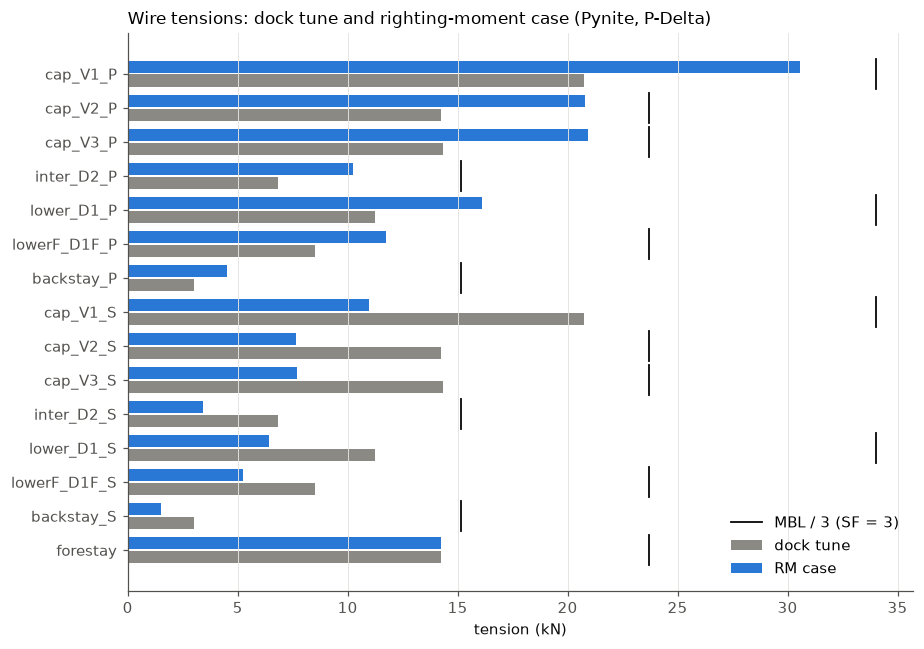

In [13]:
def plot_tensions(tt):
    segs = list(tt.index)
    y = np.arange(len(segs))
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(segs) + 1.2))
    ax.barh(y + 0.2, tt["dock (kN)"], height=0.36, color=C_GREY, label="dock tune")
    ax.barh(y - 0.2, tt["RM case (kN)"], height=0.36, color=C_PYNITE, label="RM case")
    for k, s in enumerate(segs):
        ax.plot([tt.loc[s, "MBL (kN)"] / 3] * 2, [k - 0.45, k + 0.45], color="#0b0b0b", lw=1.2)
    ax.plot([], [], color="#0b0b0b", lw=1.2, label="MBL / 3 (SF = 3)")
    ax.set_yticks(y, segs); ax.invert_yaxis()
    ax.set_xlabel("tension (kN)"); ax.grid(axis="y", visible=False)
    ax.set_title("Wire tensions: dock tune and righting-moment case (Pynite, P-Delta)", loc="left", fontsize=11)
    ax.legend(loc="lower right", frameon=False)
    plt.tight_layout(); plt.show()


plot_tensions(TT)

### What the tensions show (default placeholders)

- **The windward V1 is the most loaded wire:** about 30.6 kN in 12 mm wire, SF ≈ 3.3. In the discontinuous
  rig it carries the cap and the intermediate together, so it reads about the sum of V2 (20.8 kN) and D2
  (10.2 kN).
- **Above the lower spreader the cap carries about 21 kN** (V2, V3: SF ≈ 3.4), and **D2 about 10 kN** (SF ≈
  4.5). D2 is made to the length that gives it 15% of its MBL at the dock.
- **The two windward lowers share the lower spreader root's load:** 16.1 kN in the 12 mm aft lower and
  11.8 kN in the 10 mm forward one. To leeward they drop to 6.4 and 5.2 kN from 11.2 and 8.5. Nothing goes
  slack in this case; riggers check leeward slackness at 15–20° of heel.
- **The forestay hardly changes** (about 14.2 kN) because only the 1/3 headsail share at the masthead
  enters the model. A real forestay under a loaded genoa sags, and its tension rises a lot. §10's
  forestay-sag case shows it doubling.
- **These SFs are against MBL.** Rigging practice usually wants about 2.5–3 on the windward shrouds
  at $RM_{30}$. The real margins depend on $GZ_{30}$, the chainplate span and the wire certificates,
  which are mostly placeholders here.

---
## §7 Mast bend and the deformed rig

Displacements are measured from the **as-drawn geometry, in which every wire is stress-free**. So
the masthead moves aft at the dock mainly because the forestay stretches under its own tune (about
30 mm at 14 kN on 16.8 m) and the mast shortens. That's **rake**, set on a real boat by the forestay
length. The bend plot removes it by measuring from the chord through the partners and the
masthead, which is what you see sighting up the mast.

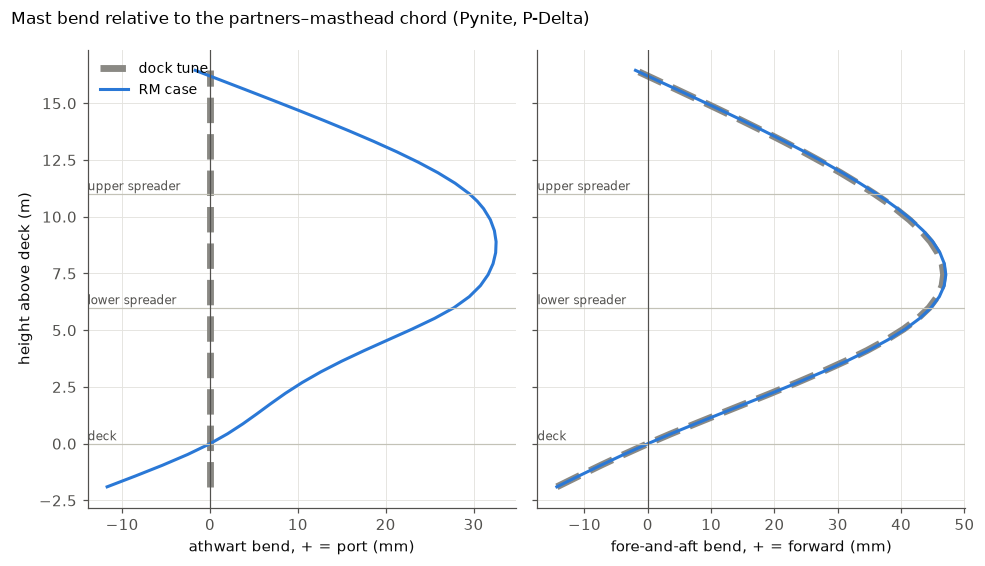

Dock: masthead moves -122.4 mm fwd,   +0.0 mm port (chord rake +0.43° aft)
RM  : masthead moves -122.4 mm fwd,  -99.8 mm port (chord rake +0.43° aft)


In [14]:
def mast_curve(res, geo, comp, chord=True):
    """Mast displacement along `comp` against height. chord=True subtracts the straight line through the
    partners (z = 0) and the masthead, leaving the bend a sailor sees by sighting up the mast."""
    zs = np.array([geo["nodes"][n][2] for n in geo["mast_nodes"]])
    u = np.array([res["disp"][n][comp] for n in geo["mast_nodes"]])
    if chord:
        h = geo["key"]["head"]
        u = u - res["disp"][h][comp] * zs / geo["nodes"][h][2]
    return zs, u


def plot_bend(curves, title):
    fig, axs = plt.subplots(1, 2, figsize=(9, 5.2), sharey=True)
    for ax, comp, lab in zip(axs, (1, 0), ("athwart bend, + = port (mm)", "fore-and-aft bend, + = forward (mm)")):
        for k, (name, (res, color, ls)) in enumerate(curves.items()):
            z, u = mast_curve(res, GEO, comp)
            ax.plot(u * 1e3, z, color=color, ls=ls, label=name, lw=4.5 if k == 0 else 2.0,
                    alpha=0.45 if k == 0 and len(curves) > 2 else 1.0)
        for zz, t in [(GEO["z"]["s1"], "lower spreader"), (GEO["z"]["s2"], "upper spreader"), (0.0, "deck")]:
            ax.axhline(zz, color="#c3c2b7", lw=0.8)
            ax.text(ax.get_xlim()[0], zz + 0.15, t, fontsize=8, color="#52514e")
        ax.axvline(0, color="#52514e", lw=0.8)
        ax.set_xlabel(lab)
    axs[0].set_ylabel("height above deck (m)")
    axs[0].legend(frameon=False, loc="upper left", fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()


plot_bend({"dock tune": (RES["Dock"], C_GREY, "--"), "RM case": (RES["RM"], C_PYNITE, "-")},
          "Mast bend relative to the partners–masthead chord (Pynite, P-Delta)")
for c in ("Dock", "RM"):
    d_ = RES[c]["disp"][head]
    print(f"{c:4s}: masthead moves {d_[0]*1e3:+6.1f} mm fwd, {d_[1]*1e3:+6.1f} mm port "
          f"(chord rake {math.degrees(math.atan2(-d_[0], GEO['nodes'][head][2])):+.2f}° aft)")

**Linear against P-Delta.** The same model run linear is shown below. With the defaults the
difference is small, about 2% in masthead sway and under 1% in tension, because the first buckling
factor is about 3.8 (§8). The amplification of sway by the axial load grows as
$1/(1 - 1/\lambda)$, so it becomes large only as $\lambda$ approaches 1. That happens with a
harder tune, a weaker section, or `mast_torsion = "open"`. P-Delta stays on because it costs
almost nothing and it is the safe default.

In [15]:
M_LIN = solve_pynite(params, GEO, MAST, DELTAS, LOADS, pdelta=False)
RES_LIN = {c: pynite_results(M_LIN, GEO, c) for c in ("Dock", "RM")}
display(pd.DataFrame({"linear": {"masthead athwart (mm)": RES_LIN["RM"]["disp"][head][1] * 1e3,
                                 "upper spreader root athwart (mm)": RES_LIN["RM"]["disp"][GEO["key"]["s2"]][1] * 1e3,
                                 "windward cap V1 (kN)": RES_LIN["RM"]["T"]["cap_V1_P"] / 1e3,
                                 "leeward lower D1 (kN)": RES_LIN["RM"]["T"]["lower_D1_S"] / 1e3},
                      "P-Delta": {"masthead athwart (mm)": RES["RM"]["disp"][head][1] * 1e3,
                                  "upper spreader root athwart (mm)": RES["RM"]["disp"][GEO["key"]["s2"]][1] * 1e3,
                                  "windward cap V1 (kN)": RES["RM"]["T"]["cap_V1_P"] / 1e3,
                                  "leeward lower D1 (kN)": RES["RM"]["T"]["lower_D1_S"] / 1e3}})
        .style.format("{:.1f}").set_caption("RM case, Pynite"))

,linear,P-Delta
masthead athwart (mm),-98.9,-99.8
upper spreader root athwart (mm),-40.5,-38.4
windward cap V1 (kN),30.5,30.6
leeward lower D1 (kN),5.8,6.4


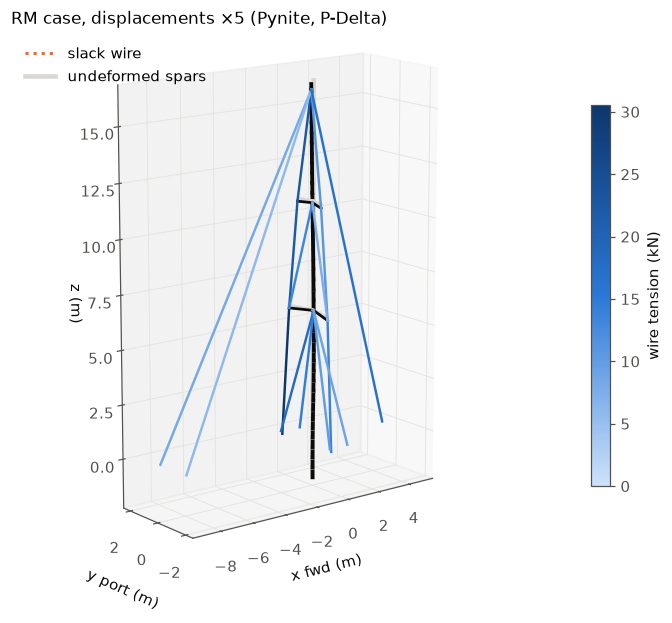

In [16]:
def plot_rig3d(geo, res, scale=20.0, title=""):
    n = geo["nodes"]
    P_ = lambda nm, s=0.0: np.add(n[nm], s * np.array(res["disp"][nm]))
    Tmax = max(res["T"].values())
    cmap = mcolors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
    fig = plt.figure(figsize=(8, 9)); ax = fig.add_subplot(projection="3d")
    for b in geo["beams"]:
        a0, b0 = P_(b["i"]), P_(b["j"]); a1, b1 = P_(b["i"], scale), P_(b["j"], scale)
        ax.plot(*zip(a0, b0), color="#d8d7d2", lw=3 if b["kind"] == "mast" else 2)
        ax.plot(*zip(a1, b1), color="#0b0b0b", lw=2.5 if b["kind"] == "mast" else 1.8)
    for w in geo["wires"]:
        t = res["T"][w["name"]]
        a1, b1 = P_(w["i"], scale), P_(w["j"], scale)
        if t < 1.0:
            ax.plot(*zip(a1, b1), color=C_OPS_PD, lw=1.2, ls=":")
        else:
            ax.plot(*zip(a1, b1), color=cmap(0.15 + 0.85 * t / Tmax), lw=1.6)
    ax.plot([], [], color=C_OPS_PD, ls=":", label="slack wire")
    ax.plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    ax.set_xlabel("x fwd (m)"); ax.set_ylabel("y port (m)"); ax.set_zlabel("z (m)")
    xs = [v[0] for v in n.values()]; ys = [v[1] for v in n.values()]; zs = [v[2] for v in n.values()]
    ax.set_ylim(-2.5, 2.5); ax.set_yticks([-2, 0, 2])
    ax.set_box_aspect((np.ptp(xs), 5.0, np.ptp(zs)))
    ax.view_init(elev=14, azim=-128)                     # from forward, on the starboard bow
    sm = cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(0, Tmax / 1e3))
    fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, label="wire tension (kN)")
    ax.legend(loc="upper left", frameon=False)
    ax.set_title(title, loc="left", fontsize=11)
    plt.show()


plot_rig3d(GEO, RES["RM"], scale=5, title="RM case, displacements ×5 (Pynite, P-Delta)")

---
## §8 Buckling: linear eigenvalue from Pynite's $K$ and $K_g$

After the P-Delta solve, Pynite's `Kg(first_step=False)` builds the geometric stiffness from each
member's axial force. The buckling load factor $\lambda$ is the smallest positive root of

$$\left(K + \lambda K_g\right)\phi = 0$$

taken over the free DOFs (`Pynite.Analysis._partition_D`). $\lambda$ scales **every** axial force
together: mast compression and wire tension, pretension included. "λ = 3" means the rig would buckle
if the whole stress state, tune and sail load alike, were three times larger.

Each mode is labelled **flexural** or **torsional** according to whether mast sway or twist (times the
half-chord) dominates its shape.

For comparison, the hand estimate treats each mast panel as a pinned Euler column between
supports: $P_{cr} = \pi^2 E I / L^2$, using the weaker axis and the panel's peak compression.
Spreaders and partners aren't truly pinned, so this is only a rough guide.

**Torsional-flexural check (open section).** The frame can't do this one (§2), so it's done by hand
per panel. The section is symmetric about the fore-aft axis, and its shear centre lies on that axis
at $x_0$, so twist couples with athwart bending. Timoshenko & Gere's result, in the form AISC uses
for singly-symmetric members:

$$P_T = \frac{GJ + \pi^2 E C_w / L^2}{r_0^2},\qquad r_0^2 = x_0^2 + \frac{I_{fa} + I_{ath}}{A},\qquad H = 1 - \frac{x_0^2}{r_0^2}$$

$$P_{TF} = \frac{P_e + P_T}{2H}\left[1 - \sqrt{1 - \frac{4 P_e P_T H}{(P_e + P_T)^2}}\right],\qquad P_e = \frac{\pi^2 E I_{ath}}{L^2}$$

with each panel taken as pinned and free to warp at the spreaders.

In [17]:
def buckling_factor(m, combo, nmodes=3):
    D1, _, _ = _partition_D(m)
    K = m.K(combo, sparse=True, check_stability=False).toarray()
    Kg = m.Kg(combo, sparse=True, first_step=False).toarray()   # Pynite 1.0.1's dense branch has a zeros(n, n) bug
    K11, Kg11 = K[np.ix_(D1, D1)], Kg[np.ix_(D1, D1)]
    # A slack leeward cap is switched off, which can leave a spreader tip held only by its released root: a
    # mechanism with no stiffness. Its eigenpair is 0/0 and the solver returns noise for it (λ = 0.04 was seen),
    # so solve on the part of the DOF space that K actually stiffens.
    w, V = np.linalg.eigh(0.5 * (K11 + K11.T))
    Q = V[:, w > 1e-9 * w.max()]
    vals, vr = sla.eig(Q.T @ K11 @ Q, -(Q.T @ Kg11 @ Q))
    vecs = Q @ vr
    vals = np.real_if_close(vals)
    ok = np.isfinite(vals) & (np.abs(np.imag(vals)) < 1e-9) & (np.real(vals) > 1e-6)
    order = np.argsort(np.real(vals[ok]))
    lam = np.real(vals[ok])[order][:nmodes]
    phi = np.real(vecs[:, ok][:, order[:nmodes]])
    full = np.zeros((len(m.nodes) * 6, phi.shape[1])); full[D1, :] = phi
    return lam, full


def euler_panels(p, geo, res, sec):
    zl = [0.0 if p.keel_stepped else geo["nodes"][geo["key"]["bottom"]][2], geo["z"]["s1"], geo["z"]["s2"], geo["z"]["head"]]
    rows = []
    for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), ("deck–lower spr.", "lower–upper spr.", "upper spr.–head")):
        N = max(v for n, v in res["mast_N"].items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
        L = zb - za
        Pcr = math.pi**2 * p.E_al * min(sec["I_fa"], sec["I_ath"]) / L**2
        rows.append({"panel": nm, "L (m)": L, "peak N (kN)": N / 1e3, "Euler Pcr (kN)": Pcr / 1e3, "Pcr / N": Pcr / N})
    return pd.DataFrame(rows).set_index("panel")


def mode_kind(m, geo, phi, k, r_twist):
    """'flexural' if mast sway dominates, 'torsional' if twist about the mast axis (times r_twist) does."""
    ids = [m.nodes[n].ID for n in geo["mast_nodes"]]
    sway = max(np.hypot(phi[i * 6 + 0, k], phi[i * 6 + 2, k]) for i in ids)      # solver X and Z
    twist = max(abs(phi[i * 6 + 4, k]) for i in ids) * r_twist                   # rotation about solver Y (up)
    return "flexural" if sway >= twist else "torsional"


LAM, PHI = buckling_factor(M_PY, "RM", 6)
LAM_DOCK, PHI_DOCK = buckling_factor(M_PY, "Dock", 6)
r_tw = params.mast_chord / 2e3
KINDS = [mode_kind(M_PY, GEO, PHI, k, r_tw) for k in range(len(LAM))]
display(pd.DataFrame({"λ RM case": LAM, "kind (RM)": KINDS,
                      "λ dock": LAM_DOCK, "kind (dock)": [mode_kind(M_PY, GEO, PHI_DOCK, k, r_tw) for k in range(len(LAM_DOCK))]},
                     index=pd.RangeIndex(1, len(LAM) + 1, name="mode")).style.format({"λ RM case": "{:.2f}", "λ dock": "{:.2f}"}))
display(euler_panels(params, GEO, RES["RM"], MAST).style.format("{:.2f}"))


def torsional_flexural(p, geo, res, sec_props):
    """Open-section check per panel (Timoshenko & Gere; the AISC E4 form). The section is symmetric about
    the fore-aft axis, with its shear centre on that axis, so twist couples with athwart bending."""
    zl = [0.0, geo["z"]["s1"], geo["z"]["s2"], geo["z"]["head"]]
    rows = []
    for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), ("deck–lower spr.", "lower–upper spr.", "upper spr.–head")):
        N = max(v for n, v in res["mast_N"].items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
        L = zb - za
        for label, sp in sec_props.items():
            A, x0 = sp["A"], sp["x_sc"]
            r0sq = x0**2 + (sp["I_fa"] + sp["I_ath"]) / A
            H = 1 - x0**2 / r0sq
            Pe = math.pi**2 * p.E_al * sp["I_ath"] / L**2
            PT = (p.G_al * sp["J"] + math.pi**2 * p.E_al * sp["Cw"] / L**2) / r0sq
            PTF = (Pe + PT) / (2 * H) * (1 - math.sqrt(1 - 4 * Pe * PT * H / (Pe + PT)**2))
            rows.append({"panel": nm, "section": label, "peak N (kN)": N / 1e3, "P_T (kN)": PT / 1e3,
                         "P_TF (kN)": PTF / 1e3, "P_TF / N": PTF / N})
    return pd.DataFrame(rows).set_index(["panel", "section"])


# the maker's A and I with the traced J, Cw and shear centre: the best available description of the real mast
AI = {k: MAST[k] for k in ("A", "I_fa", "I_ath")}
TF_SECS = {"Z900E, forward cell closed": {**ZTR["closed"], **AI},
           "Z900E if the forward face were open": {**ZTR["open"], **AI},
           "plain oval, slotted (old estimate)": SEC["slotted"]}
TF = torsional_flexural(params, GEO, RES["RM"], TF_SECS)
display(TF.style.format("{:.2f}"))

,λ RM case,kind (RM),λ dock,kind (dock)
mode,,,,
1,3.83,flexural,3.83,flexural
2,6.03,flexural,6.06,flexural
3,6.25,flexural,6.64,flexural
4,8.32,flexural,8.29,flexural
5,9.64,flexural,9.94,flexural
6,10.73,flexural,11.08,flexural


,L (m),peak N (kN),Euler Pcr (kN),Pcr / N
panel,,,,
deck–lower spr.,5.99,98.31,192.29,1.96
lower–upper spr.,5.02,60.49,273.93,4.53
upper spr.–head,5.18,47.28,257.08,5.44


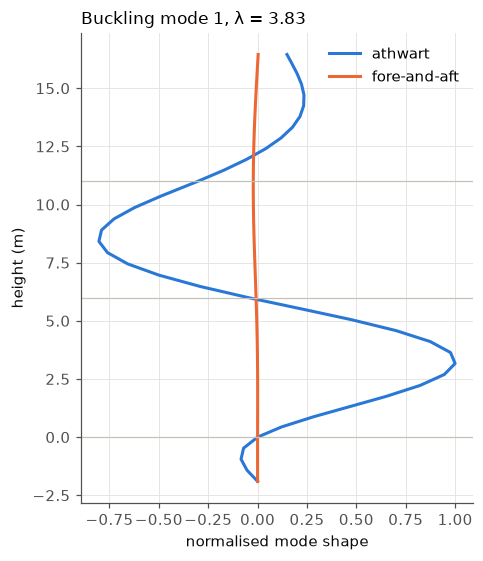

In [18]:
def plot_mode(m, geo, phi, lam, k=0):
    ids = {nm: m.nodes[nm].ID for nm in geo["mast_nodes"]}
    z = np.array([geo["nodes"][n][2] for n in geo["mast_nodes"]])
    u = np.array([to_boat(phi[ids[n] * 6:ids[n] * 6 + 3, k]) for n in geo["mast_nodes"]])
    u = u / np.max(np.abs(u))
    fig, ax = plt.subplots(figsize=(4.5, 5.2))
    ax.plot(u[:, 1], z, color=C_PYNITE, label="athwart")
    ax.plot(u[:, 0], z, color=C_OPS_PD, label="fore-and-aft")
    for zz in (GEO["z"]["s1"], GEO["z"]["s2"], 0.0):
        ax.axhline(zz, color="#c3c2b7", lw=0.8)
    ax.set_xlabel("normalised mode shape"); ax.set_ylabel("height (m)")
    ax.set_title(f"Buckling mode {k+1}, λ = {lam[k]:.2f}", loc="left", fontsize=11)
    ax.legend(frameon=False); plt.tight_layout(); plt.show()


plot_mode(M_PY, GEO, PHI, LAM, 0)

### What the buckling numbers say (Z900E section, placeholder geometry and loads)

- **First mode: λ ≈ 3.8, flexural.** The frame finds more margin than the pinned-panel Euler estimate
  (about 1.95 in the lowest panel) because the mast is continuous over the spreaders and partners, and
  the taut wires add stiffness. The Euler table is a floor, not a prediction.
- **Torsional-flexural buckling doesn't govern the Z900E.** In every panel its $P_{TF}$ comes out
  within about 2% of the plain Euler load, so bending, not twist, sets the limit. The lowest panel's
  ratio is about 1.9. The closed forward cell's large $J$ is why. It would hold even if the forward
  face were open, because the internal arch keeps the shear centre within about 30 mm of the centroid.
- **The plain slotted oval failed this check** ($P_{TF}/N \approx 0.5$). It had no internal wall, and
  its shear centre sat about 250 mm forward. That was the estimate's weakness, not the mast's, and it's
  why real section data was worth getting.
- **Slack wires and mechanisms.** When a leeward cap goes slack above the lower spreader, the upper
  spreader tip is held only by its released root, a mechanism with no stiffness. `buckling_factor`
  removes $K$'s null space before the eigen-solve; without that, the 0/0 eigenpair came back as noise
  (λ = 0.04 in the RM ×1.5 case).

---
## §9 Cross-check: OpenSeesPy

**How it runs.** The model goes to OpenSeesPy as JSON, runs in a separate Python process, and comes back the same way, as with CalculiX or Elmer. The notebook uses the first interpreter that can import `openseespy`: the one named in the environment variable `RIGFRAME_OPENSEES_PYTHON`, the notebook's own, or a sidecar venv at `~/python-venvs/opensees-py312`. OpenSeesPy 3.8's Windows build links `python312.dll`, so on Windows that has to be Python 3.12; on Linux and Colab, 3.12 or later. If none is found, these checks report **SKIP**.

**License.** OpenSeesPy is free "for research, education, and internal use"; commercial
redistribution needs a license (`openseespywin/LICENSE.md`). It isn't GPL, but it isn't OSI open
source either. Personal study is fine.

**The OpenSees model:**
- Same nodes. Mast and spreaders are `elasticBeamColumn` with the same section values; the spreader
  root release is `-releasez 1`.
- Wires are `corotTruss` on `InitStrainMaterial(Elastic(E, 0, Eneg=0))`, so each wire is
  tension-only. The bottom segment's initial strain is $\delta/L$, taken from Pynite's tune. A
  two-bar test showed that a positive initial strain means the wire is too short, giving tension.
- Two stages: pretension, then `loadConst` and the sail loads ramped in ten steps.
- Two runs: with the **`PDelta`** transformation, and with **`Corotational`**, which handles rigid-body
  rotations exactly.

**What the comparison found:**
- **Run linear, the two solvers agree to 0.1 N on every wire,** so the models are the same.
- **Corotational OpenSees and P-Delta Pynite agree to better than 1%** on every wire but the forestay,
  and to 0.1% on masthead sway. That's check 8.
- **The forestay differs by 1.6%,** and the reason is bow shortening. A bowed mast's chord is shorter
  than the mast by $\tfrac12\int (du/dz)^2\,dz$, which linear-strain P-Delta leaves out. Pynite's own
  dock bend curve gives 0.81 mm; OpenSees corotational puts the masthead 0.74 mm lower, and that slackens
  the forestay by about 0.4 kN. The forward lowers add pre-bend, which is why this appeared only with four
  lowers.
- **The discontinuous rig's D2 costs Pynite some P-Delta.** Linear runs of the two solvers agree on every
  tension, but from linear to P-Delta Pynite adds 0.9 mm of masthead sway where OpenSees corotational adds
  2.8 mm, so Pynite's sway is 1.8% low. Its geometric stiffness for D2 uses the force without D2's
  made-to-length part (§5). Check 8 allows 3% on sway for this rig.
- **The windward backstay differs** for the same reason as the forestay: the backstays balance the forestay, and
  the masthead drop is 4.3% of that lightly loaded leg's stretch, so Pynite reads it 2.4% high. Check 8 allows 2.5% on both, as the
  Morgan notebook does for its backstays.
- **OpenSees's own `PDelta` transformation runs 1–3% high on tensions.** It's shown for information
  only. The corotational run is the reference because its kinematics are exact.

In [19]:
OPS_SCRIPT = r'''
import json, sys
import openseespy.opensees as ops

def run(model, transf):
    ops.wipe(); ops.model("basic", "-ndm", 3, "-ndf", 6)
    tag = {}
    for k, (nm, xyz) in enumerate(model["nodes"].items(), start=1):
        tag[nm] = k; ops.node(k, *xyz)
    for nm, fix in model["fix"].items():
        ops.fix(tag[nm], *fix)
    ttags = {}
    for k, b in enumerate(model["beams"], start=1):
        vz = tuple(round(v, 12) for v in b["vecxz"])
        if vz not in ttags:
            ttags[vz] = len(ttags) + 1
            ops.geomTransf(transf, ttags[vz], *vz)
        extra = ["-releasez", 1] if b.get("release_z_i") else []
        ops.element("elasticBeamColumn", k, tag[b["i"]], tag[b["j"]], b["A"], b["E"], b["G"], b["J"],
                    b["Iy"], b["Iz"], ttags[vz], *extra)
    nb = len(model["beams"])
    for k, w in enumerate(model["wires"], start=1):
        ops.uniaxialMaterial("Elastic", 2 * k - 1, w["E"], 0.0, 0.0)
        ops.uniaxialMaterial("InitStrainMaterial", 2 * k, 2 * k - 1, w["eps0"])
        ops.element("Truss" if transf == "Linear" else "corotTruss", nb + k, tag[w["i"]], tag[w["j"]], w["A"], 2 * k)
    nw, base = len(model["wires"]), len(tag) + 1
    for k, sp in enumerate(model.get("springs", [])):      # weak grounding springs (same role as in Pynite)
        g, mt = base + k, 2 * nw + 1 + k
        ops.node(g, *ops.nodeCoord(tag[sp["node"]])); ops.fix(g, 1, 1, 1, 1, 1, 1)
        ops.uniaxialMaterial("Elastic", mt, sp["k"])
        ops.element("zeroLength", nb + nw + 1 + k, g, tag[sp["node"]], "-mat", mt, mt, mt, "-dir", 1, 2, 3)

    def solve(nsteps):
        ops.constraints("Transformation"); ops.numberer("RCM"); ops.system("UmfPack")
        ops.test("NormDispIncr", 1e-10, 200); ops.algorithm("Newton")
        ops.integrator("LoadControl", 1.0 / nsteps); ops.analysis("Static")
        for s in range(nsteps):
            if ops.analyze(1) != 0:
                ops.algorithm("KrylovNewton")
                if ops.analyze(1) != 0:
                    raise RuntimeError(f"no convergence at step {s}")
                ops.algorithm("Newton")

    def collect():
        ops.reactions()
        return {"disp": {nm: ops.nodeDisp(t)[:3] for nm, t in tag.items()},
                "T": {w["name"]: ops.eleResponse(nb + k, "axialForce")[0] for k, w in enumerate(model["wires"], start=1)},
                "rxn": {nm: ops.nodeReaction(tag[nm]) for nm in model["fix"]},
                "mast_N": {b["i"]: ops.eleResponse(k, "localForce")[0]          # i-end axial, + = compression
                           for k, b in enumerate(model["beams"], start=1) if b["kind"] == "mast"},
                "lf": [ops.eleResponse(k, "localForce") for k in range(1, len(model["beams"]) + 1)]}  # N,Vy,Vz,T,My,Mz at i then j

    ops.timeSeries("Constant", 1); ops.pattern("Plain", 1, 1)      # stage 1: pretension only
    solve(1)
    dock = collect()
    ops.loadConst("-time", 0.0)
    ops.timeSeries("Linear", 2); ops.pattern("Plain", 2, 2)
    for nm, v in model["loads"].items():
        ops.load(tag[nm], *v)
    solve(model.get("nsteps", 10))
    return {"Dock": dock, "RM": collect()}

model = json.load(open(sys.argv[1]))
out = {tr: run(model, tr) for tr in model["transfs"]}
json.dump(out, open(sys.argv[2], "w"))
'''

def find_opensees_python():
    """An interpreter that can import openseespy: $RIGFRAME_OPENSEES_PYTHON, this one, or a sidecar venv.
    None means the OpenSees cross-check is skipped."""
    import sys
    home = Path.home() / "python-venvs" / "opensees-py312"
    for c in (os.environ.get("RIGFRAME_OPENSEES_PYTHON"), sys.executable, home / "Scripts" / "python.exe", home / "bin" / "python"):
        if c and Path(c).exists() and subprocess.run([str(c), "-c", "import openseespy.opensees"],
                                                     capture_output=True).returncode == 0:
            return Path(c)
    return None


OPS_PY = find_opensees_python()
print("OpenSees cross-check:", "will run" if OPS_PY else "openseespy not found, so it will SKIP")


def pynite_local_z(m, name):
    T = m.members[name].T()
    return tuple(float(v) for v in T[2, :3])         # third row = local z in global coordinates


def opensees_model(p, geo, sec, deltas, loads, m_ref):
    model = {"nodes": {n: to_solver(xyz) for n, xyz in geo["nodes"].items()}, "fix": {}, "beams": [], "wires": [],
             "loads": {}, "transfs": ["PDelta", "Corotational"]}
    for nm, fix in geo["supports"].items():
        t, r = to_solver(fix[:3]), to_solver(fix[3:])
        model["fix"][nm] = [int(bool(abs(v))) for v in (*t, *r)]
    ss = p.spreader_section
    for b in geo["beams"]:
        if b["kind"] == "mast":
            A, Iy, Iz, J = sec["A"], sec["I_ath"], sec["I_fa"], sec["J"]
        else:
            A, Iy, Iz, J = ss["A"], ss["I_horiz"], ss["I_vert"], ss["J"]
        model["beams"].append({"i": b["i"], "j": b["j"], "kind": b["kind"], "A": A, "E": p.E_al, "G": p.G_al,
                               "J": J, "Iy": Iy, "Iz": Iz, "vecxz": pynite_local_z(m_ref, b["name"]),
                               "release_z_i": b["kind"] == "spreader" and p.release_spreader_root})
    for w in geo["wires"]:
        L = seg_len(geo, w)
        d = deltas.get(w["group"], 0.0) if (w["bottom"] or w.get("fit")) else 0.0
        wp = wire_props(wire_size(p, w))
        model["wires"].append({"name": w["name"], "i": w["i"], "j": w["j"], "A": wp["A"], "E": p.E_wire,
                               "eps0": d / L})
    for nm, v in loads.items():
        model["loads"][nm] = [*to_solver(v[:3]), *to_solver(v[3:])]
    model["springs"] = [{"node": nm, "k": 1.0} for nm in geo["forestay_nodes"][1:-1]]
    return model


def run_opensees(model):
    if OPS_PY is None:
        return None
    work = Path(tempfile.mkdtemp(prefix="rig_ops_"))           # a temporary folder, removed afterwards
    try:
        (work / "ops_rig.py").write_text(OPS_SCRIPT)
        (work / "model.json").write_text(json.dumps(model))
        r = subprocess.run([str(OPS_PY), "-I", str(work / "ops_rig.py"), str(work / "model.json"), str(work / "out.json")],
                           capture_output=True, text=True, timeout=600)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-3000:])
        raw = json.loads((work / "out.json").read_text())
    finally:
        shutil.rmtree(work, ignore_errors=True)
    out = {}
    for tr, cases in raw.items():
        out[tr] = {}
        for c, d in cases.items():
            out[tr][c] = {"T": d["T"], "disp": {n: to_boat(v) for n, v in d["disp"].items()},
                          "rxn": {n: np.array([*to_boat(v[:3]), *to_boat(v[3:])]) for n, v in d["rxn"].items()},
                          "mast_N": d["mast_N"], "lf": d.get("lf")}
    return out


t0 = time.perf_counter()
OPS = run_opensees(opensees_model(params, GEO, MAST, DELTAS, LOADS, M_PY))
print("OpenSees:", "openseespy not found -> SKIP" if OPS is None else f"ran in {time.perf_counter()-t0:.1f} s")

OpenSees cross-check: will run


OpenSees: ran in 2.1 s


,Pynite dock,OPS PDelta dock,Pynite RM,OPS PDelta RM,OPS corot RM
segment,,,,,
cap_V1_P,20.77,21.09,30.55,31.32,30.68
cap_V2_P,14.22,14.65,20.78,21.48,20.83
cap_V3_P,14.32,14.75,20.94,21.65,20.99
inter_D2_P,6.83,6.73,10.23,10.30,10.31
lower_D1_P,11.22,11.21,16.11,16.09,16.09
lowerF_D1F_P,8.53,8.47,11.75,11.63,11.78
backstay_P,3.03,3.00,4.53,4.58,4.43
cap_V1_S,20.77,21.09,10.97,11.26,10.65
cap_V2_S,14.22,14.65,7.65,8.29,7.68


Dock bow shortening, partners to masthead: 0.81 mm (from the Pynite curve). OpenSees corotational puts the masthead 0.74 mm lower, which shortens the forestay by 0.72 mm: 0.36 kN of its tension. Pynite's dock forestay is 14.22 kN, corotational 14.09 kN.
The same drop shortens each backstay leg by 0.65 mm, 4.3% of the windward leg's stretch in the RM case (Pynite 4.53 kN, corotational 4.43 kN).


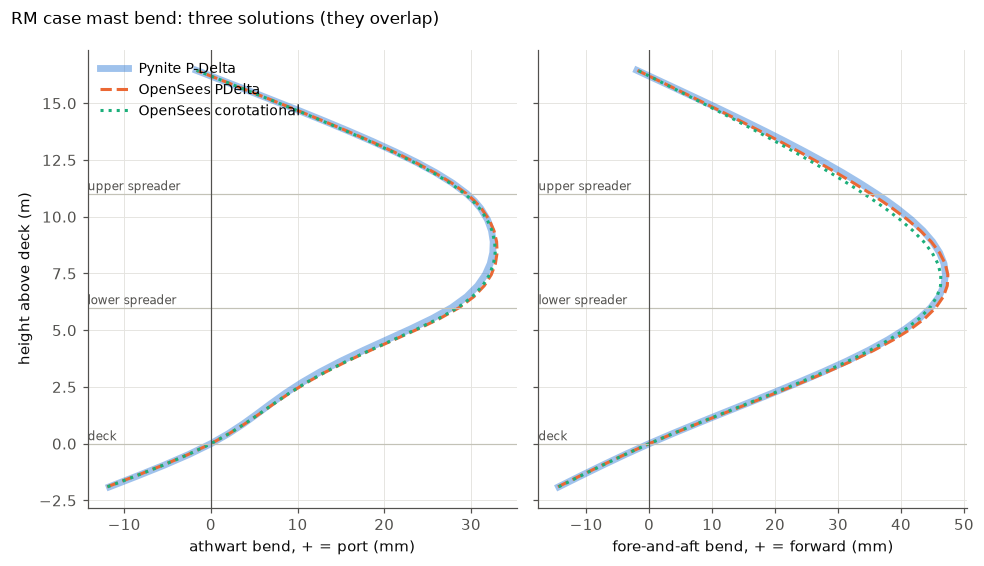

In [20]:
if OPS is not None:
    rows = []
    for w in GEO["wires"]:
        nm = w["name"]
        rows.append({"segment": nm,
                     "Pynite dock": RES["Dock"]["T"][nm] / 1e3, "OPS PDelta dock": OPS["PDelta"]["Dock"]["T"][nm] / 1e3,
                     "Pynite RM": RES["RM"]["T"][nm] / 1e3, "OPS PDelta RM": OPS["PDelta"]["RM"]["T"][nm] / 1e3,
                     "OPS corot RM": OPS["Corotational"]["RM"]["T"][nm] / 1e3})
    CMP = pd.DataFrame(rows).set_index("segment")
    display(CMP.style.format("{:.2f}").set_caption("wire tension (kN)"))

    # Why the forestay differs more than the other wires: bow shortening. A bowed mast's chord is shorter than
    # its length by about (1/2) * integral of (du/dz)^2 dz, a second-order term that linear strain leaves out.
    def bow_shortening(res):
        z_, ux = mast_curve(res, GEO, 0, chord=False)
        k = z_ >= 0.0
        return 0.5 * np.trapezoid(np.gradient(ux[k], z_[k])**2, z_[k])

    w_fs = next(w for w in GEO["wires"] if w["name"] == "forestay")
    e_fs = unit(GEO["nodes"][w_fs["i"]], GEO["nodes"][w_fs["j"]])
    EA_fs, L_fs = wire_props(params.wire["forestay"])["A"] * params.E_wire, seg_len(GEO, w_fs)
    dz_head = OPS["Corotational"]["Dock"]["disp"][head][2] - RES["Dock"]["disp"][head][2]
    print(f"Dock bow shortening, partners to masthead: {bow_shortening(RES['Dock'])*1e3:.2f} mm (from the Pynite curve). "
          f"OpenSees corotational puts the masthead {abs(dz_head)*1e3:.2f} mm lower, which shortens the forestay by "
          f"{abs(dz_head*e_fs[2])*1e3:.2f} mm: {abs(dz_head*e_fs[2])*EA_fs/L_fs/1e3:.2f} kN of its tension. Pynite's dock forestay "
          f"is {RES['Dock']['T']['forestay']/1e3:.2f} kN, corotational {OPS['Corotational']['Dock']['T']['forestay']/1e3:.2f} kN.")
    w_bs = next(w for w in GEO["wires"] if w["name"] == "backstay_P")
    e_bs = unit(GEO["nodes"][w_bs["i"]], GEO["nodes"][w_bs["j"]])
    EA_bs, L_bs = wire_props(params.wire["backstay"])["A"] * params.E_wire, seg_len(GEO, w_bs)
    print(f"The same drop shortens each backstay leg by {abs(dz_head*e_bs[2])*1e3:.2f} mm, "
          f"{abs(dz_head*e_bs[2])/(RES['RM']['T']['backstay_P']*L_bs/EA_bs):.1%} of the windward leg's stretch in the RM case "
          f"(Pynite {RES['RM']['T']['backstay_P']/1e3:.2f} kN, corotational {OPS['Corotational']['RM']['T']['backstay_P']/1e3:.2f} kN).")
    plot_bend({"Pynite P-Delta": (RES["RM"], C_PYNITE, "-"),
               "OpenSees PDelta": (OPS["PDelta"]["RM"], C_OPS_PD, "--"),
               "OpenSees corotational": (OPS["Corotational"]["RM"], C_OPS_CR, ":")},
              "RM case mast bend: three solutions (they overlap)")

---
## §10 Load cases side by side

One table with every case run on the same tuned rig:

| Case | What it represents |
|---|---|
| Dock tune | Preload only |
| Full sails, RM ×1.0 | The §4 case: the rig carries $RM_{30}$ |
| Full sails, RM ×1.5 | The same, with the gust or heel-beyond-30° factor that rig-sizing methods commonly apply |
| Headsail only, RM ×1.0 | The whole heeling moment through the genoa |
| Reefed main only, RM ×1.0 | The whole heeling moment through a deeply reefed main (`reef_fraction` of P), so the load sits low on the mast |
| Forestay sag, RM ×1.0 and ×1.5 | Full sails, but the headsail load acts **along the forestay** instead of being lumped at its ends |

**Why the forestay-sag case needs the corotational solver.** The genoa pushes the forestay sideways.
A taut wire that sags lengthens, so its tension rises, and that pulls the masthead forward against
the backstays and adds mast compression. The extra length is second order,
$\Delta S = \tfrac12 \int (dy/ds)^2\,ds$, so a linearised P-Delta solve (Pynite) sees the sag but
**not the tension rise**. OpenSees's `corotTruss` tracks exact geometry and does. The table shows both
solvers for this case so you can see the difference.

**Hand bound.** If the forestay's ends were rigid, the cable equation fixes its tension (Irvine,
*Cable Structures*, for small sag):

$$\frac{(T - T_0)\,L}{EA} = \frac{1}{2T^2}\int_0^L V(s)^2\,ds$$

Here $V(s)$ is the simple-beam shear of the luff load and $T_0$ the dock tension. In the rig the
masthead moves forward as the backstays stretch and the mast bends, which relieves some of the rise.
So the FE value should fall below this rigid-end bound. Check 9 tests the equation itself against
OpenSees on a single cable.

In [21]:
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import brentq


def cable_T_fixed_ends(T0, L, EA, w_of_s, n=4000):
    """Tension in a pretensioned cable with rigid ends under a transverse load w(s), small-sag theory."""
    s_ = np.linspace(0.0, L, n + 1)
    w_ = w_of_s(s_)
    R0 = np.trapezoid((L - s_) * w_, s_) / L
    V = R0 - cumulative_trapezoid(w_, s_, initial=0.0)
    I2 = np.trapezoid(V**2, s_)
    return brentq(lambda T: (T - T0) * L / EA - I2 / (2 * T**2), T0, T0 + 1e8)


def forestay_sag_mm(geo, res):
    """Largest sideways offset of the deformed forestay from its deformed chord."""
    fsn = geo["forestay_nodes"]
    if len(fsn) < 3:
        return np.nan
    P_ = [np.add(geo["nodes"][n], res["disp"][n]) for n in fsn]
    a, b = P_[0], P_[-1]
    u = (b - a) / np.linalg.norm(b - a)
    return 1e3 * max(np.linalg.norm((q - a) - np.dot(q - a, u) * u) for q in P_[1:-1])


def summarize(label, solver, geo, p, res, lam=np.nan, bound=np.nan):
    T = res["T"]
    mbl = {w["name"]: wire_props(wire_size(p, w))["MBL"] for w in geo["wires"]}
    sf = {n: mbl[n] / t for n, t in T.items() if t > 500.0}
    gov = min(sf, key=sf.get)
    fs = max(t for n, t in T.items() if GROUP_OF.get(n) == "forestay" or n.startswith("forestay"))
    hd = res["disp"][geo["key"]["head"]]
    return {"case": label, "solver": solver,
            "cap V1 wwd (kN)": T["cap_V1_P"] / 1e3, "inter D2 wwd (kN)": T["inter_D2_P"] / 1e3,
            "aft lower D1 wwd (kN)": T["lower_D1_P"] / 1e3, "fwd lower D1F wwd (kN)": T.get("lowerF_D1F_P", np.nan) / 1e3,
            "forestay (kN)": fs / 1e3,
            "forestay rigid-end bound (kN)": bound / 1e3, "backstay wwd (kN)": T["backstay_P"] / 1e3,
            "min SF": sf[gov], "governing wire": gov, "mast N max (kN)": max(res["mast_N"].values()) / 1e3,
            "masthead fwd (mm)": hd[0] * 1e3, "masthead athwart (mm)": hd[1] * 1e3,
            "forestay sag (mm)": forestay_sag_mm(geo, res), "λ": lam,
            "slack (< 0.5 kN)": ", ".join(n for n, t in T.items() if t < 500.0) or "none"}


def section_stress(N, M_fa, M_ath, kind, p=params):
    """Peak |stress| (Pa) in a mast or spreader section: |N|/A plus the two bending stresses combined at the
    worst point of an oval outline, sqrt((M_fa c_fa/I_fa)^2 + (M_ath c_ath/I_ath)^2). For a spreader, 'fa' is
    bending in the vertical plane (local z) and 'ath' bending in the horizontal plane."""
    if kind == "mast":
        A = MAST["A"]
        s1, s2 = M_fa * (p.mast_chord / 2e3) / MAST["I_fa"], M_ath * (p.mast_width / 2e3) / MAST["I_ath"]
    else:
        ss = p.spreader_section
        A = ss["A"]
        s1, s2 = M_fa * ss["c_vert"] / ss["I_vert"], M_ath * ss["c_horiz"] / ss["I_horiz"]
    return abs(N) / A + math.hypot(s1, s2)


def beam_stresses_pynite(m, geo, combo):
    """{beam: (sigma_max, N, M_fa, M_ath)} from Pynite, taking the worst of each element's ends and middle."""
    out = {}
    for b in geo["beams"]:
        mem = m.members[b["name"]]
        cands = []
        for x in (0.0, mem.L() / 2, mem.L()):
            N, Mz, My = mem.axial(x, combo), mem.moment("Mz", x, combo), mem.moment("My", x, combo)
            cands.append((section_stress(N, Mz, My, b["kind"]), N, Mz, My))
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


def beam_stresses_ops(res, geo):
    """The same from OpenSees localForce: (N, Vy, Vz, T, My, Mz) at end i, then end j."""
    out = {}
    for b, lf in zip(geo["beams"], res["lf"]):
        cands = [(section_stress(lf[0], lf[5], lf[4], b["kind"]), lf[0], lf[5], lf[4]),
                 (section_stress(lf[6], lf[11], lf[10], b["kind"]), -lf[6], lf[11], lf[10])]
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


t0 = time.perf_counter()
ROWS = [summarize("Dock tune", "Pynite P-Delta", GEO, params, RES["Dock"], LAM_DOCK[0])]
STRESS = {"Dock tune": {"geo": GEO, "p": params, "solver": "Pynite P-Delta", "T": RES["Dock"]["T"],
                        "s": beam_stresses_pynite(M_PY, GEO, "Dock"), "res": RES["Dock"], "info": None,
                        "lam": LAM_DOCK[0], "loads": {}}}
CASE_DEFS = [("Full sails, RM ×1.0", dict(sail_plan="full", RM_factor=1.0)),
             ("Full sails, RM ×1.5", dict(sail_plan="full", RM_factor=1.5)),
             ("Headsail only, RM ×1.0", dict(sail_plan="headsail_only", RM_factor=1.0)),
             (f"Reefed main only ({params.reef_fraction:.0%} of P), RM ×1.0", dict(sail_plan="reefed_main_only", RM_factor=1.0))]
for label, kw in CASE_DEFS:
    pc = replace(params, **kw)
    ld, inf_ = rm_loads(pc, GEO)
    mc_ = solve_pynite(pc, GEO, MAST, DELTAS, ld)
    r_ = pynite_results(mc_, GEO, "RM")
    lam_ = buckling_factor(mc_, "RM", 1)[0][0]
    ROWS.append(summarize(label, "Pynite P-Delta", GEO, pc, r_, lam_))
    STRESS[label] = {"geo": GEO, "p": pc, "solver": "Pynite P-Delta", "T": r_["T"], "s": beam_stresses_pynite(mc_, GEO, "RM"),
                     "res": r_, "info": inf_, "lam": lam_, "loads": ld}

# forestay-sag case: segmented forestay, retuned (same targets), headsail load along the forestay
GEO_FS = rig_geometry(params, segmented_forestay=True)
DELTAS_FS, _, _ = tune(params, GEO_FS, MAST)
fs_wp = wire_props(params.wire["forestay"])
SAG = {}
for k in (1.0, 1.5):
    pc = replace(params, sail_plan="full", RM_factor=k)
    ld, inf = rm_loads(pc, GEO_FS, forestay_sag=True)
    m_fs = solve_pynite(pc, GEO_FS, MAST, DELTAS_FS, ld)
    r_py = pynite_results(m_fs, GEO_FS, "RM")
    T0_fs = pynite_results(m_fs, GEO_FS, "Dock")["T"]["forestay"]
    Lf = seg_len(GEO, next(w for w in GEO["wires"] if w["name"] == "forestay"))
    bound = cable_T_fixed_ends(T0_fs, Lf, fs_wp["A"] * params.E_wire, lambda s, F=inf["F_head"], L=Lf: 2 * F / L * (1 - s / L))
    SAG[k] = {"loads": ld, "info": inf, "pynite": r_py, "bound": bound, "T0": T0_fs}
    if k == 1.0:
        ROWS.append(summarize("Forestay sag, RM ×1.0", "Pynite P-Delta", GEO_FS, pc, r_py,
                              buckling_factor(m_fs, "RM", 1)[0][0], bound))
    mod = opensees_model(pc, GEO_FS, MAST, DELTAS_FS, ld, m_fs)
    mod["transfs"] = ["Corotational"]
    o = run_opensees(mod)
    SAG[k]["ops"] = None if o is None else o["Corotational"]["RM"]
    if o is not None:
        ROWS.append(summarize(f"Forestay sag, RM ×{k:.1f}", "OpenSees corotational", GEO_FS, pc, SAG[k]["ops"], np.nan, bound))
        STRESS[f"Forestay sag, RM ×{k:.1f}"] = {"geo": GEO_FS, "p": pc, "solver": "OpenSees corotational",
                                                "T": SAG[k]["ops"]["T"], "s": beam_stresses_ops(SAG[k]["ops"], GEO_FS),
                                                "res": SAG[k]["ops"], "info": inf, "lam": np.nan, "bound": bound,
                                                "loads": ld}
    else:
        print(f"forestay sag ×{k}: OpenSees openseespy not found, corotational row skipped")

SUMMARY = pd.DataFrame(ROWS).set_index(["case", "solver"])
print(f"{len(ROWS)} cases in {time.perf_counter()-t0:.1f} s")
num = {c: "{:.1f}" for c in SUMMARY.columns if SUMMARY[c].dtype.kind == "f"}
num.update({"min SF": "{:.2f}", "λ": "{:.2f}"})
display(SUMMARY.style.format(num, na_rep="—")
        .set_caption("All cases on the same dock tune. wwd = windward (port). Pynite rows use two-cycle P-Delta; "
                     "the corotational rows include the forestay's second-order stretch."))

8 cases in 26.8 s


### Mast and spreader stresses

The table and plot below put the spars on the same footing as the wires. For each element the stress is

$$\sigma_{max} = \frac{|N|}{A} + \sqrt{\left(\frac{M_{fa}\,c_{fa}}{I_{fa}}\right)^2 + \left(\frac{M_{ath}\,c_{ath}}{I_{ath}}\right)^2}$$

- **$N$** is the axial compression. **$M_{fa}$ and $M_{ath}$** are the bending moments fore-and-aft and
  athwartships, each taken as the worst of the element's ends and middle.
- **Section values:** the Z900E's area and inertias come from the maker. The extreme-fibre distances are
  half the chord and half the width, $c_{fa} = 127.5$ mm and $c_{ath} = 80$ mm.
- **Why the square root:** it's the peak of the two bending stresses around an oval outline. It's
  slightly conservative, and slightly unconservative where the real metal sits beyond the oval at the
  lips.
- **Utilisation** is $\sigma_{max}/\sigma_y$ with an assumed $\sigma_y = 240$ MPa. That's the order of
  6061-T6 and 6082-T6; Z-Spars' alloy isn't stated (`sigma_y_al`).
- **Spreaders** use the same formula on a placeholder airfoil section, so their numbers are indicative
  only.
- **Solvers:** Pynite rows read moments from Pynite. The forestay-sag rows read OpenSees `localForce`.

This is a first check of overall stress. It doesn't cover local buckling of the wall, stress
concentrations at spreader roots, tangs and sheave boxes, or fatigue, which are what usually decide an
aluminium spar's details.

In [22]:
def stress_row(label, d):
    geo, p_ = d["geo"], d["p"]
    mast = {b["name"]: b for b in geo["beams"] if b["kind"] == "mast"}
    spr = [b for b in geo["beams"] if b["kind"] == "spreader"]
    mk = max(mast, key=lambda n: d["s"][n][0]); sk = max((b["name"] for b in spr), key=lambda n: d["s"][n][0])
    sig, N, Mfa, Math = d["s"][mk]
    z_a, z_b = geo["nodes"][mast[mk]["i"]][2], geo["nodes"][mast[mk]["j"]][2]
    wu = {w["name"]: d["T"][w["name"]] / wire_props(wire_size(p_, w))["MBL"] for w in geo["wires"]}
    wk = max(wu, key=wu.get)
    return {"case": label, "solver": d["solver"],
            "mast σ max (MPa)": sig / 1e6, "mast util": sig / p_.sigma_y_al, "at z (m)": f"{z_a:.1f} to {z_b:.1f}",
            "N there (kN)": N / 1e3, "M_fa (kN·m)": abs(Mfa) / 1e3, "M_ath (kN·m)": abs(Math) / 1e3,
            "spreader σ max (MPa)": d["s"][sk][0] / 1e6, "spreader util": d["s"][sk][0] / p_.sigma_y_al,
            "most utilised wire": wk, "wire util": wu[wk]}


STRESS_TBL = pd.DataFrame([stress_row(k, v) for k, v in STRESS.items()]).set_index(["case", "solver"])


def util_shade(x):                                   # same bands as §2's comparison: within 25%, 50%, beyond
    c = "#c9ecd9" if x <= 0.25 else "#fbe3a6" if x <= 0.5 else "#f7c6c5"
    return f"background-color: {c}; color: #0b0b0b"


display(STRESS_TBL.style.format({"mast σ max (MPa)": "{:.0f}", "mast util": "{:.0%}", "N there (kN)": "{:.0f}",
                                 "M_fa (kN·m)": "{:.2f}", "M_ath (kN·m)": "{:.2f}", "spreader σ max (MPa)": "{:.0f}",
                                 "spreader util": "{:.0%}", "wire util": "{:.0%}"})
        .map(util_shade, subset=["mast util", "spreader util", "wire util"])
        .set_caption(f"Peak stresses per case. Spar utilisation = σ / {params.sigma_y_al/1e6:.0f} MPa (assumed yield); "
                     "wire utilisation = tension / design MBL. Green ≤ 25%, amber ≤ 50%, red beyond."))

,,mast σ max (MPa),mast util,at z (m),N there (kN),M_fa (kN·m),M_ath (kN·m),spreader σ max (MPa),spreader util,most utilised wire,wire util
case,solver,,,,,,,,,,
Dock tune,Pynite P-Delta,48,20%,5.5 to 6.0,98,3.97,0.00,13,6%,cap_V1_S,20%
"Full sails, RM ×1.0",Pynite P-Delta,53,22%,5.5 to 6.0,98,4.00,1.76,16,7%,cap_V1_P,30%
"Full sails, RM ×1.5",Pynite P-Delta,57,24%,5.5 to 6.0,98,4.03,2.65,18,7%,cap_V1_P,35%
"Headsail only, RM ×1.0",Pynite P-Delta,49,20%,5.5 to 6.0,98,4.02,0.47,17,7%,cap_V3_P,37%
"Reefed main only (60% of P), RM ×1.0",Pynite P-Delta,86,36%,0.0 to 0.4,98,1.66,7.21,14,6%,lowerF_D1F_P,22%
"Forestay sag, RM ×1.0",OpenSees corotational,56,23%,5.5 to 6.0,114,3.72,1.79,9,4%,forestay,40%
"Forestay sag, RM ×1.5",OpenSees corotational,62,26%,5.5 to 6.0,122,3.45,2.65,11,5%,forestay,49%


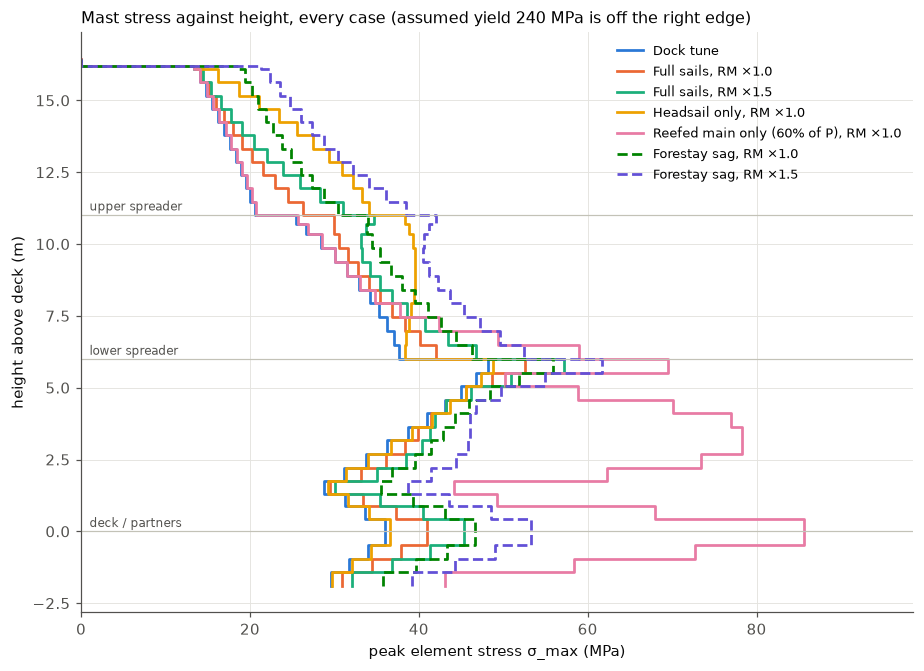

In [23]:
CASE_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots(figsize=(8.5, 6.2))
for (label, d), colr in zip(STRESS.items(), CASE_COLOURS):
    geo = d["geo"]
    zs, sg = [], []
    for b in geo["beams"]:
        if b["kind"] != "mast":
            continue
        za, zb = geo["nodes"][b["i"]][2], geo["nodes"][b["j"]][2]
        zs += [za, zb]; sg += [d["s"][b["name"]][0] / 1e6] * 2            # constant over each element
    ax.plot(sg, zs, color=colr, lw=1.8, ls="--" if d["solver"].startswith("OpenSees") else "-", label=label)
for zz, t in [(GEO["z"]["s1"], "lower spreader"), (GEO["z"]["s2"], "upper spreader"), (0.0, "deck / partners")]:
    ax.axhline(zz, color="#c3c2b7", lw=0.8)
    ax.text(1, zz + 0.15, t, fontsize=8, color="#52514e")
ax.set_xlabel("peak element stress σ_max (MPa)"); ax.set_ylabel("height above deck (m)")
ax.set_xlim(0, max(STRESS_TBL["mast σ max (MPa)"]) * 1.15)
ax.set_title(f"Mast stress against height, every case (assumed yield {params.sigma_y_al/1e6:.0f} MPa is off the right edge)",
             loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

### What the stresses show (Z900E section, placeholder geometry and loads)

- **Compression alone accounts for much of it.** The dock tune's 98 kN on 3600 mm² is 27 MPa before any
  bending, which is more than half the dock-tune peak of 48 MPa (20% of yield).
- **The lower spreader root is the hot spot in every case but one.** The swept spreaders push the mast
  forward there (1.0 kN), and the forward and aft lowers' pulls nearly cancel (1.9 kN forward against
  1.7 kN aft), so nothing answers the push. The mast bows 45 mm forward at the spreader root, and the
  fore-and-aft moment peaks there (about 4.0 kN·m). Without the forward pair the aft lowers nearly cancel
  the push, the bow is 2 mm, and the peak sits at the partners instead. Full sails reach 53 MPa (22%), and
  57 MPa (24%) at RM ×1.5.
- **The deeply reefed main is the governing case for the mast: 86 MPa, 36% of the assumed yield,** at
  the partners. All of the heeling moment comes in low, which puts about 7.2 kN·m of athwart bending into
  the mast there. Without the forward lowers it reaches 103 MPa: the second windward lower holds the
  spreader root better.
- **Headsail only** peaks at 49 MPa, also at the lower spreader root.
- **Forestay sag adds compression more than bending.** At RM ×1.5 the mast carries 122 kN and peaks at
  62 MPa (26%).
- **Spreaders stay below about 18 MPa,** on a placeholder section.
- **Check 12:** Pynite and OpenSees agree on the full-sail peak to 2.5%. Pynite's P-Delta is a little soft
  here because of how D2's made-to-length fit enters its geometric stiffness (§9).

### What the cases show (default placeholders)

- **Forestay sag is the case that changes the picture.** Carried along the forestay, the genoa load
  **doubles the forestay tension**, from about 14 kN to about 28 kN in OpenSees corotational. It nearly
  triples the windward backstay (3.0 to 8.4 kN) and adds about 16% to the mast compression (98 to
  114 kN). The masthead is pulled about 30 mm forward. At RM ×1.5 the forestay becomes the governing
  wire of the whole rig (SF about 2.05, at 35 kN). That's why rig-sizing methods treat the longitudinal
  case separately and size the forestay and backstays from it.
- **Pynite's P-Delta row for the same case is the warning.** It keeps the forestay at its dock tension
  and lets it sag almost a metre: it sees the sideways sag but not the stretch that sag forces. For a
  loaded cable, use the corotational result. The rigid-end cable bound (30 kN at ×1.0) sits just above
  it, as expected: the real masthead gives a little.
- **The caps govern the lumped-load cases.** The windward V1 carries the cap and the intermediate
  together: 35.4 kN at RM ×1.5 (SF 2.9). Headsail only puts the most into the top of the cap: V3 reaches
  26 kN, SF 2.7, the lowest of these cases.
- **The deeply reefed main loads the windward lowers hardest,** because the whole heeling moment comes
  in low on the mast: 21.7 kN in the 12 mm aft lower and 15.6 kN in the 10 mm forward one, SF 4.7 and
  4.6. Without the forward lowers the aft one takes 32.8 kN at SF 3.1 and governs.
- **RM ×1.5** raises everything by less than 1.5× and drops the minimum SF from 3.3 to 2.9. The
  preload is already in the wires, and only the increment scales.
- **No wire goes slack** in the lumped-load cases. The 12 mm aft lowers and V1 keep the leeward side
  loaded.

### Fore-and-aft stiffness at the spreader roots: the anti-pumping check

**Pumping** is the middle of the mast flexing fore-and-aft, in rhythm, in a seaway. It's a dynamic motion
driven by pitching, and none of the cases above model it. Its static measure is how stiffly the mast resists
a fore-and-aft push at the spreader roots, which is what fore and aft lowers are there to add. With only aft
lowers, the spreader root is held one way: push it aft and the aft lowers slacken.

**The probe.** On each rig's own dock tune, with each case's sail loads on, a 1 kN push is added at the
spreader root, first forward and then aft. The stiffness is the push divided by the root's extra
fore-and-aft movement. It's run for the four-lower rig and for the same rig with `forward_lowers = False`,
which keeps every other input, the aft lowers' 11% target included.

**Hand estimate.** A wire resists sideways movement of its top through the stretch that movement causes, plus
its string stiffness, so its fore-and-aft stiffness is about

$$k_x \approx \frac{EA}{L}\left(\frac{x_{cp}}{L}\right)^2 + \frac{T}{L}$$

where $x_{cp}$ is its chainplate's fore-and-aft distance from the mast. With the measured chainplates
(19 in aft, 27 in forward) on 6.25 m lowers, that's about 13 kN/m for each 12 mm aft lower and 18 kN/m for
each 10 mm forward one.

In [24]:
PUMP_CASES = [("Dock tune", None), ("Full sails, RM ×1.0", dict(sail_plan="full", RM_factor=1.0)),
              ("Reefed main only, RM ×1.0", dict(sail_plan="reefed_main_only", RM_factor=1.0))]


def fore_aft_stiffness(p, push=1000.0):
    """Fore-and-aft stiffness (N/m) at each spreader root, pushed forward and aft, on p's own dock tune."""
    g = rig_geometry(p)
    d, _, _ = tune(p, g, MAST)
    out = {}
    for case, kw in PUMP_CASES:
        pc = replace(p, **kw) if kw else p
        base = rm_loads(pc, g)[0] if kw else {}
        for root, node in (("lower", g["key"]["s1"]), ("upper", g["key"]["s2"])):
            def ux(F):
                ld = {n: np.asarray(v, float) for n, v in base.items()}
                ld[node] = ld.get(node, np.zeros(6)) + np.array([F, 0.0, 0.0, 0.0, 0.0, 0.0])
                return pynite_results(solve_pynite(pc, g, MAST, d, ld), g, "RM")["disp"][node][0]
            u0 = ux(0.0)
            out[(case, root, "forward")] = push / (ux(push) - u0)
            out[(case, root, "aft")] = push / (u0 - ux(-push))
    return out


t0 = time.perf_counter()
K_FA = {"two lowers": fore_aft_stiffness(replace(params, forward_lowers=False)),
        "four lowers": fore_aft_stiffness(replace(params, forward_lowers=True))}
PUMP = pd.DataFrame({k: {kk: vv / 1e3 for kk, vv in v.items()} for k, v in K_FA.items()})
PUMP.index = pd.MultiIndex.from_tuples(PUMP.index, names=["case", "spreader root", "push"])
PUMP["change"] = PUMP["four lowers"] / PUMP["two lowers"] - 1
print(f"probe ran in {time.perf_counter()-t0:.1f} s")
display(PUMP.style.format({"two lowers": "{:.1f}", "four lowers": "{:.1f}", "change": "{:+.0%}"})
        .set_caption("Fore-and-aft stiffness at the spreader roots (kN/m), 1 kN push each way, Pynite P-Delta"))

probe ran in 68.7 s


### What the stiffness probe shows (measured lower chainplates)

- **The forward lowers add about 50% fore-and-aft stiffness at the lower spreader root** (67 to 101 kN/m),
  and 26–58% at the upper one. The 34 kN/m they add matches the hand estimate: two wires at 18 kN/m.
- **The deeply reefed main is where they matter most.** The leeward aft lower is nearly slack there, so
  with two lowers the root is held by the windward one alone and is 30% softer than at the dock (47 kN/m).
  With four it stays at 92–101 kN/m, double the two-lower value.
- **The chainplates decide it.** $k_x$ goes as $x_{cp}^2$. At the earlier 0.35 m placeholder the forward
  lowers added only 16%; at the measured 27 in (0.69 m) they add about 50%.
- **Pumping itself is dynamic** and isn't modelled; this is its static measure.

---
## §11 Interactive explorer

The sliders rerun the whole Pynite pipeline (tune, then the RM case) and redraw the tension and bend
plots. Each move takes a few seconds, because the tune is a Newton solve. Widgets work in VS Code
and classic Jupyter; in a PDF export this cell shows only its last state.

In [25]:
try:
    import ipywidgets as W

    sizes = [s for s in WIRE.index if WIRE.loc[s, "system"] == "metric"] + \
            [s for s in WIRE.index if WIRE.loc[s, "system"] == "inch"]
    out = W.Output()

    def rerun(sweep, cap_pct, lower_pct, gz30, cap_wire, sail_plan):
        p = replace(params, sweep_deg=sweep, GZ30=gz30, sail_plan=sail_plan,
                    pretension_pct={**params.pretension_pct, "cap": cap_pct, "lower": lower_pct,   # forward lowers keep
                                    "lowerF": lower_pct + params.pretension_pct["lowerF"] - params.pretension_pct["lower"]},
                    wire={**params.wire, "cap": cap_wire})
        with out:
            out.clear_output(wait=True)
            g = rig_geometry(p)
            if (wire_bend_check(g)["deflection outboard (mm)"] <= 0).any():
                print("A spreader tip falls inside the wire line at this sweep. Lengthen the spreaders.")
                return
            d, _, _ = tune(p, g, MAST)
            ld, info = rm_loads(p, g)
            m = solve_pynite(p, g, MAST, d, ld)
            res = {c: pynite_results(m, g, c) for c in ("Dock", "RM")}
            tt = tension_table(res["Dock"], res["RM"], g, p)
            lam, _ = buckling_factor(m, "RM", 1)
            print(f"RM30 = {p.RM30/1e3:.1f} kN*m   min SF = {tt['SF (RM)'].min():.2f} ({tt['SF (RM)'].idxmin()})   "
                  f"slack: {', '.join(tt.index[tt['slack in RM case'] == 'SLACK']) or 'none'}   λ = {lam[0]:.2f}")
            plot_tensions(tt)

    ui = W.interactive(rerun, {"manual": True, "manual_name": "Run"},
                       sweep=W.FloatSlider(value=params.sweep_deg, min=0, max=30, step=1, description="sweep (°)"),
                       cap_pct=W.FloatSlider(value=params.pretension_pct["cap"], min=5, max=30, step=1, description="cap % MBL"),
                       lower_pct=W.FloatSlider(value=params.pretension_pct["lower"], min=5, max=30, step=1, description="aft lower %"),
                       gz30=W.FloatSlider(value=params.GZ30, min=0.3, max=1.2, step=0.05, description="GZ30 (m)"),
                       cap_wire=W.Dropdown(options=sizes, value=params.wire["cap"], description="cap wire"),
                       sail_plan=W.Dropdown(options=["full", "headsail_only", "main_only", "reefed_main_only"], value=params.sail_plan,
                                            description="sail plan"))
    display(W.VBox([ui, out]))
except ImportError:
    print("ipywidgets not available; edit RigParams in §0 instead")

---
## Placeholders to replace, roughly in order of how much they move the answer

1. **$GZ_{30}$** (that is, $RM_{30}$). Every sailing-case load scales with it. Look for the CE
   stability documents, a Beneteau stability curve, or an inclining test.
2. **Chainplate positions** (`chainplate`, `backstay_foot`). Shroud loads scale roughly with
   $1/y_{cp}$. The lowers' fore-and-aft positions are measured; their athwartships $\lvert y\rvert$ and
   both coordinates of the cap and intermediate chainplates are not.
3. **Mast section detail.** The Z900E's $A$ and $I$ are the maker's; its $J$, $C_w$ and shear centre come
   from a pixel trace of the profile drawing (check 11). A dimensioned drawing or DXF from Z-Spars would
   firm them up, and the luff-slot width is still a guess.
4. **Spreader heights, lengths and sweep.** Measure them, or take them from the sail plan.
5. **Wire sizes, and the MBL from the wire's own certificate** (the table's design MBL is the lowest
   of four catalogs).
6. **Keel- or deck-stepped, heel depth, boom height.**

---
## §12 Checks

Each check has a stated tolerance and the reason for it. The last cell raises if any check fails,
so a headless run fails loudly.

In [26]:
CHECKS = []


def check(name, value, ref, rel_tol, why, skip=False):
    if skip:
        CHECKS.append({"check": name, "value": np.nan, "reference": np.nan, "rel err": np.nan, "tol": rel_tol,
                       "result": "SKIP", "why tolerance": why}); return
    err = abs(value - ref) / max(abs(ref), 1e-30)
    CHECKS.append({"check": name, "value": value, "reference": ref, "rel err": err, "tol": rel_tol,
                   "result": "PASS" if err <= rel_tol else "FAIL", "why tolerance": why})


# 1. sectionproperties closed ellipse vs closed form pi/4 (a b^3 - ai bi^3), semi-axes
a, b, t = params.mast_chord / 2, params.mast_width / 2, params.mast_wall
cf_fa = math.pi / 4 * (b * a**3 - (b - t) * (a - t)**3) * 1e-12
cf_ath = math.pi / 4 * (a * b**3 - (a - t) * (b - t)**3) * 1e-12
check("1a sectionproperties closed tube I_fa", SEC["closed"]["I_fa"], cf_fa, 2e-3,
      "128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it")
check("1b sectionproperties closed tube I_ath", SEC["closed"]["I_ath"], cf_ath, 2e-3, "same polygon error")

# 2. cantilever tip deflection PL^3/3EI on the mast section, Pynite (and OpenSees below)
Lc, Pc = 10.0, 1000.0
mc = FEModel3D(); mc.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mc.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
mc.add_node("a", 0, 0, 0); mc.add_node("b", 0, Lc, 0)
mc.add_member("c", "a", "b", "Al", "mast"); mc.def_support("a", *[True] * 6)
mc.add_node_load("b", "FX", Pc, "L"); mc.add_load_combo("C", {"L": 1}); mc.analyze()
check("2a Pynite cantilever tip, fore-and-aft", mc.nodes["b"].DX["C"], Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9,
      "Euler-Bernoulli element is exact for a tip load")

# 3. pinned column buckling from K, Kg vs pi^2 EI/L^2
mb = FEModel3D(); mb.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mb.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
nel = 20
for k in range(nel + 1):
    mb.add_node(f"n{k}", 0, Lc * k / nel, 0)
for k in range(nel):
    mb.add_member(f"e{k}", f"n{k}", f"n{k+1}", "Al", "mast")
mb.def_support("n0", True, True, True, False, True, False)        # pinned; twist (RY) held
mb.def_support(f"n{nel}", True, False, True, False, False, False)
mb.add_node_load(f"n{nel}", "FY", -1000.0, "L"); mb.add_load_combo("C", {"L": 1}); mb.analyze()
lam_b, phi_b = buckling_factor(mb, "C", 6)
kb = next(k for k in range(len(lam_b)) if max(np.hypot(phi_b[i * 6, k], phi_b[i * 6 + 2, k]) for i in range(nel + 1))
          >= max(abs(phi_b[i * 6 + 4, k]) for i in range(nel + 1)) * r_tw)
check("3  Pynite K/Kg pinned column vs Euler (first flexural mode)", lam_b[kb] * 1000.0, math.pi**2 * params.E_al * MAST["I_ath"] / Lc**2, 2e-3,
      "20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin")

# 4. symmetric two-shroud lack of fit vs hand statics: mast fixed at the base (symmetry keeps it straight), two shrouds to the head
hL, yL, dl = 10.0, 1.5, 2e-3
wp = wire_props("8 mm"); L4 = math.hypot(hL, yL); c4 = hL / L4
ms = FEModel3D(); ms.add_material("Al", params.E_al, params.G_al, 0.33, 2700); ms.add_material("W", params.E_wire, 40e9, 0.3, 7950)
ms.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"]); ms.add_section("w", wp["A"], 1e-12, 1e-12, 1e-12)
ms.add_node("base", 0, 0, 0); ms.add_node("head", 0, hL, 0); ms.add_node("cp", 0, 0, yL); ms.add_node("cs", 0, 0, -yL)
ms.add_member("mast", "base", "head", "Al", "mast"); ms.def_support("base", *[True] * 6)
for nm, cp in (("wp", "cp"), ("ws", "cs")):
    ms.add_member(nm, cp, "head", "W", "w", tension_only=True)
    ms.def_releases(nm, Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True); ms.def_support(cp, *[True] * 6)
    u4 = unit((ms.nodes[cp].X, ms.nodes[cp].Y, ms.nodes[cp].Z), (0, hL, 0))
    for comp, val in zip(("DX", "DY", "DZ"), -dl * u4):
        if abs(val) > 0:
            ms.def_node_disp(cp, comp, float(val))
ms.add_load_combo("C", {}); ms.analyze(check_stability=False)
# compatibility: each wire stretch = dl - mast shortening * c ; mast force = 2 T c ; T = k_w (dl - c * 2 T c / k_m)
k_w, k_m = wp["A"] * params.E_wire / L4, MAST["A"] * params.E_al / hL
T_hand = k_w * dl / (1 + 2 * c4**2 * k_w / k_m)
check("4  lack-of-fit pretension vs hand", -ms.members["wp"].axial(1.0, "C"), T_hand, 1e-6,
      "linear statics with one compatibility equation; exact to solver precision")


# 5. global equilibrium of the rig, both cases (reactions + applied = 0)
def resultant(res, loads):
    F = sum(res["rxn"].values())
    for v in loads.values():
        F = F + np.asarray(v)
    return F


for label, res_, tol_, why_ in (("linear", RES_LIN, 1e-9, "linear statics: rounding only"),
                                ("P-Delta", RES, 2e-3, "Pynite's two-cycle P-Delta is not iterated to convergence; see §5")):
    for c, ld in (("Dock", {}), ("RM", LOADS)):
        R = resultant(res_[c], ld)
        scale = LINFO["F_main"] + LINFO["head_share_on_rig"] if c == "RM" else max(T_TARGET.values())
        resid = np.linalg.norm(R[:3]) / scale          # a ratio to zero, so judged as an absolute error
        CHECKS.append({"check": f"5  equilibrium {c}, {label}: |ΣF| / load scale", "value": resid, "reference": 0.0,
                       "rel err": resid, "tol": tol_, "result": "PASS" if resid <= tol_ else "FAIL",
                       "why tolerance": why_})

# 6. heeling moment carried by the supports = k*RM30  (moment of reactions about the boat x-axis at the deck)
Mx = {c: sum(r[3] + (GEO["nodes"][n][1] * r[2] - GEO["nodes"][n][2] * r[1]) for n, r in RES_LIN[c]["rxn"].items())
      for c in ("Dock", "RM")}
check("6  support moment about deck x-axis = k RM30 (linear solve)", -(Mx["RM"] - Mx["Dock"]), LINFO["M_target"], 1e-9,
      "statics of the load generator: the stem share acts at deck level, so the rig carries all of k RM30")

# 7. dock tune hits its targets
for g in TUNED:
    check(f"7  dock tune: {TARGET_OF[g]} via {g} turnbuckle", T_TUNED[g], T_TARGET[g], 1e-3, "Newton stops at |error| < 1 N")

# 8. Pynite P-Delta vs OpenSees corotational
skip = OPS is None
key_w = ["cap_V1_P", "cap_V3_P", "inter_D2_P", "lower_D1_P"] + (["lowerF_D1F_P"] if params.forward_lowers else []) + \
        ["backstay_P", "forestay"]
for nm in key_w:
    tol8, why8 = (0.025, "the mast's dock bow shortens its chord (§9), which linear-strain P-Delta omits; "
                         "that is ~1% of the forestay's stretch") if nm == "forestay" else \
                 (0.025, "the backstays balance the forestay, so they share its bow-shortening difference (§9); "
                         "the masthead drop is a few % of this lightly loaded leg's stretch") if nm == "backstay_P" else \
                 (0.01, "linear runs agree to 0.1 N; the rest is two-cycle P-Delta vs exact kinematics")
    check(f"8  RM tension {nm}: Pynite vs OpenSees corotational", RES["RM"]["T"][nm],
          np.nan if skip else OPS["Corotational"]["RM"]["T"][nm], tol8, why8, skip)
check("8  RM masthead athwart: Pynite vs OpenSees corotational", RES["RM"]["disp"][head][1],
      np.nan if skip else OPS["Corotational"]["RM"]["disp"][head][1], 0.03 if params.discontinuous else 0.02,
      "displacement is the most sensitive output; 2%, or 3% for the discontinuous rig, where Pynite's Kg takes D2's force "
      "without its made-to-length part and so understates the P-Delta sway (§9)", skip)
check("8  dock max mast compression: Pynite vs OpenSees corotational", Nmax["Dock"],
      np.nan if skip else max(OPS["Corotational"]["Dock"]["mast_N"].values()), 0.01,
      "pretension by enforced support motion (Pynite) vs initial strain (OpenSees)", skip)

# 2b. the same cantilever in OpenSees
cant = None
if OPS_PY.exists():
    mz = (0.0, 0.0, 1.0)
    cant = run_opensees({"nodes": {"a": (0, 0, 0), "b": (0, Lc, 0)}, "fix": {"a": [1] * 6}, "wires": [],
                         "beams": [{"i": "a", "j": "b", "kind": "mast", "A": MAST["A"], "E": params.E_al, "G": params.G_al,
                                    "J": MAST["J"], "Iy": MAST["I_ath"], "Iz": MAST["I_fa"], "vecxz": mz}],
                         "loads": {"b": [Pc, 0, 0, 0, 0, 0]}, "transfs": ["PDelta"], "nsteps": 1})
check("2b OpenSees cantilever tip, fore-and-aft", np.nan if cant is None else cant["PDelta"]["RM"]["disp"]["b"][0],
      Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9, "exact element; also confirms Iz = I_fa in OpenSees",
      cant is None)

# 9. cable equation (rigid ends) vs OpenSees corotational on a single pretensioned cable with the sag-case luff load
Lc9, T09, n9 = Lf, SAG[1.0]["T0"], 40
F9 = SAG[1.0]["info"]["F_head"]
cab = None
if OPS_PY.exists():
    nodes9 = {f"c{k:02d}": (Lc9 * k / n9, 0.0, 0.0) for k in range(n9 + 1)}
    fix9 = {nm: ([1] * 6 if k in (0, n9) else [0, 0, 0, 1, 1, 1]) for k, nm in enumerate(nodes9)}
    w9 = lambda s: 2 * F9 / Lc9 * (1 - s / Lc9)
    loads9 = {nm: [0.0] * 6 for nm in nodes9}
    for k in range(n9):
        sa, sb = Lc9 * k / n9, Lc9 * (k + 1) / n9
        loads9[f"c{k:02d}"][2] += (sb - sa) * (2 * w9(sa) + w9(sb)) / 6
        loads9[f"c{k+1:02d}"][2] += (sb - sa) * (w9(sa) + 2 * w9(sb)) / 6
    cab = run_opensees({"nodes": nodes9, "fix": fix9, "beams": [], "transfs": ["Corotational"], "nsteps": 20,
                        "wires": [{"name": f"s{k:02d}", "i": f"c{k:02d}", "j": f"c{k+1:02d}", "A": fs_wp["A"],
                                   "E": params.E_wire, "eps0": T09 / (fs_wp["A"] * params.E_wire)} for k in range(n9)],
                        "loads": {k_: v for k_, v in loads9.items() if any(v)}})
T9_hand = cable_T_fixed_ends(T09, Lc9, fs_wp["A"] * params.E_wire, lambda s: 2 * F9 / Lc9 * (1 - s / Lc9))
check("9  cable equation vs OpenSees corotational, rigid-end forestay", np.nan if cab is None else
      max(cab["Corotational"]["RM"]["T"].values()), T9_hand, 0.01,
      "small-sag theory (sag/L ~ 2%) and 40 segments; tension also varies slightly along the cable", cab is None)

# 10. the sag-case loads carry the same heeling moment about the deck as the lumped case
ld10, inf10 = SAG[1.0]["loads"], SAG[1.0]["info"]
M10 = sum(GEO_FS["nodes"][n][2] * -v[1] - GEO_FS["nodes"][n][1] * v[2] for n, v in ld10.items()) + sum(v[3] for v in ld10.values())
check("10 forestay-sag loads: moment about deck = k RM30", M10, inf10["M_target"], 1e-3,
      "consistent truss loads on 12 straight segments reproduce the triangular luff load's moment exactly; "
      "the 1e-3 covers the forestay head sitting at I, not exactly at the luff top")

# 11. the eye-traced Z900E against the maker's figures (how far to trust the traced J and shear centre)
for k, lab in (("A", "area"), ("I_fa", "I fore-and-aft"), ("I_ath", "I lateral")):
    check(f"11 traced Z900E {lab} vs maker", ZTR["closed"][k], MAST[k], 0.20,
          f"{ZTR['closed']['method']} of a drawing whose line weight runs light of the metal; 20% bounds it")

# 12. peak mast stress, full sails x1.0: Pynite P-Delta against OpenSees corotational (independent moments)
if OPS is not None and OPS["Corotational"]["RM"].get("lf"):
    s_ops = beam_stresses_ops(OPS["Corotational"]["RM"], GEO)
    s_py = STRESS["Full sails, RM ×1.0"]["s"]
    mk_ = [b["name"] for b in GEO["beams"] if b["kind"] == "mast"]
    check("12 peak mast stress, full sails: Pynite vs OpenSees corotational", max(s_py[n][0] for n in mk_),
          max(s_ops[n][0] for n in mk_), 0.03, "tensions agree within 1%; moments are more sensitive, so 3%")
    # the stress formula itself: a cantilever with tip loads both ways, at the root
    Pf, Pa, Lc_ = 1000.0, 500.0, 10.0
    check("12 section_stress formula vs hand, cantilever root", section_stress(0.0, Pf * Lc_, Pa * Lc_, "mast"),
          math.hypot(Pf * Lc_ * params.mast_chord / 2e3 / MAST["I_fa"], Pa * Lc_ * params.mast_width / 2e3 / MAST["I_ath"]),
          1e-12, "same algebra, written out by hand")
else:
    check("12 peak mast stress, full sails: Pynite vs OpenSees corotational", np.nan, np.nan, 0.03, "", True)

# 13. made-to-length wires (discontinuous D2) aren't tension-only in Pynite, so confirm none goes slack in any case
fit_w = [w["name"] for w in GEO["wires"] if w.get("fit")]
if fit_w:
    t_min = min(d["T"][n] for d in STRESS.values() for n in fit_w if n in d["T"])
    CHECKS.append({"check": "13 made-to-length wires stay taut in every case: min tension (N)", "value": t_min,
                   "reference": 0.0, "rel err": np.nan, "tol": np.nan, "result": "PASS" if t_min > 500.0 else "FAIL",
                   "why tolerance": "a wire can't push; above 0.5 kN, the slack threshold used everywhere else"})

CHK = pd.DataFrame(CHECKS).set_index("check")
display(CHK.style.format({"value": "{:.6g}", "reference": "{:.6g}", "rel err": "{:.2e}", "tol": "{:.0e}"}))

,value,reference,rel err,tol,result,why tolerance
check,,,,,,
1a sectionproperties closed tube I_fa,1.65124e-05,1.65257e-05,8.03e-04,2e-03,PASS,128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it
1b sectionproperties closed tube I_ath,8.07421e-06,8.0807e-06,8.03e-04,2e-03,PASS,same polygon error
"2a Pynite cantilever tip, fore-and-aft",0.195963,0.195963,0.00e+00,1e-09,PASS,Euler-Bernoulli element is exact for a tip load
3 Pynite K/Kg pinned column vs Euler (first flexural mode),69087.3,69087.2,8.44e-07,2e-03,PASS,20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin
4 lack-of-fit pretension vs hand,1026.19,1026.19,2.22e-16,1e-06,PASS,linear statics with one compatibility equation; exact to solver precision
"5 equilibrium Dock, linear: |ΣF| / load scale",5.17334e-12,0,5.17e-12,1e-09,PASS,linear statics: rounding only
"5 equilibrium RM, linear: |ΣF| / load scale",1.13872e-11,0,1.14e-11,1e-09,PASS,linear statics: rounding only
"5 equilibrium Dock, P-Delta: |ΣF| / load scale",1.41854e-05,0,1.42e-05,2e-03,PASS,Pynite's two-cycle P-Delta is not iterated to convergence; see §5
"5 equilibrium RM, P-Delta: |ΣF| / load scale",2.29838e-05,0,2.30e-05,2e-03,PASS,Pynite's two-cycle P-Delta is not iterated to convergence; see §5


### Information only: large-displacement effect and leeward slack

In [27]:
if OPS is not None:
    info = pd.DataFrame({nm: {"PDelta (kN)": OPS["PDelta"]["RM"]["T"][nm] / 1e3,
                              "corotational (kN)": OPS["Corotational"]["RM"]["T"][nm] / 1e3,
                              "corot − PDelta (%)": 100 * (OPS["Corotational"]["RM"]["T"][nm] / max(OPS["PDelta"]["RM"]["T"][nm], 1e-9) - 1)}
                         for nm in key_w}).T
    display(info.style.format("{:.2f}"))
    print(f"masthead athwart: PDelta {OPS['PDelta']['RM']['disp'][head][1]*1e3:+.1f} mm, "
          f"corotational {OPS['Corotational']['RM']['disp'][head][1]*1e3:+.1f} mm")
print("slack leeward wires in the RM case:", ", ".join(TT.index[TT["slack in RM case"] == "SLACK"]) or "none")

,PDelta (kN),corotational (kN),corot − PDelta (%)
cap_V1_P,31.32,30.68,-2.06
cap_V3_P,21.65,20.99,-3.07
inter_D2_P,10.30,10.31,0.11
lower_D1_P,16.09,16.09,0.04
lowerF_D1F_P,11.63,11.78,1.25
backstay_P,4.58,4.43,-3.32
forestay,14.69,14.00,-4.66


masthead athwart: PDelta -102.0 mm, corotational -101.7 mm
slack leeward wires in the RM case: none


In [28]:
n_fail = (CHK["result"] == "FAIL").sum(); n_pass = (CHK["result"] == "PASS").sum(); n_skip = (CHK["result"] == "SKIP").sum()
print(f"{n_pass} PASS, {n_fail} FAIL, {n_skip} SKIP")
assert n_fail == 0, CHK[CHK["result"] == "FAIL"]
print("ALL CHECKS OK")

33 PASS, 0 FAIL, 0 SKIP
ALL CHECKS OK


---
## §13 Report

This cell writes **`output/beneteau-oceanis-440-1994/REPORT.md`**, and one figure per load
case to `output/beneteau-oceanis-440-1994/assets/rig-oceanis440-case-*.svg`, which the report embeds. The report holds every
load case broken down item by item, all from the results above, so rerunning the notebook keeps it in
step with the inputs. It overwrites the file each run; set `WRITE_REPORT = False` to skip it.

The report opens with a **rigging list**, written by the cell below: every wire with its quantity, size, model length, breaking load and the highest load any case puts on it, plus totals by wire size and what to check before ordering.

After the summary table comes a **tuning section**, written by the second cell below: what the dock tune is for and how each goal is judged, what the wire safety factors mean and what they must cover, preload read as a bolted joint (Shigley §8-7), which wire governs each case and why the forestay carries so much, and what a bigger forestay would do. Its prose is general and every number in it comes from this run.

In [29]:
# ---- Rigging list for §13's report: every wire as it would be ordered ----------------------------------------
RIG_LABEL = {"forestay": ("Forestay (inside the genoa furler)", "stem to masthead"),
             "backstay": ("Backstay legs (split backstay)", "transom quarter to the masthead"),
             "cap": ("Caps (uppers)", "chainplate, over both spreader tips, to the masthead (V1 + V2 + V3, one wire)"),
             "inter": ("Intermediates", "lower spreader tip to the upper spreader root (D2)" if params.discontinuous else
                       "chainplate, over the lower spreader tip, to the upper spreader root (V1 + D2, one wire)"),
             "lowerF": ("Forward lowers", "chainplate to the lower spreader root"),
             "lower": ("Aft lowers", "chainplate to the lower spreader root")}                   # group -> (name, where it runs), in the order the list shows them
RIG_SEG_RUN = {("cap", "V1"): "chainplate to the lower spreader tip; carries the cap and the intermediate",   # by size
               ("cap", "V2 + V3"): "lower spreader tip, over the upper spreader tip, to the masthead (one wire)"}
RIG_PUBLISHED = {"lower", "lowerF", ("cap", "V1")}   # sizes known (measured by the owner) rather than placeholders
RIG_NOTE = ("The mast is the real Z-Spars Z900E. The four lowers' sizes and chainplate fore-and-aft positions, and the "
            "size of the caps' bottom segment (V1), are the owner's measurements. The spreader heights and lengths, the other "
            "chainplate coordinates and the other wire sizes are placeholders, so those lengths and sizes are estimates.")


def rigging_list_rows():
    """One row per wire type. Lengths come from the first geometry that has the group (the base rig first), so wires
    that only a variant has (split backstays) still appear. Loads are the largest over every case, on either side."""
    geos = list({id(g): g for g in [GEO] + [d["geo"] for d in STRESS.values()]}.values())
    pieces, size_of = {}, {}
    for geo in geos:
        for w in geo["wires"]:
            size_of[w["name"]] = wire_size(params, w)
            p_ = pieces.setdefault((w["group"], size_of[w["name"]]), {"geo": geo, "length": {}, "sides": set(), "segs": []})
            if p_["geo"] is geo:
                p_["sides"].add(w["side"])
                p_["length"][w["side"]] = p_["length"].get(w["side"], 0.0) + seg_len(geo, w)
                seg = w["name"].rsplit("_", 1)[0].split("_", 1)[-1]
                if seg not in p_["segs"] and w["side"] in ("P", "C"):
                    p_["segs"].append(seg)
    order = list(RIG_LABEL) + sorted({g for g, _ in pieces if g not in RIG_LABEL})
    rows = []
    for (g, size), p_ in sorted(pieces.items(), key=lambda kv: (order.index(kv[0][0]), -WIRE.loc[kv[0][1], "d_mm"])):
        split = sum(1 for gg, _ in pieces if gg == g) > 1
        segs = " + ".join(p_["segs"]) if split else None
        peak, peak_case, dock = 0.0, "", None
        for label, d in STRESS.items():
            for name, t in d["T"].items():
                if GROUP_OF.get(name) == g and size_of.get(name) == size and t > peak:
                    peak, peak_case = t, label
            if dock is None and label.endswith("Dock tune") and d["geo"] is p_["geo"]:
                dock = max(t for name, t in d["T"].items() if GROUP_OF.get(name) == g and size_of.get(name) == size)
        rows.append({"group": g, "segs": segs, "qty": 1 if "C" in p_["sides"] else len(p_["sides"]), "size": size,
                     "d_mm": float(WIRE.loc[size, "d_mm"]), "n_sources": int(WIRE.loc[size, "n_sources"]),
                     "length": max(p_["length"].values()), "mbl": wire_props(size)["MBL"],
                     "mbl_lbf": float(WIRE.loc[size, "MBL_design_lbf"]), "dock": dock, "peak": peak,
                     "case": peak_case.replace(" (60% of P)", ""), "base": p_["geo"] is GEO})
    return rows


def rigging_list_md():
    """The report's rigging list: a table per rig, totals by wire size, and what to check before ordering."""
    ft_in = lambda m: f"{round(m / 0.0254) // 12} ft {round(m / 0.0254) % 12} in"
    head = ["| Item and where it runs | Qty | Wire, 1x19 316 | Length, centre to centre (each) | Design MBL | Dock tune | "
            "Highest load in any case | Size |", "| --- | ---: | --- | --- | --- | --- | --- | --- |"]

    def line(r):
        name, run = RIG_LABEL.get(r["group"], (r["group"], ""))
        if r["segs"]:
            name, run = f"{name}, {r['segs']}", RIG_SEG_RUN.get((r["group"], r["segs"]), run)
        known = r["group"] in RIG_PUBLISHED or (r["group"], r["segs"]) in RIG_PUBLISHED
        dock = "—" if r["dock"] is None else f"{r['dock']/1e3:.1f} kN ({100 * r['dock'] / r['mbl']:.0f}%)"
        return (f"| **{name}**: {run} | {r['qty']} | {r['size']} ({r['d_mm']:.1f} mm) | {r['length']:.2f} m ({ft_in(r['length'])}) | "
                f"{r['mbl']/1e3:.1f} kN ({r['mbl_lbf']:,.0f} lbf) | {dock} | {r['peak']/1e3:.1f} kN, SF {r['mbl'] / r['peak']:.1f} "
                f"({r['case']}) | {'measured' if known else 'placeholder'} |")

    rows = rigging_list_rows()
    base, variant = [r for r in rows if r["base"]], [r for r in rows if not r["base"]]
    tot = {}
    for r in base:
        t = tot.setdefault(r["size"], {"pieces": 0, "len": 0.0, "d_mm": r["d_mm"], "n": r["n_sources"]})
        t["pieces"] += r["qty"]; t["len"] += r["qty"] * r["length"]
    out = ["## Rigging list", "",
           "Every piece of standing rigging in the model, laid out the way a rigging order is: what it is, how many, the wire "
           "and its length, with the breaking load and the highest load any case below puts on it. " + RIG_NOTE, ""]
    out += head + [line(r) for r in base]
    out += ["", "**Wire totals by size** (the pieces above, centre-to-centre lengths, before any allowance for terminals):", "",
            "| Wire | Pieces | Total length | MBL sources in the wire table |", "| --- | ---: | --- | ---: |"]
    out += [f"| {s} ({t['d_mm']:.1f} mm) 1x19 316 | {t['pieces']} | {t['len']:.1f} m ({t['len'] / 0.3048:.0f} ft) | {t['n']} |"
            for s, t in sorted(tot.items(), key=lambda kv: -kv[1]["d_mm"])]
    if variant:
        out += ["", "**Wires only the variant rig has** (split backstays: these are added, and the triatic dropped):", ""]
        out += head + [line(r) for r in variant]
    out += ["", "**Before ordering from this list:**", "",
            "- **The lengths are not cut lengths.** Each is measured in the model from the mast's centreline at the attachment "
            "height to the chainplate pin at deck level, along the wire. A real wire is made to its pin-to-pin length, tang to "
            "chainplate, with the turnbuckle and toggles at their working setting; tangs sit off the centreline and chainplate "
            "pins above the deck, so the real length differs by several centimetres even where the geometry is right.",
            "- **Measure the old wire,** pin to pin with its turnbuckle at the tuned setting, or have a rigger measure the spar "
            "and chainplates. Use this list for the sizes, the quantities and the loads to check fittings against.",
            "- **Terminals, toggles and turnbuckles aren't in the model.** Match them to the wire, and check that each fitting's "
            "rated load is at least the wire's MBL.",
            "- **MBL is the lowest of the catalogs in the wire table;** the totals table says how many catalogs each size rests "
            "on. Use the figure on the new wire's certificate.",
            "- **The highest load** is the largest tension any case in this report puts on that wire, at the placeholder GZ30. "
            "Port and starboard wires are the same length and see the same loads on opposite tacks.", ""]
    return out


In [30]:
# ---- Tuning section for §13's report: goals, preload as a bolted joint, which wire governs, a bigger forestay ------
X_TRI = 1 - 1 / np.sqrt(3)                                   # where the triangular luff load's moment peaks, s / L
C_TRI = 2 * X_TRI / 3 - X_TRI**2 + X_TRI**3 / 3             # M_max = C_TRI W L for w(s) = 2W/L (1 - s/L)
SF_GUY = 3.5                                                 # Shigley Table 17-25, minimum static SF for guys


def tuning_rows():
    """Every number the tuning section quotes, taken from STRESS, the dock tune and PUMP."""
    dock, T0 = STRESS["Dock tune"], STRESS["Dock tune"]["T"]
    mbl = lambda p_, w: wire_props(wire_size(p_, w))["MBL"]
    is_fs = lambda n: n.startswith("forestay")
    out = {"dock": dock}
    comp = {k: max(v["s"][b["name"]][1] for b in v["geo"]["beams"] if b["kind"] == "mast") for k, v in STRESS.items()}
    out["comp"], out["k_cmax"] = comp, max(comp, key=comp.get)
    lams = {k: v["lam"] for k, v in STRESS.items() if np.isfinite(v.get("lam", np.nan))}
    out["lams"], out["k_lmin"] = lams, min(lams, key=lams.get)
    # pre-bend: the lower spreader root's forward offset from the partners-to-masthead chord at the dock
    g, u = GEO, dock["res"]["disp"]
    zp, zh, z1 = (g["nodes"][g["key"][n]][2] for n in ("partners", "head", "s1"))
    up, uh, u1 = (u[g["key"][n]][0] for n in ("partners", "head", "s1"))
    out["prebend"] = u1 - (up + (uh - up) * (z1 - zp) / (zh - zp))
    try:
        out["k_pump"] = PUMP.loc[("Dock tune", "lower", "forward"), "four lowers"]
    except (KeyError, NameError):
        out["k_pump"] = np.nan

    # the lowest-SF wire in each case, and the forestay beside it
    gov = []
    for k, v in STRESS.items():
        sf = {w["name"]: mbl(v["p"], w) / v["T"][w["name"]] for w in v["geo"]["wires"] if v["T"][w["name"]] > 500.0}
        n = min(sf, key=sf.get)
        fw = [w for w in v["geo"]["wires"] if is_fs(w["name"])]
        tf = max(v["T"][w["name"]] for w in fw)
        gov.append({"case": k, "governing wire": "forestay" if is_fs(n) else wire_label(n), "its SF": sf[n],
                    "forestay (kN)": tf / 1e3, "forestay % MBL": 100 * tf / mbl(v["p"], fw[0]),
                    "forestay SF": mbl(v["p"], fw[0]) / tf, "forestay change from dock (kN)": (tf - T0["forestay"]) / 1e3,
                    "sag": "bound" in v})
    out["gov"] = gov
    # SF wire by wire: the dock, the worst case, and how much of the worst load is preload
    wsf = {}
    for k, v in STRESS.items():
        for w in v["geo"]["wires"]:
            n = w["name"]
            base = "forestay" if is_fs(n) else (n[:-2] if n[-2] == "_" else n)
            t, m_ = v["T"][n], mbl(v["p"], w)
            r = wsf.setdefault(base, {"wire": WIRE_LABEL.get(base, base), "size": wire_size(v["p"], w), "MBL (kN)": m_ / 1e3,
                                      "dock SF": np.inf, "lowest SF": np.inf, "in case": "", "peak (kN)": 0.0})
            if k == "Dock tune" and t > 500.0:
                r["dock SF"] = min(r["dock SF"], m_ / t)
            if t > 500.0 and m_ / t < r["lowest SF"]:
                r.update({"lowest SF": m_ / t, "in case": k, "peak (kN)": t / 1e3})
    for base, r in wsf.items():
        r["preload share of peak"] = 100 * (r["MBL (kN)"] / r["dock SF"]) / r["peak (kN)"] if r["peak (kN)"] else np.nan
        r["below 3.5"] = "yes" if r["lowest SF"] < SF_GUY else ""
    out["wsf"] = sorted(wsf.values(), key=lambda r: r["lowest SF"])
    bs =[(v["T"][w["name"]], mbl(v["p"], w), k) for k, v in STRESS.items() for w in v["geo"]["wires"]
          if w["name"].startswith("backstay")]
    t_, m_, k_ = max(bs, key=lambda r: r[0] / r[1])
    out["backstay_sf"], out["backstay_case"] = m_ / t_, k_

    # cable leverage in the sag cases: T delta = M_max of the same load on a simply supported span
    sag = []
    for k, v in STRESS.items():
        if "bound" not in v:
            continue
        geo_, W = v["geo"], v["info"]["F_head"]
        Lf = sum(seg_len(geo_, w) for w in geo_["wires"] if is_fs(w["name"]))
        T = max(t for n, t in v["T"].items() if is_fs(n))
        d_ = forestay_sag_mm(geo_, v["res"]) / 1e3
        sag.append({"case": k, "luff load W (kN)": W / 1e3, "forestay L (m)": Lf, "sag δ (mm)": d_ * 1e3,
                    "sag / L": 100 * d_ / Lf, "tension T (kN)": T / 1e3, "T / W": T / W,
                    "C·W·L/δ (kN)": C_TRI * W * Lf / d_ / 1e3, "rigid-end bound (kN)": v["bound"] / 1e3,
                    "T / bound": T / v["bound"]})
    out["sag"] = sag

    # opposed port/starboard pairs in the full-sail case, read as a preloaded joint (Shigley Eqs. 8-24, 8-25, 8-30)
    k1, k15 = "Full sails, RM ×1.0", "Full sails, RM ×1.5"
    c1 = STRESS[k1]
    pairs = []
    for w in GEO["wires"]:
        b = w["name"][:-2]
        if not w["name"].endswith("_P") or b == "backstay" or b + "_S" not in T0:
            continue
        s = b + "_S"
        dW, dL = c1["T"][w["name"]] - T0[w["name"]], c1["T"][s] - T0[s]
        n0 = T0[s] / -dL if dL < 0 else np.inf
        pairs.append({"pair": WIRE_LABEL.get(b, b), "dock (kN)": T0[s] / 1e3, "windward change (kN)": dW / 1e3,
                      "leeward change (kN)": dL / 1e3, "windward share C": dW / (dW - dL) if dW - dL > 0 else np.nan,
                      "n0": f"{n0:.2f}" if np.isfinite(n0) else "—", "_slack": c1["p"].RM_factor * n0,
                      "leeward slack at about": f"RM ×{c1['p'].RM_factor * n0:.2f}" if np.isfinite(n0) else "doesn't unload",
                      "leeward at RM ×1.5 (kN)": STRESS[k15]["T"][s] / 1e3 if k15 in STRESS else np.nan})
    out["pairs"], out["k1"], out["k15"] = pairs, k1, k15
    out["slack"] = {k: [wire_label(n) for n, t in v["T"].items() if t < 500.0 and not is_fs(n)] for k, v in STRESS.items()}

    # a bigger forestay in the worst sag case, rigid ends (an upper bound on its tension)
    ks = max((r for r in sag), key=lambda r: r["tension T (kN)"])["case"] if sag else None
    out["up"] = []
    if ks:
        v = STRESS[ks]
        W = v["info"]["F_head"]
        Lf = seg_len(GEO, next(w for w in GEO["wires"] if w["name"] == "forestay"))
        wfun = lambda s, F=W, L=Lf: 2 * F / L * (1 - s / L)
        size0 = params.wire["forestay"]
        mm = [s for s in WIRE.sort_values("d_mm").index if s.endswith("mm")]
        nxt = mm[mm.index(size0) + 1] if size0 in mm and mm.index(size0) + 1 < len(mm) else None
        T_dock = T0["forestay"]
        pct = params.pretension_pct["forestay"] / 100
        # extra dock compression per extra kN of forestay preload: the backstay legs balance it fore and aft
        nd = GEO["nodes"]
        fw = next(w for w in GEO["wires"] if w["name"] == "forestay")
        bw = [w for w in GEO["wires"] if w["name"].startswith("backstay")]
        unit = lambda w, top: (np.subtract(nd[w["j"]], nd[w["i"]]) if w["i"] == top else np.subtract(nd[w["i"]], nd[w["j"]]))
        head = GEO["key"]["head"]
        ef = unit(fw, head); ef /= np.linalg.norm(ef)
        eb = [unit(w, head) / np.linalg.norm(unit(w, head)) for w in bw]
        tb = -ef[0] / sum(e[0] for e in eb)                    # each backstay leg's tension per unit forestay tension
        dN = -ef[2] - tb * sum(e[2] for e in eb)               # mast compression per unit forestay tension
        rows = []
        for size, t0, note in [(size0, T_dock, "as modelled"), (nxt, T_dock, "same dock tension"),
                               (nxt, pct * wire_props(nxt)["MBL"] if nxt else np.nan, f"{100*pct:.0f}% of its MBL")]:
            if size is None:
                continue
            wp = wire_props(size)
            tb_ = cable_T_fixed_ends(t0, Lf, wp["A"] * params.E_wire, wfun)
            rows.append({"forestay": f"{size}, {note}", "MBL (kN)": wp["MBL"] / 1e3, "dock (kN)": t0 / 1e3,
                         "dock % MBL": 100 * t0 / wp["MBL"], "rigid-end bound (kN)": tb_ / 1e3,
                         "SF on the bound": wp["MBL"] / tb_, "extra dock compression (kN)": dN * (t0 - T_dock) / 1e3,
                         "EA/MBL": wp["A"] * params.E_wire / wp["MBL"]})
        out["up"], out["up_case"], out["dN"] = rows, ks, dN
    return out


def tuning_notes_md():
    """The report's tuning section. The prose is general; every number in it comes from this run."""
    R = tuning_rows()
    dock = R["dock"]
    pp = params.pretension_pct
    lo, hi = min(pp.values()), max(pp.values())
    fs_size = params.wire["forestay"]
    v1 = params.wire_segment.get("cap_V1", params.wire["cap"])
    gov, sag, pairs = R["gov"], R["sag"], R["pairs"]
    n_fs = [g["case"] for g in gov if g["governing wire"] == "forestay"]
    unside = lambda s: s.replace(", port (windward)", "").replace(", starboard (leeward)", "")
    others = list(dict.fromkeys(unside(g["governing wire"]) for g in gov if g["governing wire"] != "forestay"))
    cs = [r["windward share C"] for r in pairs if np.isfinite(r["windward share C"])]
    c_lo, c_hi = (min(cs), max(cs)) if cs else (np.nan, np.nan)
    lumped = [g for g in gov if not g["sag"] and g["case"] != "Dock tune"]
    max_lumped = max((abs(g["forestay change from dock (kN)"]) for g in lumped), default=np.nan)
    first = min(pairs, key=lambda r: r["_slack"]) if pairs else None
    first = first if first and np.isfinite(first["_slack"]) else None
    slack_any = sorted({f"{n} ({k})" for k, ns in R["slack"].items() for n in ns})
    sag_txt = "; ".join(f"{r['sag δ (mm)']:.0f} mm ({r['sag / L']:.1f}% of L) at {r['case'].split(', ')[-1]}, "
                        f"forestay {r['tension T (kN)']:.1f} kN" for r in sag) or "no sag case in this run"
    fs_sag = [g for g in gov if g["sag"]]
    fs_min = min(fs_sag, key=lambda g: g["forestay SF"]) if fs_sag else None
    cmax, cdock = R["comp"][R["k_cmax"]], R["comp"]["Dock tune"]
    targets = ", ".join(f"{k} {v:.0f}%" for k, v in pp.items())

    out = ["## Tuning: goals, criteria and preload", "",
           "Why the rig is tuned, how each goal is judged, and what this run says about three questions: which wire has the "
           "lowest safety factor, whether a bigger forestay would help, and how far preload works like a bolted joint. The "
           "prose is general; every number in this section comes from the cases above, so it changes when `RigParams` does. "
           "The companion note defines the terms (§5) and the forestay-sag case (§3.5).", "",
           "### What the tune is for", "",
           "| Goal | Why it matters | How it's judged | This run |", "| --- | --- | --- | --- |",
           f"| **Keep the mast in column** | The mast carries {cdock/1e3:.0f} kN at the dock. A crooked or loosely held column "
           "buckles well below its straight-column load. | Straight athwartships at the dock; first buckling load factor λ "
           f"well above 1 in every case. | λ = {R['lams']['Dock tune']:.2f} at the dock, lowest {R['lams'][R['k_lmin']]:.2f} "
           f"({R['k_lmin']}). |",
           "| **Keep the leeward rigging taut** | A slack wire adds no stiffness, lets the mast move, and is snatch-loaded when "
           "it comes back tight, which is hard on the wire and its fittings. | Leeward wires keep some tension up to the heel "
           "you sail at most. A little leeward slack in gusts is normal on a cruising tune. | "
           + (f"First to unload: {first['pair']}, at about RM ×{first['_slack']:.2f} (straight-line estimate, "
              "table below). " if first else "")
           + (f"Slack (under 0.5 kN) in: {', '.join(slack_any)}. |" if slack_any else "No wire goes slack in any case. |"),
           "| **Control headstay sag** | Sag sets the genoa's entry and depth: less sag points higher, more gives power. | "
           "As little sag as the genoa is cut for, with the forestay's SF still acceptable. | "
           f"{sag_txt}. |",
           "| **Set mast bend** | Pre-bend flattens the main and stops the mast inverting (bowing aft at the spreaders) "
           "under backstay or sheet load. | What the main is cut for. An in-mast furler wants little, so check "
           f"Z-Spars' tuning guide. | Lower spreader root {1e3*R['prebend']:.0f} mm forward of the partners-to-masthead chord "
           "at the dock. |",
           "| **Stiffen the mast fore and aft** | A soft mid-mast pumps in a seaway, cycling the wires and the mast wall. | "
           "Stiffness at each spreader root, from the anti-pumping check below. | "
           + (f"{R['k_pump']:.0f} kN/m at the lower root at the dock. |" if np.isfinite(R["k_pump"]) else "Not run. |"),
           "| **Pay as little compression as possible** | Every newton of preload sits in the mast, the step and the hull "
           "for as long as the rig is tuned. | The lowest preload that meets the goals above. | "
           f"{cdock/1e3:.0f} kN at the dock, {100*cdock/cmax:.0f}% of the highest ({cmax/1e3:.0f} kN, {R['k_cmax']}). |", "",
           f"The dock targets that set these are a rule of thumb in % of each wire's MBL: {targets}. The goals are "
           "what matters; the percentages are a way to reach them that scales with wire size.", "",

           "### Preload read as a bolted joint", "",
           "A tuned rig works like the tension joint in Shigley §8-7. The wires are the bolt, and the mast, step and hull are "
           "the clamped members. The turnbuckles stretch the wires and compress the mast before any sail load arrives, so each "
           "opposed pair starts tight. While both wires of a pair stay tight, a sail load is shared: the windward wire takes "
           "part of it as extra tension and the leeward wire gives up the rest. That is Shigley's Eqs. (8-24) and (8-25), "
           "F_b = CP + F_i and F_m = (1 − C)P − F_i, with the windward share in the part of the joint constant C. "
           "Eq. (8-30), n0 = F_i / [P(1 − C)], is the load factor against joint separation. In a rig, separation is the "
           "leeward wire going slack. Past it, the windward wire carries all of any further load and the pair's lateral "
           "stiffness roughly halves.", "",
           f"Opposed pairs in {R['k1']}, against the dock tune. n0 is the leeward wire's dock tension over its loss, so "
           "\"leeward slack at about\" is a straight-line extrapolation in RM; the last column is what the ×1.5 run actually "
           "gives, which shows how far the straight line holds. The backstay legs aren't an opposed pair athwartships "
           "(both gain), so they're left out.", ""]
    if pairs:
        out += [md_table(pairs, [c for c in pairs[0] if not c.startswith("_")],
                         {"dock (kN)": ".2f", "windward change (kN)": "+.2f", "leeward change (kN)": "+.2f",
                          "windward share C": ".2f", "leeward at RM ×1.5 (kN)": ".2f"}), ""]
    out += ["Where the comparison breaks:", "",
            "- **Compression is the cost here, not the point.** Clamping a joint's members is harmless and is what makes the "
            "joint stiff. Compressing a mast lowers its bending stiffness: the geometric stiffness Kg subtracts from K, which "
            f"is the P-Delta effect. It also uses up buckling margin (λ = {R['lams']['Dock tune']:.2f} at the dock) and holds "
            "the hull in a bow-and-string shape.",
            "- **So the preload is low.** Shigley's Eq. (8-31) preloads a bolt to 0.75 of its proof load if it will be reused "
            f"and 0.90 if permanent. This tune puts the wires at {lo:.0f}–{hi:.0f}% of MBL. Each wire still has to take the "
            "sail load on top, and every newton of preload is also in the mast.",
            f"- **The pairs don't all open together.** Here every pair splits its load almost evenly (C {c_lo:.2f}–{c_hi:.2f}), "
            "because port and starboard are mirror images and both wires stay in their straight range. What differs is "
            "each wire's preload against its loss, so the pairs reach separation at different RM (the n0 column). The first "
            "to open sets the rig's working limit, much as a bolted joint with several bolts is limited by its "
            "least-preloaded bolt.", "",

            "### What the safety factor means here", "",
            "**Definition.** SF = MBL / T: the wire's minimum breaking load over its tension in that case. It is a static "
            "factor against breaking, Shigley's n = F_u / F_t for wire rope (§17-6). % of MBL is the same number upside "
            "down (100 / SF). The MBL is the design MBL, the lowest of the catalogs in the wire table, because they differ "
            "by up to 18%. A new wire's certificate may well read higher.", "",
            "**What the margin has to cover.** The SF here is against breaking a perfect wire under a static load, so the "
            "margin above 1 has to absorb everything the model leaves out:", "",
            "- **Loads above the cases:** gusts and heel beyond RM ×1.5, pitching and slamming, a broach, a spinnaker, and "
            "sheet, halyard and vang loads (companion §3.7).",
            "- **Fatigue.** Every tack, wave and gust cycles the wire. 1x19 316 most often fails at a terminal (in the "
            "swage, or where the wire leaves it) and well below its static MBL, so the cyclic range matters as much as the peak.",
            "- **Terminals, pins and fittings,** which may be weaker than the wire. Each should be rated at least the wire's MBL.",
            "- **Corrosion,** mostly crevice corrosion inside swages and under tangs, which you can't see.",
            "- **Bending.** A wire bent over a spreader tip or pin loses strength (Shigley Fig. 17-20). The model treats every "
            "wire as straight.",
            "- **Model uncertainty:** the placeholder geometry and sizes, the assumed GZ30, and MBL scatter.", "",
            "**What SF to aim for.** Shigley's Table 17-25 (printed p. 910) gives a minimum static SF of "
            f"{SF_GUY} for guys, the closest of its categories to standing rigging; its general figure of 5 is written "
            "for hoisting and haulage rope. Rig-sizing methods (NBS, ISO 12215-10) set their own load cases and factors, "
            "which this notebook doesn't apply. One point is particular to a rig: **the transverse loads are capped by "
            "righting moment.** Past a point the boat heels instead of loading the rig harder, so RM ×1.0 at 30° is a "
            "realistic sailing load and ×1.5 stands in for maximum RM and dynamics. The forestay isn't capped the same way: "
            "the backstay adjuster can raise its tension at the dock, with no wind at all.", "",
            "**Preload uses up margin before any wind arrives.** The dock SF below is what the tune alone leaves. The last "
            "columns show how much of each wire's worst load is preload, and flag any wire below Shigley's figure for guys. "
            "For a cap or lower, a large preload share means the tune itself is a big part of the design load; for a leeward "
            "wire, the preload is what keeps it from going slack.", "",
            md_table(R["wsf"], ["wire", "size", "MBL (kN)", "dock SF", "lowest SF", "in case", "peak (kN)",
                                "preload share of peak", "below 3.5"],
                     {"MBL (kN)": ".1f", "dock SF": lambda v: "slack" if not np.isfinite(v) else f"{v:.2f}",
                      "lowest SF": ".2f", "peak (kN)": ".1f", "preload share of peak": lambda v: f"{v:.0f}%"}), "",
            "### Which wire has the lowest safety factor?", "",
            md_table(gov, ["case", "governing wire", "its SF", "forestay (kN)", "forestay % MBL", "forestay SF",
                           "forestay change from dock (kN)"],
                     {"its SF": ".2f", "forestay (kN)": ".1f", "forestay % MBL": ".0f", "forestay SF": ".2f",
                      "forestay change from dock (kN)": "+.1f"}), "",
            f"**The forestay governs in {len(n_fs)} of {len(gov)} cases**"
            + (f" ({', '.join(n_fs)})" if n_fs else "")
            + (f"; elsewhere the lowest SF is on the {'; the '.join(others)}." if others else ".")
            + f" In the cases without forestay sag the forestay keeps its dock tension (within {max_lumped:.2f} kN). Those "
            "cases put the headsail's pull on the rig as point loads, a third at the masthead and the rest at the stem, so the "
            "forestay never feels sail pressure along its length. Only the forestay-sag cases load it the way a set genoa does, "
            "so read the forestay's SF from those rows.", "",
            "**So it isn't always the forestay.** On a masthead sloop with a genoa pulling, the forestay usually carries the "
            "highest single wire tension, for the reason below. Whether it also has the lowest SF depends on how big it is "
            "made. Designers know it is the highest-tension wire and size it up for things a static model leaves out: it is a "
            "single load path (if it goes, the mast falls aft); it sits inside the furler foil where it can't be inspected; "
            "luff flutter and pitching fatigue it; and pitching into a sea snatch-loads it. A common rule is at least the size "
            f"of the largest cap. Here the forestay is a placeholder {fs_size}, against the measured {v1} cap V1.", "",
            "**Why a forestay carries so much:** a nearly straight cable is a poor way to carry a sideways load. Taking "
            "moments about the tack, T·δ = M_max, the peak bending moment the same load would put in a simply supported beam "
            "of the forestay's length. For the triangular luff load the model uses, w(s) = 2W/L·(1 − s/L), "
            f"M_max = {C_TRI:.4f}·W·L at s = {X_TRI:.2f} L, so T = {C_TRI:.4f}·W·L/δ. The tension is set by how far the "
            "forestay is allowed to sag: halve the sag and the tension doubles.", ""]
    if sag:
        out += [md_table(sag, list(sag[0]), {"luff load W (kN)": ".2f", "forestay L (m)": ".2f", "sag δ (mm)": ".0f",
                                             "sag / L": lambda v: f"{v:.1f}%", "tension T (kN)": ".1f", "T / W": ".1f",
                                             "C·W·L/δ (kN)": ".1f", "rigid-end bound (kN)": ".1f", "T / bound": ".2f"}), "",
                "W is the whole headsail force, spread along the forestay. δ is the model's largest offset of the deformed "
                "forestay from its deformed chord, and C·W·L/δ should match T. The rigid-end bound is the cable equation "
                "with the masthead and stem held still; the model runs below it because they move.", ""]
    out += ["**What sets the sag:** a sagging forestay is longer than its masthead-to-stem chord by about (8/3)δ²/L. That "
            "extra length comes from the forestay's own stretch and from everything that lets the masthead move toward the "
            "stem: backstay stretch, mast shortening and bend, and the hull bending (hogging). All of these act in series, "
            "and backstay tension is the only one you can adjust while sailing.", "",

            "### Would a bigger forestay help?", "",
            "The worry: a bigger forestay is stronger, but would it take away tuning control, or need a bigger backstay "
            "and more preload, and so more compression? On a masthead rig, mostly not.", "",
            "- **The forestay barely sets mast bend.** The forestay and backstay both land at the masthead, so their "
            "fore-and-aft pulls mostly cancel. They set rake and forestay tension and add compression, but they bend the mast "
            f"very little. The pre-bend comes from the swept spreaders and the lowers ({1e3*R['prebend']:.0f} mm here).",
            "- **It doesn't force more preload.** The % MBL targets tie preload to wire size, but the sail needs an absolute "
            "tension. The same dock tension on a bigger wire is just a smaller % of its MBL, and the backstay, mast and hull "
            "see nothing new."
            + (f" The backstay legs' lowest SF in any case is {R['backstay_sf']:.1f} ({R['backstay_case']})." if "backstay_sf" in R else ""),
            "- **Under load, a stiffer wire stretches less,** so the sag drops a little and the peak tension rises a little, "
            "but by less than the MBL rises, so the SF improves. With rigid ends and a uniform load, compatibility gives "
            "w²L²·(EA/MBL)/MBL² = 24·t²·(t − t0), where t = T/MBL. EA/MBL is nearly the same for every 1x19 size (last "
            "column below), so a bigger MBL lowers t.", ""]
    if R["up"]:
        out += [f"Rigid-end cable bound in {R['up_case']}, the worst sag case (an upper bound on the forestay's tension):", "",
                md_table(R["up"], list(R["up"][0]), {"MBL (kN)": ".1f", "dock (kN)": ".1f", "dock % MBL": ".0f",
                                                    "rigid-end bound (kN)": ".1f", "SF on the bound": ".2f",
                                                    "extra dock compression (kN)": "+.1f", "EA/MBL": ".0f"}), "",
                f"Extra dock compression is the extra forestay preload times {R['dN']:.2f}: the backstay legs balance it fore "
                "and aft, and both pull the masthead down. The rig's own response (mast bend, hull) isn't in that figure.", ""]
    out += ["**The loop that does matter runs through sag.** Wanting less sag in a breeze means more backstay, which means "
            "more forestay tension, more compression and, over a design, a heavier mast section. Racers handle it with a "
            "hydraulic backstay that is only wound on when needed. Cruisers tune moderately, accept some sag, and have the "
            "genoa cut for it.", "",
            "**Masthead and fractional rigs differ here.** On a fractional rig the backstay pulls above the forestay's "
            "attachment, so the same pull bends the top of the mast aft, flattens the main and tightens the forestay at once. "
            "There, forestay tension, mast bend and backstay load are coupled in the way the worry above describes. On this "
            "masthead rig they are mostly separate: the backstay sets forestay tension, and the spreaders and lowers set bend.",
            "",
            "Sources: Shigley, *Mechanical Engineering Design* 10th ed., §8-7, Eqs. (8-24) and (8-25), p. 428; Eq. (8-30), "
            "p. 433; Eq. (8-31), p. 434 (printed pages). The cable relations are small-sag theory, as in the notebook's "
            "`cable_T_fixed_ends`.", ""]
    return out


In [31]:
WRITE_REPORT = True
REPORT_PATH = OUT / "REPORT.md"


def md_table(rows, cols, fmt=None, align=None):
    """rows: list of dicts. fmt: {col: format string or callable}. Right-aligns numbers."""
    fmt = fmt or {}
    def cell(r, c):
        v = r.get(c, "")
        f = fmt.get(c)
        if v is None or (isinstance(v, float) and not np.isfinite(v)):
            return "—"
        if callable(f):
            return f(v)
        return format(v, f) if f else str(v)
    al = [(align or {}).get(c, "r" if isinstance(rows[0].get(c), (int, float, np.floating)) else "l") for c in cols]
    head = "| " + " | ".join(cols) + " |"
    rule = "| " + " | ".join("---:" if a == "r" else "---" for a in al) + " |"
    body = ["| " + " | ".join(cell(r, c) for c in cols) + " |" for r in rows]
    return "\n".join([head, rule] + body)


PANELS = [("heel to deck", -99.0, 0.0), ("deck to lower spreader", 0.0, GEO["z"]["s1"]),
          ("lower to upper spreader", GEO["z"]["s1"], GEO["z"]["s2"]),
          ("upper spreader to masthead", GEO["z"]["s2"], GEO["z"]["head"] + 1e-6)]
WIRE_LABEL = {"cap_V1": "cap V1 (chainplate to lower tip)", "cap_V2": "cap V2 (lower tip to upper tip)",
              "cap_V3": "cap V3 (upper tip to masthead)", "inter_V1": "intermediate V1 (chainplate to lower tip)",
              "inter_D2": "intermediate D2 (lower tip to upper root)", "lower_D1": "aft lower D1 (chainplate to lower root)",
              "lowerF_D1F": "forward lower D1F (chainplate to lower root)",
              "backstay": "backstay leg", "forestay": "forestay"}


def wire_label(name):
    if name.startswith("forestay_s"):
        return f"forestay segment {int(name[-2:])}"
    base, side = (name[:-2], name[-1]) if name[-2] == "_" else (name, "")
    lab = WIRE_LABEL.get(base, base)
    return f"{lab}, {'port (windward)' if side == 'P' else 'starboard (leeward)' if side == 'S' else ''}".rstrip(", ")


FIG_DIR = OUT / "assets"
FIG_DIR.mkdir(parents=True, exist_ok=True)
UTIL_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "util", ["#f3c7a9", "#efa47a", "#eb7f4c", "#e0602a", "#c24a1a", "#962f0c", "#651c05"])
UTIL_MAX = 0.5                       # colour scale 0..50 % utilisation, shared by every case and every member
C_LOADS = "#2a78d6"                  # applied loads (kept off the warm utilisation ramp)
DISP_SCALE = 5.0                     # deflections drawn x5 in every case figure


def case_figure(label, d, path):
    """Four panels for one load case: views from astern and in profile (deflected, coloured by utilisation,
    loads as arrows), mast stress against height, and every wire's % MBL."""
    geo, p_, res, loads = d["geo"], d["p"], d["res"], d["loads"]
    n_, disp = geo["nodes"], res["disp"]
    P = lambda nm, sc: np.add(n_[nm], sc * np.asarray(disp[nm]))
    util_w = {w["name"]: d["T"][w["name"]] / wire_props(wire_size(p_, w))["MBL"] for w in geo["wires"]}
    util_b = {b["name"]: d["s"][b["name"]][0] / p_.sigma_y_al for b in geo["beams"]}
    colour = lambda u: UTIL_CMAP(min(u / UTIL_MAX, 1.0))
    fig = plt.figure(figsize=(16, 7.4))
    gs = fig.add_gridspec(1, 4, width_ratios=[1.05, 1.9, 1.0, 1.25], wspace=0.28)
    views = [(fig.add_subplot(gs[0]), lambda q: (-q[1], q[2]), "From astern (starboard to the right)"),
             (fig.add_subplot(gs[1]), lambda q: (q[0], q[2]), "Profile (bow to the right)")]
    for ax, proj, title in views:
        for b in geo["beams"]:                                  # undeformed ghost
            a0, b0 = proj(n_[b["i"]]), proj(n_[b["j"]])
            ax.plot([a0[0], b0[0]], [a0[1], b0[1]], color="#d8d7d2", lw=3 if b["kind"] == "mast" else 2, zorder=1)
        for w in geo["wires"]:
            a1, b1 = proj(P(w["i"], DISP_SCALE)), proj(P(w["j"], DISP_SCALE))
            t = d["T"][w["name"]]
            if t < 500:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color="#8a8984", lw=1.0, ls=(0, (2, 2)), zorder=2)
            else:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_w[w["name"]]), lw=1.8, zorder=2)
        for b in geo["beams"]:
            a1, b1 = proj(P(b["i"], DISP_SCALE)), proj(P(b["j"], DISP_SCALE))
            ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_b[b["name"]]),
                    lw=5 if b["kind"] == "mast" else 3, solid_capstyle="butt", zorder=3)
        # applied loads: arrows scaled to a common length per kN within the figure
        Fs = {nm: np.asarray(v[:3]) for nm, v in loads.items() if nm in n_ and np.linalg.norm(v[:3]) > 1.0}
        fmax = max((np.linalg.norm(f) for f in Fs.values()), default=1.0)
        for nm, f in Fs.items():
            tip = np.asarray(proj(P(nm, DISP_SCALE)))
            dvec = np.asarray(proj(f)) - np.asarray(proj((0.0, 0.0, 0.0)))
            if np.linalg.norm(dvec) < 1e-9 * fmax:
                continue
            tail = tip - dvec / fmax * 1.6
            ax.annotate("", xy=tip, xytext=tail, arrowprops=dict(arrowstyle="-|>", color=C_LOADS, lw=1.2), zorder=4)
        ax.axhline(0, color="#c3c2b7", lw=0.8)
        ax.set_aspect("equal"); ax.set_title(title, loc="left", fontsize=10)
        ax.tick_params(labelsize=8); ax.grid(color="#eceae4", lw=0.5)
    views[0][0].set_xlim(-3.2, 4.4); views[0][0].set_ylim(-2.5, 17.5)       # room for the forestay's sag to leeward
    views[1][0].set_xlim(-9.3, 5.5); views[1][0].set_ylim(-2.5, 17.5)
    views[0][0].set_ylabel("height (m)")
    views[0][0].plot([], [], color=C_LOADS, lw=1.2, label="applied sail load")
    views[0][0].plot([], [], color="#8a8984", lw=1.0, ls=(0, (2, 2)), label="slack wire")
    views[0][0].plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    views[0][0].legend(loc="lower left", fontsize=7.5, frameon=False)

    # mast stress against height
    ax = fig.add_subplot(gs[2])
    zs, sg = [], []
    for b in geo["beams"]:
        if b["kind"] == "mast":
            zs += [n_[b["i"]][2], n_[b["j"]][2]]; sg += [d["s"][b["name"]][0] / 1e6] * 2
    ax.plot(sg, zs, color="#52514e", lw=1.6)
    k_ = int(np.argmax(sg)); ax.plot([sg[k_]], [zs[k_]], "o", color=colour(sg[k_] * 1e6 / p_.sigma_y_al), ms=8, mec="#0b0b0b", mew=0.6)
    ax.annotate(f"peak {sg[k_]:.0f} MPa\n{100*sg[k_]*1e6/p_.sigma_y_al:.0f}% of yield", (sg[k_], zs[k_]),
                xytext=(-10, 10), textcoords="offset points", fontsize=8.5, ha="right",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    for zz in (geo["z"]["s1"], geo["z"]["s2"], 0.0):
        ax.axhline(zz, color="#c3c2b7", lw=0.8)
    ax.set_xlim(0, 120); ax.set_ylim(-2.5, 17.5)
    ax.set_xlabel("mast peak stress (MPa)", fontsize=9); ax.tick_params(labelsize=8)
    ax.set_title("Mast stress", loc="left", fontsize=10); ax.grid(color="#eceae4", lw=0.5)

    # every wire's % MBL (forestay segments collapse to the highest one)
    ax = fig.add_subplot(gs[3])
    rows = [(wire_label(w["name"]).replace(" (chainplate to lower tip)", "").replace(" (lower tip to upper tip)", "")
             .replace(" (upper tip to masthead)", "").replace(" (lower tip to upper root)", "")
             .replace(" (chainplate to lower root)", "").replace("intermediate", "inter.")
             .replace("port (windward)", "wwd").replace("starboard (leeward)", "lwd"), util_w[w["name"]])
            for w in geo["wires"] if not w["name"].startswith("forestay_s")]
    if any(w["name"].startswith("forestay_s") for w in geo["wires"]):
        rows = [(nm, max(u for k, u in util_w.items() if k.startswith("forestay")) if nm == "forestay" else u) for nm, u in rows]
    y = np.arange(len(rows))
    ax.barh(y, [100 * u for _, u in rows], color=[colour(u) for _, u in rows], height=0.7)
    for k, (_, u) in enumerate(rows):
        ax.text(100 * u + 0.8, k, f"{100*u:.0f}%" if u > 0.005 else "slack", va="center", fontsize=7.5)
    ax.set_yticks(y, [r for r, _ in rows], fontsize=7.5); ax.invert_yaxis()
    ax.set_xlim(0, 60); ax.set_xlabel("% of MBL", fontsize=9); ax.tick_params(axis="x", labelsize=8)
    ax.set_title("Wire utilisation", loc="left", fontsize=10); ax.grid(axis="x", color="#eceae4", lw=0.5)

    sm = cm.ScalarMappable(cmap=UTIL_CMAP, norm=mcolors.Normalize(0, 100 * UTIL_MAX))
    cb = fig.colorbar(sm, ax=fig.axes[:2], orientation="horizontal", fraction=0.04, pad=0.08, aspect=40)
    cb.set_label("utilisation: wires % of MBL, spars % of assumed yield (scale tops out at 50%)", fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    inf = d["info"]
    sub = (f"k·RM30 {inf['M_target']/1e3:.1f} kN·m · main {inf['F_main']/1e3:.1f} kN · headsail {inf['F_head']/1e3:.1f} kN"
           if inf else "turnbuckle pretension only")
    fig.suptitle(f"{label}   ({d['solver']}; deflections ×{DISP_SCALE:.0f})\n{sub}", x=0.01, y=0.995, ha="left", fontsize=11)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def slug(text):
    return "".join(ch if ch.isalnum() else "-" for ch in text.lower()).strip("-").replace("--", "-").replace("--", "-")


def case_section(label, d, dock):
    geo, p_, res = d["geo"], d["p"], d["res"]
    out = [f"## {label}", "", f"*Solver: {d['solver']}.*", ""]
    fig_path = FIG_DIR / f"rig-oceanis440-case-{slug(label)}.svg"
    case_figure(label, d, fig_path)
    out += [f"![{label}]({fig_path.relative_to(OUT).as_posix()})", ""]
    inf = d["info"]
    if inf:
        out += ["### Loads applied", "", md_table([
            {"item": "Moment about the deck, k·RM30", "value": inf["M_target"] / 1e3, "unit": "kN·m"},
            {"item": "Sail pressure (common to main and headsail)", "value": inf["pressure_Pa"], "unit": "Pa"},
            {"item": "Main force (triangular along the mast)", "value": inf["F_main"] / 1e3, "unit": "kN"},
            {"item": "Main load centroid height", "value": inf["zbar_main"], "unit": "m"},
            {"item": "Headsail force", "value": inf["F_head"] / 1e3, "unit": "kN"},
            {"item": "Headsail share on the rig (1/3 at masthead, or along the forestay in the sag case)",
             "value": inf["head_share_on_rig"] / 1e3, "unit": "kN"}],
            ["item", "value", "unit"], {"value": ".2f"}), ""]
    else:
        out += ["No sail load: turnbuckle pretension only.", ""]

    # wires
    rows = []
    for w in geo["wires"]:
        if w["name"].startswith("forestay_s"):
            continue                                          # segment 1 ("forestay") stands for the forestay
        mbl = wire_props(wire_size(p_, w))["MBL"]
        t = d["T"][w["name"]]
        t0 = dock["T"].get(w["name"], np.nan)
        rows.append({"wire": wire_label(w["name"]), "size": wire_size(p_, w), "MBL (kN)": mbl / 1e3,
                     "tension (kN)": t / 1e3, "% MBL": 100 * t / mbl, "SF": mbl / t if t > 500 else np.nan,
                     "change from dock (kN)": (t - t0) / 1e3 if label != "Dock tune" else np.nan,
                     "state": "slack" if t < 500 else ""})
    out += ["### Wires", "", md_table(rows, list(rows[0]), {"MBL (kN)": ".1f", "tension (kN)": ".2f", "% MBL": ".1f",
                                                           "SF": ".2f", "change from dock (kN)": "+.2f"}), ""]
    if "bound" in d:
        out += [f"Forestay tension along its length: {min(t for n, t in d['T'].items() if n.startswith('forestay'))/1e3:.2f} "
                f"to {max(t for n, t in d['T'].items() if n.startswith('forestay'))/1e3:.2f} kN; rigid-end cable bound "
                f"{d['bound']/1e3:.1f} kN.", ""]

    # mast panels
    rows = []
    for nm, za, zb in PANELS:
        els = [b for b in geo["beams"] if b["kind"] == "mast" and za - 1e-9 <= geo["nodes"][b["i"]][2] < zb]
        if not els:
            continue
        b = max(els, key=lambda b: d["s"][b["name"]][0])
        sig, N, Mfa, Math = d["s"][b["name"]]
        rows.append({"mast panel": nm, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                     "at z (m)": f"{geo['nodes'][b['i']][2]:.1f}–{geo['nodes'][b['j']][2]:.1f}",
                     "N (kN, compr.)": N / 1e3, "axial σ (MPa)": abs(N) / MAST["A"] / 1e6,
                     "M fore-aft (kN·m)": abs(Mfa) / 1e3, "M athwart (kN·m)": abs(Math) / 1e3})
    out += ["### Mast, panel by panel", "", md_table(rows, list(rows[0]), {
        "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%", "N (kN, compr.)": ".1f", "axial σ (MPa)": ".1f",
        "M fore-aft (kN·m)": ".2f", "M athwart (kN·m)": ".2f"}), ""]

    # spreaders
    rows = []
    for b in geo["beams"]:
        if b["kind"] != "spreader":
            continue
        sig, N, Mv, Mh = d["s"][b["name"]]
        k_, side = b["name"][8], b["name"][-1]
        rows.append({"spreader": f"{'lower' if k_ == '1' else 'upper'}, {'port' if side == 'P' else 'starboard'}",
                     "compression (kN)": N / 1e3, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                     "M vertical plane (kN·m)": abs(Mv) / 1e3, "M horizontal plane (kN·m)": abs(Mh) / 1e3})
    out += ["### Spreaders (placeholder section)", "", md_table(rows, list(rows[0]), {
        "compression (kN)": ".2f", "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%",
        "M vertical plane (kN·m)": ".3f", "M horizontal plane (kN·m)": ".3f"}), ""]

    # loads the rig puts on the hull (minus the support reactions): chainplates grouped per side
    rx = {n: -np.asarray(v) for n, v in res["rxn"].items()}
    rows = []
    for side, sd in (("P", "port (windward)"), ("S", "starboard (leeward)")):
        for nm, fwd in (("shroud chainplates aft of the mast", False), ("forward lower chainplate", True)):
            ns = [n for n in rx if n.startswith("CP_") and n.endswith("_" + side) and n.startswith("CP_lowerF_") == fwd]
            if not ns:
                continue
            F = sum((rx[n] for n in ns), np.zeros(6))
            rows.append({"hull fitting": f"{nm}, {sd}", "up (kN)": F[2] / 1e3, "toward port (kN)": F[1] / 1e3,
                         "forward (kN)": F[0] / 1e3, "resultant (kN)": np.linalg.norm(F[:3]) / 1e3})
    for n, nm in ((geo["key"]["bottom"], "mast step (heel)"), (geo["key"]["partners"], "partners (deck collar)"),
                  ("STEM", "stem fitting (forestay tack)"), ("BS_P", "backstay chainplate, port"),
                  ("BS_S", "backstay chainplate, starboard")):
        if n in rx:
            F = rx[n]
            rows.append({"hull fitting": nm, "up (kN)": F[2] / 1e3, "toward port (kN)": F[1] / 1e3, "forward (kN)": F[0] / 1e3,
                         "resultant (kN)": np.linalg.norm(F[:3]) / 1e3})
    out += ["### Loads into the hull", "",
            "Forces the rig puts on each hull fitting. A chainplate shows a positive \"up\": it is being pulled up. The "
            "mast step shows a negative one: it is being pushed down. The aft chainplate rows are the vector sum of the "
            "cap, intermediate and aft lower on that side; the forward lower has its own chainplate forward of the mast.", "",
            md_table(rows, ["hull fitting", "up (kN)", "toward port (kN)", "forward (kN)", "resultant (kN)"],
                     {"up (kN)": "+.2f", "toward port (kN)": "+.2f", "forward (kN)": "+.2f", "resultant (kN)": ".2f"}), ""]

    # displacements
    disp = res["disp"]
    rows = []
    for n, nm in ((geo["key"]["head"], "masthead"), (geo["key"]["s2"], "upper spreader root"),
                  (geo["key"]["s1"], "lower spreader root"), ("T2P", "upper spreader tip, port"),
                  ("T1P", "lower spreader tip, port"), (geo["key"]["boom"], "gooseneck")):
        u = disp[n]
        rows.append({"point": nm, "forward (mm)": u[0] * 1e3, "port (mm)": u[1] * 1e3, "up (mm)": u[2] * 1e3})
    out += ["### Displacements (from the stress-free drawn geometry)", "",
            md_table(rows, list(rows[0]), {"forward (mm)": "+.1f", "port (mm)": "+.1f", "up (mm)": "+.1f"}), ""]
    if np.isfinite(d.get("lam", np.nan)):
        out += [f"First buckling load factor λ = {d['lam']:.2f}.", ""]
    return out


if WRITE_REPORT:
    dock = STRESS["Dock tune"]
    L = ["---", "title: Sailboat rig 3D analysis, results report",
         "generated_by: notebooks/beneteau-oceanis-440-1994.ipynb, section 13",
         f"generated: {time.strftime('%Y-%m-%d %H:%M')}", "units: SI (m, N, kN, MPa)", "---", "",
         "# Oceanis 440 rig: results report", "",
         "Written by the notebook from its own results; rerun the notebook to refresh it. The explanation of every "
         "term and load case is in [the companion note](https://github.com/rigframe/rigframe/releases/download/sample-reports/beneteau-oceanis-440-1994-companion.pdf). Most of the geometry "
         "and wire sizes, and GZ30, are **placeholders** until measured. The mast section is the Z-Spars Z900E, and the "
         "lowers' wire sizes, their chainplates' fore-and-aft positions and the backstay spread are the owner's "
         "measurements.", "",
         f"Checks: {(CHK['result'] == 'PASS').sum()} pass, {(CHK['result'] == 'FAIL').sum()} fail, "
         f"{(CHK['result'] == 'SKIP').sum()} skipped.", "",
         "## Inputs", "",
         md_table([{"item": "I, J, P, E (m)", "value": f"{params.I:.2f}, {params.J:.2f}, {params.P:.2f}, {params.E:.2f}"},
                   {"item": "Displacement, GZ30 (placeholder), RM30",
                    "value": f"{params.displacement_kg:,.0f} kg, {params.GZ30} m, {params.RM30/1e3:.1f} kN·m"},
                   {"item": "Mast", "value": f"Z-Spars Z900E: A {MAST['A']*1e6:.0f} mm², I_fa {MAST['I_fa']*1e8:.0f} cm⁴, "
                                             f"I_ath {MAST['I_ath']*1e8:.0f} cm⁴, J {MAST['J']*1e8:.0f} cm⁴ (traced)"},
                   {"item": "Assumed aluminium yield", "value": f"{params.sigma_y_al/1e6:.0f} MPa"},
                   {"item": "Spreader heights, lengths, sweep",
                    "value": f"{GEO['z']['s1']:.2f} / {GEO['z']['s2']:.2f} m, {params.spreader_len[0]} / "
                             f"{params.spreader_len[1]} m, {params.sweep_deg:.0f}°"},
                   {"item": "Wire sizes (1x19 316)", "value": ", ".join([f"{g} {v}" for g, v in params.wire.items()] +
                                                                    [f"{s} {v}" for s, v in params.wire_segment.items()])},
                   {"item": "Dock tune targets", "value": ", ".join(f"{g} {v:.0f}% MBL" for g, v in params.pretension_pct.items())},
                   {"item": "Turnbuckle shortenings", "value": ", ".join(f"{g} {v*1e3:.1f} mm" for g, v in DELTAS.items())}],
                  ["item", "value"]), "",
         "## All cases at a glance", "",
         md_table([{"case": k, "solver": v["solver"].split()[0],
                    "mast peak σ (MPa)": STRESS_TBL.loc[(k, v["solver"]), "mast σ max (MPa)"],
                    "mast util": 100 * STRESS_TBL.loc[(k, v["solver"]), "mast util"],
                    "spreader util": 100 * STRESS_TBL.loc[(k, v["solver"]), "spreader util"],
                    "most utilised wire": wire_label(STRESS_TBL.loc[(k, v["solver"]), "most utilised wire"]),
                    "wire % MBL": 100 * STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "min wire SF": 1 / STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "mast compression (kN)": max(v["s"][b["name"]][1] for b in v["geo"]["beams"] if b["kind"] == "mast") / 1e3}
                   for k, v in STRESS.items()],
                  ["case", "solver", "mast peak σ (MPa)", "mast util", "spreader util", "most utilised wire", "wire % MBL",
                   "min wire SF", "mast compression (kN)"],
                  {"mast peak σ (MPa)": ".0f", "mast util": lambda v: f"{v:.0f}%", "spreader util": lambda v: f"{v:.0f}%",
                   "wire % MBL": ".0f", "min wire SF": ".2f", "mast compression (kN)": ".0f"}), ""]
    L += tuning_notes_md()
    L += ["## Fore-and-aft stiffness at the spreader roots", "",
          "The anti-pumping check (notebook §10): a 1 kN push at each spreader root, forward and then aft, on top of "
          "the case's loads. Stiffness = push ÷ the root's extra fore-and-aft movement, in kN/m. \"Two lowers\" is the "
          "same rig with `forward_lowers = False`.", "",
          md_table([{"case": c, "spreader root": r, "push": d_, "two lowers (kN/m)": row["two lowers"],
                     "four lowers (kN/m)": row["four lowers"], "change": 100 * row["change"]}
                    for (c, r, d_), row in PUMP.iterrows()],
                   ["case", "spreader root", "push", "two lowers (kN/m)", "four lowers (kN/m)", "change"],
                   {"two lowers (kN/m)": ".1f", "four lowers (kN/m)": ".1f", "change": lambda v: f"{v:+.0f}%"}), ""]
    L += rigging_list_md()
    for k, v in STRESS.items():
        L += case_section(k, v, dock)
    L += ["## Checks", "", md_table([{"check": i, "result": r["result"], "rel err": r["rel err"], "tol": r["tol"]}
                                     for i, r in CHK.iterrows()], ["check", "result", "rel err", "tol"],
                                    {"rel err": ".1e", "tol": ".0e"}), ""]
    REPORT_PATH.write_text("\n".join(L), encoding="utf-8")
    print(f"wrote {REPORT_PATH} ({REPORT_PATH.stat().st_size/1e3:.0f} kB, {len(STRESS)} cases)")

wrote output\beneteau-oceanis-440-1994\REPORT.md (60 kB, 7 cases)


---
## §14 Standalone 3D viewer

This cell writes **`output/beneteau-oceanis-440-1994/viewer-3d.html`**, a single HTML page that opens in any
browser: the rig in 3D, every member coloured by utilisation (wire tension over design MBL, spar stress over
the assumed yield), one button per load case, a displacement-scale slider and hover details on every
member. It needs internet once to load Plotly from a CDN. It's generated output, rewritten on each run;
set `WRITE_HTML = False` to skip it. The same viewer as the Island Packet 40 notebook's §14.

In [32]:
WRITE_HTML = True
HTML_PATH = OUT / "viewer-3d.html"


def html_geo(geo):
    names = list(geo["nodes"]); ix = {n: i for i, n in enumerate(names)}
    return {"nodes": names, "xyz": [[round(float(v), 4) for v in geo["nodes"][n]] for n in names], "head": ix[geo["key"]["head"]],
            "beams": [[ix[b["i"]], ix[b["j"]], int(b["kind"] == "mast"), b["name"]] for b in geo["beams"]],
            "wires": [[ix[w["i"]], ix[w["j"]], w["name"], wire_size(params, w),
                       round(wire_props(wire_size(params, w))["MBL"] / 1e3, 2), wire_props(wire_size(params, w))["A"]]
                      for w in geo["wires"]]}


HTML_DATA = {"geos": {"A": html_geo(GEO), "B": html_geo(GEO_FS)}, "sy": params.sigma_y_al / 1e6, "cases": []}
for label, d in STRESS.items():
    g = "A" if d["geo"] is GEO else "B"
    names = HTML_DATA["geos"][g]["nodes"]
    HTML_DATA["cases"].append({
        "l": label, "s": d["solver"], "g": g,
        "d": [[round(1e3 * float(v), 2) for v in d["res"]["disp"][n]] for n in names],
        "b": [[round(d["s"][b["name"]][0] / 1e6, 2), round(d["s"][b["name"]][1] / 1e3, 2),
               round(abs(d["s"][b["name"]][2]) / 1e3, 3), round(abs(d["s"][b["name"]][3]) / 1e3, 3)] for b in d["geo"]["beams"]],
        "w": [[round(max(d["T"][w["name"]], 0.0) / 1e3, 3), round(max(d["T"][w["name"]], 0.0) / wire_props(wire_size(d["p"], w))["A"] / 1e6, 1)]
              for w in d["geo"]["wires"]]})
for g in HTML_DATA["geos"].values():
    for w in g["wires"]:
        w.pop()                                                   # wire area was only needed for stress above

HTML_TEMPLATE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Oceanis 440 rig</title>
<style>
:root{--bg:#fbfaf7;--surface:#f1efe8;--ink:#0b0b0b;--muted:#6b6a65;--line:#d8d7d2;--accent:#2a78d6;--accent-ink:#fff}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b}}
:root[data-theme="dark"]{--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 ui-sans-serif,-apple-system,"Segoe UI",sans-serif}
main{max-width:1100px;margin:0 auto;padding:16px}
h1{font-size:20px;font-weight:600;margin:0 0 4px}
.sub{color:var(--muted);font-size:13px;margin:0 0 12px}
.row{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin-bottom:10px}
button{font:inherit;font-size:12px;padding:4px 10px;border-radius:6px;border:1px solid var(--line);background:var(--surface);color:var(--ink);cursor:pointer}
button.on{background:var(--accent);color:var(--accent-ink);border-color:var(--accent)}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px;margin-bottom:8px}
.card{background:var(--surface);border-radius:8px;padding:8px 12px}
.lab{font-size:12px;color:var(--muted)}.val{font-size:18px;font-weight:600}.small{font-size:12px;color:var(--muted)}
#plot{width:100%;height:640px}
.note{font-size:12px;color:var(--muted);margin-top:6px}
</style></head><body><main>
<h1>Oceanis 440 rig: stress and utilisation in 3D</h1>
<p class="sub">1994 Beneteau Oceanis 440 masthead sloop, two swept spreader sets, discontinuous shrouds, four lowers,
split backstay, Z-Spars Z900E furling mast. Generated by notebooks/beneteau-oceanis-440-1994.ipynb (§14) on __DATE__.
The lowers, V1 and the backstay spread are measured; the spreaders, the other chainplates and wire sizes, and GZ30 are placeholders.</p>
<div class="row" id="caseRow"></div>
<div class="row"><label class="lab" for="sc">Displacement ×</label><input type="range" id="sc" min="1" max="30" step="1" value="8" style="width:140px">
<span id="scOut" style="font-weight:600;min-width:22px">8</span>
<label class="lab" style="display:flex;align-items:center;gap:6px;margin-left:10px"><input type="checkbox" id="und" checked>Undeformed</label></div>
<div class="cards">
<div class="card"><div class="lab">Peak mast stress</div><div class="val" id="cMast">–</div><div class="small" id="cMastS">–</div></div>
<div class="card"><div class="lab">Most utilised wire</div><div class="val" id="cWire">–</div><div class="small" id="cWireS">–</div></div>
<div class="card"><div class="lab">Peak spreader stress</div><div class="val" id="cSpr">–</div><div class="small">placeholder section</div></div>
<div class="card"><div class="lab">Masthead movement</div><div class="val" id="cHead">–</div><div class="small">fwd / port, mm</div></div>
</div>
<div id="plot"></div>
<p class="note">Colour is utilisation on one scale: wires = tension ÷ design MBL; mast and spreaders = peak fibre stress ÷ __SY__ MPa
(assumed aluminium yield). Mast stress = |N|/A + combined two-axis bending, with the Z900E's A and I and half its chord and width as fibre distances. Dotted grey = slack wire.
Drag to rotate, scroll to zoom, hover any member. Forestay-sag cases come from OpenSees corotational; the rest from Pynite P-Delta.</p>
</main>
<script src="https://cdn.jsdelivr.net/npm/plotly.js-dist-min@2.35.2/plotly.min.js"></script>
<script>
const D=__DATA__;
const RAMP=["#f3c7a9","#efa47a","#eb7f4c","#e0602a","#c24a1a","#962f0c","#651c05"],UMAX=0.5;
const css=n=>getComputedStyle(document.documentElement).getPropertyValue(n).trim();
let ci=1,scale=8,showU=true;
function col(u){const f=Math.max(0,Math.min(1,u/UMAX))*(RAMP.length-1),i=Math.floor(f),t=f-i;if(i>=RAMP.length-1)return RAMP[RAMP.length-1];
  const h=s=>[1,3,5].map(k=>parseInt(s.substr(k,2),16)),A=h(RAMP[i]),B=h(RAMP[i+1]);return "rgb("+A.map((v,k)=>Math.round(v+(B[k]-v)*t)).join(",")+")";}
function P(g,c,i,s){const p=g.xyz[i],d=c.d[i];return[p[0]+s*d[0]/1000,p[1]+s*d[1]/1000,p[2]+s*d[2]/1000];}
function seg(pts,o){return Object.assign({type:"scatter3d",mode:"lines",x:pts.map(p=>p[0]),y:pts.map(p=>p[1]),z:pts.map(p=>p[2]),showlegend:false},o);}
function nice(n){return n.replace(/_/g," ").replace(/ P$/," (port)").replace(/ S$/," (stbd)");}
const ALL=Object.values(D.geos).flatMap(g=>g.xyz),rng=k=>[Math.min(...ALL.map(p=>p[k]))-1,Math.max(...ALL.map(p=>p[k]))+1];
const RX=rng(0),RY=[-3,3],RZ=rng(2);
function build(){
  const c=D.cases[ci],g=D.geos[c.g],ink=css("--ink"),mut=css("--muted"),tr=[];
  if(showU){g.beams.forEach(b=>tr.push(seg([g.xyz[b[0]],g.xyz[b[1]]],{line:{color:"rgba(150,150,145,0.35)",width:b[2]?7:4},hoverinfo:"skip"})));
    g.wires.forEach(w=>tr.push(seg([g.xyz[w[0]],g.xyz[w[1]]],{line:{color:"rgba(150,150,145,0.25)",width:2},hoverinfo:"skip"})));}
  g.beams.forEach((b,k)=>{const r=c.b[k],u=r[0]/D.sy,isM=b[2]===1;
    const txt=`<b>${isM?"Mast element "+b[3].slice(6):nice(b[3])}</b><br>peak stress ${r[0].toFixed(1)} MPa · ${(100*u).toFixed(0)}% of ${D.sy} MPa<br>axial ${r[1].toFixed(1)} kN (compression)<br>M fore-aft ${r[2].toFixed(2)} kN·m · M athwart ${r[3].toFixed(2)} kN·m`;
    tr.push(seg([P(g,c,b[0],scale),P(g,c,b[1],scale)],{line:{color:r[0]<0.01?"rgba(150,150,145,0.6)":col(u),width:isM?11:7},text:[txt,txt],hovertemplate:"%{text}<extra></extra>"}));});
  g.wires.forEach((w,k)=>{const r=c.w[k],slack=r[0]<0.5,u=r[0]/w[4];
    const txt=`<b>${nice(w[2])}</b><br>${w[3]} 1x19 316 · MBL ${w[4].toFixed(1)} kN<br>tension ${r[0].toFixed(2)} kN · ${(100*u).toFixed(1)}% MBL<br>${slack?"slack":"SF "+(w[4]/r[0]).toFixed(2)} · wire stress ${r[1].toFixed(0)} MPa`;
    const a=P(g,c,w[0],scale),bb=P(g,c,w[1],scale),pts=[];for(let i=0;i<=6;i++){const f=i/6;pts.push([a[0]+f*(bb[0]-a[0]),a[1]+f*(bb[1]-a[1]),a[2]+f*(bb[2]-a[2])]);}
    tr.push(seg(pts,{line:{color:slack?"rgba(140,140,135,0.8)":col(u),width:slack?2:5,dash:slack?"dot":"solid"},text:pts.map(()=>txt),hovertemplate:"%{text}<extra></extra>"}));});
  tr.push({type:"scatter3d",mode:"markers",x:[0],y:[0],z:[RZ[0]],marker:{size:0.1,color:[0],cmin:0,cmax:100*UMAX,colorscale:RAMP.map((v,i)=>[i/(RAMP.length-1),v]),showscale:true,
    colorbar:{title:{text:"utilisation %",font:{color:mut,size:12}},tickfont:{color:mut,size:11},ticksuffix:"%",thickness:12,len:0.6,outlinewidth:0}},hoverinfo:"skip",showlegend:false});
  const ax=(t,r)=>({title:{text:t,font:{color:mut,size:12}},tickfont:{color:mut,size:11},gridcolor:"rgba(136,135,128,0.25)",zerolinecolor:"rgba(136,135,128,0.4)",showbackground:false,range:r});
  const sx=RX[1]-RX[0],sz=RZ[1]-RZ[0],m=Math.max(sx,sz);
  Plotly.react("plot",tr,{paper_bgcolor:"rgba(0,0,0,0)",margin:{l:0,r:0,t:0,b:0},uirevision:"keep",
    scene:{xaxis:ax("x fwd (m)",RX),yaxis:ax("y port (m)",RY),zaxis:ax("z (m)",RZ),aspectmode:"manual",aspectratio:{x:sx/m*1.05,y:6/m*1.05,z:sz/m*1.05},camera:{eye:{x:1.5,y:-1.35,z:0.35},center:{x:0,y:0,z:-0.05}}},
    hoverlabel:{bgcolor:css("--surface"),font:{color:ink,size:12},bordercolor:css("--line")}},{displaylogo:false,responsive:true});
  let mb=-1,mk=0,sb=-1;g.beams.forEach((b,k)=>{const s=c.b[k][0];if(b[2]===1&&s>mb){mb=s;mk=k;}if(b[2]===0&&s>sb){sb=s;}});
  let wu=-1,wk=0;g.wires.forEach((w,k)=>{const u=c.w[k][0]/w[4];if(u>wu){wu=u;wk=k;}});
  document.getElementById("cMast").textContent=`${mb.toFixed(0)} MPa · ${(100*mb/D.sy).toFixed(0)}%`;
  document.getElementById("cMastS").textContent=`at z ${g.xyz[g.beams[mk][0]][2].toFixed(1)} to ${g.xyz[g.beams[mk][1]][2].toFixed(1)} m`;
  document.getElementById("cWire").textContent=`${(100*wu).toFixed(0)}% MBL`;
  document.getElementById("cWireS").textContent=`${nice(g.wires[wk][2])}, SF ${(1/wu).toFixed(2)}`;
  document.getElementById("cSpr").textContent=`${sb.toFixed(0)} MPa · ${(100*sb/D.sy).toFixed(0)}%`;
  const hd=c.d[g.head];document.getElementById("cHead").textContent=`${hd[0].toFixed(0)} / ${hd[1].toFixed(0)}`;
}
const row=document.getElementById("caseRow");
D.cases.forEach((c,i)=>{const b=document.createElement("button");b.className=i===ci?"on":"";b.textContent=c.l;b.title=c.s;
  b.onclick=()=>{ci=i;[...row.children].forEach((x,j)=>x.classList.toggle("on",j===i));build();};row.appendChild(b);});
document.getElementById("sc").oninput=e=>{scale=+e.target.value;document.getElementById("scOut").textContent=scale;build();};
document.getElementById("und").onchange=e=>{showU=e.target.checked;build();};
if(window.Plotly){build();}else{document.getElementById("plot").textContent="Plotly could not load (offline?).";}
</script></body></html>
"""

if WRITE_HTML:
    html = (HTML_TEMPLATE.replace("__DATA__", json.dumps(HTML_DATA, separators=(",", ":")))
            .replace("__SY__", f"{params.sigma_y_al/1e6:.0f}").replace("__DATE__", time.strftime("%Y-%m-%d")))
    HTML_PATH.write_text(html, encoding="utf-8")
    print(f"wrote {HTML_PATH} ({HTML_PATH.stat().st_size/1e3:.0f} kB, {len(HTML_DATA['cases'])} cases)")

wrote output\beneteau-oceanis-440-1994\viewer-3d.html (34 kB, 7 cases)
